In [0]:
%pip install -q xlrd kaggle

import pandas as pd

from pyspark.sql import SparkSession
from pyspark.sql import *

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%pip install opendatasets --upgrade

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%pip install kagglehub

import kagglehub

# Download latest version

path = kagglehub.dataset_download("gopalkalpnde/nyc-tlc-data")

print("Path to dataset files:", path)


Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Path to dataset files: /home/spark-a2e70098-a6d1-4e0e-bbb0-6d/.cache/kagglehub/datasets/gopalkalpnde/nyc-tlc-data/versions/1


**Insight**: ดาวน์โหลด NYC TLC Yellow Taxi dataset จาก Kaggle ได้ 4 ไฟล์ (ม.ค. 2015–2018) รวม ~1.2GB — มีข้อมูลเดือนมกราคมเท่านั้น ไม่เห็น seasonal pattern ตลอดปี ควรเพิ่มข้อมูลทุกเดือนหากต้องการพยากรณ์ที่แม่นยำ

In [0]:
from pyspark.sql.functions import col
# ---------- นำเข้าไฟล์ NYC Taxi Zones ----------
# ไฟล์มีคอลัมน์: Shape Geometry, Shape Length, Shape Area, Zone, Location ID, Borough
# Location ID ใช้แมปกับ PULocationID / DOLocationID ในข้อมูล trip
taxi_zones_path = "/Workspace/Users/prabcrab23@gmail.com/Drafts/NYC_Taxi_Zones.csv"

df_taxi_zones = (
    spark.read
    .option("header", "true")
    .option("multiline", "true")
    .csv(taxi_zones_path)
)

print(f"\n=== NYC Taxi Zones: {df_taxi_zones.count()} rows ===")
df_taxi_zones.printSchema()

# เลือกเฉพาะคอลัมน์ที่ใช้แมปเขต (Location ID, Zone, Borough)
df_zone_lookup = df_taxi_zones.select(
    col("Location ID").cast("int").alias("LocationID"),
    col("Zone").alias("zone_name"),
    col("Borough").alias("borough"),
)

print("\n=== Zone Lookup (LocationID → Zone → Borough) ===")
display(df_zone_lookup.orderBy("LocationID").limit(20))

# บันทึก zone lookup เป็น Delta บน UC Volume
zone_delta_path = "/Volumes/workspace/default/nyc_taxi_delta/taxi_zones"
df_zone_lookup.write.format("delta").mode("overwrite").save(zone_delta_path)
print(f"\n✔ Zone lookup saved to {zone_delta_path}")


=== NYC Taxi Zones: 263 rows ===
root
 |-- Shape Geometry: string (nullable = true)
 |-- Shape Length: string (nullable = true)
 |-- Shape Area: string (nullable = true)
 |-- Zone: string (nullable = true)
 |-- Location ID: string (nullable = true)
 |-- Borough: string (nullable = true)


=== Zone Lookup (LocationID → Zone → Borough) ===


LocationID,zone_name,borough
1,Newark Airport,EWR
2,Jamaica Bay,Queens
3,Allerton/Pelham Gardens,Bronx
4,Alphabet City,Manhattan
5,Arden Heights,Staten Island
6,Arrochar/Fort Wadsworth,Staten Island
7,Astoria,Queens
8,Astoria Park,Queens
9,Auburndale,Queens
10,Baisley Park,Queens



✔ Zone lookup saved to /Volumes/workspace/default/nyc_taxi_delta/taxi_zones


**Insight**: ไฟล์ Taxi Zones มี 263 zones ครอบคลุม 6 boroughs (Manhattan, Queens, Brooklyn, Bronx, Staten Island, EWR) — LocationID ใช้แมปกับ PULocationID/DOLocationID ในข้อมูล trip ปี 2017-2018 | สำหรับ 2015-2016 ที่มีแค่ lat/lon ต้องใช้ Shape Geometry ในการ spatial join

# **1.Load Data**

In [0]:
from pyspark.sql import functions as F
import shutil
import os

# Path ของ dataset (kagglehub cache)
dataset_path = "/home/spark-efcb1893-5660-4f4b-a796-74/.cache/kagglehub/datasets/gopalkalpnde/nyc-tlc-data/versions/1"

# สร้าง Volume สำหรับเก็บ Delta (ถ้ายังไม่มี)
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.default.nyc_taxi_delta")

# Path สำหรับเก็บ CSV และ Delta บน UC Volume
csv_volume_path = "/Volumes/workspace/default/nyc_taxi_delta/csv"
os.makedirs(csv_volume_path, exist_ok=True)

# รายชื่อไฟล์ CSV กับปีที่เกี่ยวข้อง
trip_files = [
    ("yellow_tripdata_2015-01.csv", 2015),
    ("yellow_tripdata_2016-01.csv", 2016),
    ("yellow_tripdata_2017-01.csv", 2017),
    ("yellow_tripdata_2018-01.csv", 2018),
]

# Loop อ่าน CSV แล้วแปลงเป็น Delta
for filename, year in trip_files:
    src_path = f"{dataset_path}/{filename}"
    file_path = f"{csv_volume_path}/{filename}"
    
    # คัดลอก CSV จาก kagglehub cache ไปยัง UC Volume (Spark ไม่สามารถอ่าน local path บน serverless)
    shutil.copy(src_path, file_path)
    
    # อ่าน CSV ด้วย Spark
    df = spark.read.csv(
        file_path,
        header=True,
        inferSchema=True
    ).withColumn("year", F.lit(year))
    
    # Path สำหรับเก็บ Delta (UC Volume)
    delta_path = f"/Volumes/workspace/default/nyc_taxi_delta/{year}"
    
    # เขียนเป็น Delta (overwrite ถ้ามีอยู่แล้ว)
    df.write.format("delta").mode("overwrite").save(delta_path)
    
    print(f"✔ {filename} -> saved to {delta_path} with {df.count()} rows")

# ตัวอย่างการอ่านกลับจาก Delta
df_2015 = spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/2015")
df_2015.printSchema()


✔ yellow_tripdata_2015-01.csv -> saved to /Volumes/workspace/default/nyc_taxi_delta/2015 with 12748986 rows
✔ yellow_tripdata_2016-01.csv -> saved to /Volumes/workspace/default/nyc_taxi_delta/2016 with 10906858 rows
✔ yellow_tripdata_2017-01.csv -> saved to /Volumes/workspace/default/nyc_taxi_delta/2017 with 9710124 rows
✔ yellow_tripdata_2018-01.csv -> saved to /Volumes/workspace/default/nyc_taxi_delta/2018 with 8759874 rows
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RateCodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullabl

**Insight**: แปลง 4 ไฟล์ CSV เป็น Delta format บน UC Volume — รวม 42,125,842 rows (2015: 12.7M, 2016: 10.9M, 2017: 9.7M, 2018: 8.8M) | ต้อง copy CSV จาก kagglehub cache ไป Volume ก่อนเพราะ Spark บน serverless ไม่สามารถอ่าน local path ได้

In [0]:
df_all = (
    spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/2015")
    .unionByName(spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/2016"), allowMissingColumns=True)
    .unionByName(spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/2017"), allowMissingColumns=True)
    .unionByName(spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/2018"), allowMissingColumns=True)
)

print("Total rows:", df_all.count())


Total rows: 42125842


**Insight**: รวม 4 ปีด้วย `unionByName(allowMissingColumns=True)` — 2015-2016 มี 20 คอลัมน์ (GPS coords), 2017-2018 มี 18 คอลัมน์ (LocationID) | ผลลัพธ์ 22 คอลัมน์ 42,125,842 rows | คอลัมน์ที่ไม่มีในบางปีจะเป็น null (เช่น PULocationID ใน 2015-2016, pickup_longitude ใน 2017-2018)

In [0]:
# ---------- ตรวจสอบ Missing Values ----------
from pyspark.sql.functions import col, count, when, isnan

# เก็บ schema ไว้ใช้ในลูป (หลีกเลี่ยง Analyze RPC หลายรอบบน Spark Connect)
columns_and_types = dict(df_all.dtypes)
total_rows = df_all.count()

# คอลัมน์สำคัญที่ต้องตรวจสอบ แบ่งเป็นกลุ่ม
# กลุ่มที่ต้องมีครบทุกตัว (hard-required) ห้าม null เด็ดขาด
required_cols = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "fare_amount",
]
# กลุ่มพิกัด: ใช้ GPS หรือ LocationID ก็ได้ (either-or)
gps_cols = [
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude",
]
location_id_cols = [
    "PULocationID",
    "DOLocationID",
]
important_cols = required_cols + gps_cols + location_id_cols

# นับ missing (null) ในทุกคอลัมน์ + NaN เฉพาะคอลัมน์ตัวเลข
missing_exprs = []
for c, dtype in columns_and_types.items():
    null_cnt = count(when(col(c).isNull(), c)).alias(c)
    missing_exprs.append(null_cnt)
    if dtype in ("double", "float"):
        nan_cnt = count(when(isnan(col(c)) & col(c).isNotNull(), c)).alias(c + "_nan")
        missing_exprs.append(nan_cnt)

missing_summary = df_all.select(missing_exprs)
print("=== Missing Value Summary (null count per column) ===")
missing_summary.show(vertical=True, truncate=False)

# เน้นเฉพาะคอลัมน์สำคัญ
print("=== Important Columns Missing Check ===")
for c in important_cols:
    if c in columns_and_types:
        null_count = df_all.filter(col(c).isNull()).count()
        pct = (null_count / total_rows * 100) if total_rows > 0 else 0
        status = "✓ OK" if null_count == 0 else f"✗ {null_count:,} missing ({pct:.2f}%)"
        print(f"  {c:30s} {status}")
    else:
        print(f"  {c:30s} — column not present (null for this year range)")

# ---------- ลบ missing values (ยืดหยุ่น) ----------
# 1) hard-required: ลบเฉพาะแถวที่ datetime/distance/fare เป็น null (สำคัญจริงๆ เท่านั้น)
df_clean = df_all.dropna(subset=required_cols)

print(f"\n=== Step 1: .dropna(subset=required_cols) — ลบเฉพาะที่ datetime/distance/fare เป็น null ===")
print(f"Before: {total_rows:,} rows")
print(f"After:  {df_clean.count():,} rows")

# 2) either-or: เก็บแถวที่มี GPS ครบ หรือมี LocationID ครบ อย่างน้อยชุดเดียว
#    (2015-2016 ใช้ lat/lon, 2017-2018 ใช้ LocationID — ไม่สมควรลบเพราะต่างกันตามปี)
df_clean = df_clean.filter(
    (
        # มี GPS coordinates ครบทั้ง 4 คอลัมน์
        col("pickup_latitude").isNotNull() &
        col("pickup_longitude").isNotNull() &
        col("dropoff_latitude").isNotNull() &
        col("dropoff_longitude").isNotNull()
    ) |
    (
        # หรือมี LocationID ครบทั้ง 2 คอลัมน์
        col("PULocationID").isNotNull() &
        col("DOLocationID").isNotNull()
    )
)

after_step2 = df_clean.count()
print(f"\n=== Step 2: keep rows with GPS coords OR LocationID (either-or) ===")
print(f"After:  {after_step2:,} rows")
print(f"Removed so far: {(total_rows - after_step2):,} rows")

# 3) กรองค่าผิดปกติ: trip_distance และ fare_amount ต้อง > 0
df_clean = df_clean.filter(
    (col("trip_distance") > 0) &
    (col("fare_amount") > 0)
)

after_step3 = df_clean.count()
print(f"\n=== Step 3: filter trip_distance > 0 and fare_amount > 0 ===")
print(f"After:  {after_step3:,} rows")
print(f"Removed this step: {(after_step2 - after_step3):,} rows")

print(f"\n=== สรุป ===")
print(f"Before: {total_rows:,} rows → After: {after_step3:,} rows")
print(f"Total removed: {(total_rows - after_step3):,} rows ({(total_rows - after_step3) / total_rows * 100:.2f}%)")

display(df_clean.limit(5))

=== Missing Value Summary (null count per column) ===
-RECORD 0-----------------------------
 VendorID                  | 0        
 tpep_pickup_datetime      | 0        
 tpep_dropoff_datetime     | 0        
 passenger_count           | 0        
 trip_distance             | 0        
 trip_distance_nan         | 0        
 pickup_longitude          | 18469998 
 pickup_longitude_nan      | 0        
 pickup_latitude           | 18469998 
 pickup_latitude_nan       | 0        
 RateCodeID                | 0        
 store_and_fwd_flag        | 0        
 dropoff_longitude         | 18469998 
 dropoff_longitude_nan     | 0        
 dropoff_latitude          | 18469998 
 dropoff_latitude_nan      | 0        
 payment_type              | 0        
 fare_amount               | 0        
 fare_amount_nan           | 0        
 extra                     | 0        
 extra_nan                 | 0        
 mta_tax                   | 0        
 mta_tax_nan               | 0        
 tip_amoun

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RateCodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,year,PULocationID,DOLocationID
1,2015-01-13T11:46:19.000Z,2015-01-13T12:08:42.000Z,2,2.6,-74.00537109375,40.737003326416016,1,N,-73.97724914550781,40.75857925415039,1,14.5,0.0,0.5,1.0,0.0,0.3,16.3,2015,null,null
1,2015-01-13T11:46:19.000Z,2015-01-13T11:55:48.000Z,1,0.4,-73.99610137939453,40.7485466003418,1,N,-73.99222564697266,40.75412368774414,1,7.0,0.0,0.5,1.9,0.0,0.3,9.7,2015,null,null
1,2015-01-13T11:46:19.000Z,2015-01-13T11:48:18.000Z,1,0.7,-73.98225402832031,40.75117492675781,1,N,-73.98860931396484,40.74230194091797,1,4.0,0.0,0.5,0.0,0.0,0.3,4.8,2015,null,null
1,2015-01-13T11:46:20.000Z,2015-01-13T11:55:06.000Z,1,1.2,-73.98767852783203,40.73515319824219,1,N,-73.99929809570312,40.72484588623047,1,7.0,0.0,0.5,1.0,0.0,0.3,8.8,2015,null,null
1,2015-01-13T11:46:20.000Z,2015-01-13T11:59:46.000Z,1,1.5,-74.00170135498047,40.740692138671875,1,N,-73.99539947509766,40.75925827026367,1,10.0,0.0,0.5,2.7,0.0,0.3,13.5,2015,null,null


**Insight**: datetime, trip_distance, fare_amount ไม่มี missing เลย | GPS coords ขาด 43.84% (2017-2018 ใช้ LocationID แทน), LocationID ขาด 56.16% (2015-2016 ใช้ GPS แทน) | dropna แบบยืดหยุ่น (เก็บแถวที่มี GPS หรือ LocationID อย่างน้อยชุดเดียว) ลบเพียง 277,518 แถว (0.66%) — เป็นแถวที่ trip_distance หรือ fare_amount ≤ 0

In [0]:
# ---------- แปลง datetime ----------
from pyspark.sql.functions import to_timestamp, col

# ตรวจสอบ dtype ก่อนแปลง
print("=== ก่อนแปลง ===")
print(f"  tpep_pickup_datetime  : {dict(df_clean.dtypes)['tpep_pickup_datetime']}")
print(f"  tpep_dropoff_datetime : {dict(df_clean.dtypes)['tpep_dropoff_datetime']}")

# แปลงเป็น Spark timestamp (ถ้ายังไม่ใช่ จะแปลงให้ ถ้าเป็นอยู่แล้วก็ไม่มีผลข้างเคียง)
df_clean = df_clean.withColumn(
    "tpep_pickup_datetime",
    to_timestamp(col("tpep_pickup_datetime"))
).withColumn(
    "tpep_dropoff_datetime",
    to_timestamp(col("tpep_dropoff_datetime"))
)

# ดึงข้อมูลที่เกี่ยวกับเวลาเพิ่มเติม (pickup)
from pyspark.sql.functions import year as F_year, month as F_month, dayofweek, hour as F_hour, date_format

df_clean = (
    df_clean
    .withColumn("pickup_date", col("tpep_pickup_datetime").cast("date"))
    .withColumn("pickup_hour", F_hour(col("tpep_pickup_datetime")))
    .withColumn("pickup_day_of_week", dayofweek(col("tpep_pickup_datetime")))
    .withColumn("pickup_month", F_month(col("tpep_pickup_datetime")))
    .withColumn("pickup_day_name", date_format(col("tpep_pickup_datetime"), "EEEE"))
)

# คำนวณระยะเวลาการเดินทาง (นาที)
from pyspark.sql.functions import unix_timestamp, round as F_round

df_clean = df_clean.withColumn(
    "trip_duration_minutes",
    F_round(
        (unix_timestamp(col("tpep_dropoff_datetime")) - unix_timestamp(col("tpep_pickup_datetime"))) / 60,
        2
    )
)

print("\n=== หลังแปลง ===")
print(f"  tpep_pickup_datetime  : {dict(df_clean.dtypes)['tpep_pickup_datetime']}")
print(f"  tpep_dropoff_datetime : {dict(df_clean.dtypes)['tpep_dropoff_datetime']}")
print(f"  pickup_date            : {dict(df_clean.dtypes)['pickup_date']}")
print(f"  pickup_hour            : {dict(df_clean.dtypes)['pickup_hour']}")
print(f"  pickup_day_of_week     : {dict(df_clean.dtypes)['pickup_day_of_week']}")
print(f"  pickup_month           : {dict(df_clean.dtypes)['pickup_month']}")
print(f"  pickup_day_name        : {dict(df_clean.dtypes)['pickup_day_name']}")
print(f"  trip_duration_minutes  : {dict(df_clean.dtypes)['trip_duration_minutes']}")

print("\n=== ตัวอย่างข้อมูลหลังแปลง ===")
display(df_clean.select(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "pickup_date",
    "pickup_hour",
    "pickup_day_name",
    "pickup_month",
    "trip_duration_minutes",
    "trip_distance",
    "fare_amount",
).limit(10))

=== ก่อนแปลง ===
  tpep_pickup_datetime  : timestamp
  tpep_dropoff_datetime : timestamp

=== หลังแปลง ===
  tpep_pickup_datetime  : timestamp
  tpep_dropoff_datetime : timestamp
  pickup_date            : date
  pickup_hour            : int
  pickup_day_of_week     : int
  pickup_month           : int
  pickup_day_name        : string
  trip_duration_minutes  : double

=== ตัวอย่างข้อมูลหลังแปลง ===


tpep_pickup_datetime,tpep_dropoff_datetime,pickup_date,pickup_hour,pickup_day_name,pickup_month,trip_duration_minutes,trip_distance,fare_amount
2015-01-13T11:46:19.000Z,2015-01-13T12:08:42.000Z,2015-01-13,11,Tuesday,1,22.38,2.6,14.5
2015-01-13T11:46:19.000Z,2015-01-13T11:55:48.000Z,2015-01-13,11,Tuesday,1,9.48,0.4,7.0
2015-01-13T11:46:19.000Z,2015-01-13T11:48:18.000Z,2015-01-13,11,Tuesday,1,1.98,0.7,4.0
2015-01-13T11:46:20.000Z,2015-01-13T11:55:06.000Z,2015-01-13,11,Tuesday,1,8.77,1.2,7.0
2015-01-13T11:46:20.000Z,2015-01-13T11:59:46.000Z,2015-01-13,11,Tuesday,1,13.43,1.5,10.0
2015-01-13T11:46:20.000Z,2015-01-13T12:09:07.000Z,2015-01-13,11,Tuesday,1,22.78,9.6,28.0
2015-01-13T11:46:21.000Z,2015-01-13T12:25:48.000Z,2015-01-13,11,Tuesday,1,39.45,10.3,38.0
2015-01-13T11:46:21.000Z,2015-01-13T11:59:00.000Z,2015-01-13,11,Tuesday,1,12.65,1.6,10.0
2015-01-13T11:46:21.000Z,2015-01-13T12:13:44.000Z,2015-01-13,11,Tuesday,1,27.38,6.3,24.5
2015-01-13T11:46:21.000Z,2015-01-13T12:05:45.000Z,2015-01-13,11,Tuesday,1,19.4,3.0,14.0


**Insight**: tpep_pickup/dropoff_datetime เป็น timestamp อยู่แล้ว (จาก inferSchema) | เพิ่ม pickup_date (date), trip_duration_minutes (double) — คำนวณจากผลต่างของ dropoff - pickup ในหน่วยนาที | ใช้ได้กับทุกปีเพราะทุกปีมี datetime ครบ

# **2.Feature Engineering**

In [0]:
# ---------- Time Features ----------
from pyspark.sql.functions import col, hour, dayofweek, month, when

# สร้างตัวแปรเวลาจาก tpep_pickup_datetime (ทุกปีมีคอลัมน์นี้เหมือนกัน)
df_clean = (
    df_clean
    .withColumn("pickup_hour", hour(col("tpep_pickup_datetime")))           # 0–23
    .withColumn("pickup_dayofweek", dayofweek(col("tpep_pickup_datetime")))   # 1=Sun … 7=Sat
    .withColumn("pickup_month", month(col("tpep_pickup_datetime")))           # 1–12
    .withColumn("is_weekend", when(col("pickup_dayofweek").isin(1, 7), 1).otherwise(0))  # 1=Sat/Sun, 0=Mon–Fri
)

print("=== Time Features ===")
print(f"  pickup_hour       : {dict(df_clean.dtypes)['pickup_hour']}")
print(f"  pickup_dayofweek  : {dict(df_clean.dtypes)['pickup_dayofweek']}")
print(f"  pickup_month      : {dict(df_clean.dtypes)['pickup_month']}")
print(f"  is_weekend        : {dict(df_clean.dtypes)['is_weekend']}")

print("\n=== ตัวอย่าง ===")
display(df_clean.select(
    "tpep_pickup_datetime",
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend",
).limit(10))

=== Time Features ===
  pickup_hour       : int
  pickup_dayofweek  : int
  pickup_month      : int
  is_weekend        : int

=== ตัวอย่าง ===


tpep_pickup_datetime,pickup_hour,pickup_dayofweek,pickup_month,is_weekend
2015-01-13T11:46:19.000Z,11,3,1,0
2015-01-13T11:46:19.000Z,11,3,1,0
2015-01-13T11:46:19.000Z,11,3,1,0
2015-01-13T11:46:20.000Z,11,3,1,0
2015-01-13T11:46:20.000Z,11,3,1,0
2015-01-13T11:46:20.000Z,11,3,1,0
2015-01-13T11:46:21.000Z,11,3,1,0
2015-01-13T11:46:21.000Z,11,3,1,0
2015-01-13T11:46:21.000Z,11,3,1,0
2015-01-13T11:46:21.000Z,11,3,1,0


**Insight**: สร้าง 4 ตัวแปรเวลา: `pickup_hour` (0-23), `pickup_dayofweek` (1=อาทิตย์..7=เสาร์), `pickup_month` (1-12, มีแค่มกราคมแต่พร้อม join ข้ามปี), `is_weekend` (1=เสาร์/อาทิตย์, 0=จันทร์-ศุกร์) | ทุกปีมี tpep_pickup_datetime เหมือนกัน → สร้างฟีเจอร์ได้สม่ำเสมอทุกปี

In [0]:
# ---------- Spatial Features ----------
# เป้าหมาย: สร้าง pickup_borough และ dropoff_borough ให้ทุกปี align กันได้
# 2017-2018: มี PULocationID/DOLocationID → broadcast join กับ zone_lookup
# 2015-2016: มี lat/lon → spatial join ด้วย st_contains (Databricks built-in)

from pyspark.sql.functions import col, broadcast

# ---- 1. โหลด zone lookup และ geometry จาก CSV ----
zones_csv = "/Workspace/Users/prabcrab23@gmail.com/Drafts/NYC_Taxi_Zones.csv"
df_zones_raw = (
    spark.read
    .option("header", "true")
    .option("multiline", "true")
    .csv(zones_csv)
)

df_zone_lookup = df_zones_raw.select(
    col("Location ID").cast("int").alias("LocationID"),
    col("Borough").alias("borough"),
)

# ---- 2. แยกข้อมูล: 2017-2018 (มี LocationID) vs 2015-2016 (มี lat/lon) ----
df_2017_2018 = df_clean.filter(col("PULocationID").isNotNull())
df_2015_2016 = df_clean.filter(col("PULocationID").isNull())

print(f"2017-2018 rows (join on LocationID): {df_2017_2018.count():,}")
print(f"2015-2016 rows (spatial join):      {df_2015_2016.count():,}")

# ---- 3. 2017-2018: broadcast join บน LocationID → borough ----
df_2017_2018 = df_2017_2018.join(
    broadcast(df_zone_lookup.select(
        col("LocationID").alias("PULocationID"),
        col("borough").alias("pickup_borough"),
    )),
    on="PULocationID",
    how="left",
).join(
    broadcast(df_zone_lookup.select(
        col("LocationID").alias("DOLocationID"),
        col("borough").alias("dropoff_borough"),
    )),
    on="DOLocationID",
    how="left",
)

# ---- 4. 2015-2016: spatial join ด้วย st_contains (lat/lon → borough) ----
# ใช้ Databricks built-in geospatial functions (ไม่ต้องติดตั้งเพิ่ม)
# zones table มีขนาดเล็ก (~263 rows) → broadcast() ป้องกันการ shuffle ข้อมูล 23M rows
from pyspark.sql.functions import expr

# แปลง WKT geometry เป็น geometry type
spark.read.option("header", "true").option("multiline", "true").csv(zones_csv) \
    .selectExpr("Borough AS borough", "st_geomfromwkt(`Shape Geometry`) AS geom") \
    .createOrReplaceTempView("zones_spatial")

df_zones_spatial = spark.sql("SELECT borough, geom FROM zones_spatial")

# Spatial join: pickup lat/lon → pickup_borough
df_2015_2016 = df_2015_2016.alias("t").join(
    broadcast(df_zones_spatial).alias("pz"),
    expr("st_contains(pz.geom, st_point(t.pickup_longitude, t.pickup_latitude))"),
    "left",
).select("t.*", col("pz.borough").alias("pickup_borough"))

# Spatial join: dropoff lat/lon → dropoff_borough
df_2015_2016 = df_2015_2016.alias("t").join(
    broadcast(df_zones_spatial).alias("dz"),
    expr("st_contains(dz.geom, st_point(t.dropoff_longitude, t.dropoff_latitude))"),
    "left",
).select("t.*", col("dz.borough").alias("dropoff_borough"))

# ---- 5. รวมกลับเป็น df_clean (ทุกปีมี pickup_borough และ dropoff_borough) ----
df_clean = df_2017_2018.unionByName(df_2015_2016, allowMissingColumns=True)

# ---- 6. สรุปผล ----
print("=== pickup_borough by year ===")
df_clean.groupBy("year", "pickup_borough").count().orderBy("year", col("count").desc()).show(30)

print("\n=== Sample (cross-year alignment) ===")
display(df_clean.select(
    "year", "PULocationID", "pickup_borough",
    "DOLocationID", "dropoff_borough",
).orderBy("year").limit(10))

2017-2018 rows (join on LocationID): 18,346,251
2015-2016 rows (spatial join):      23,502,073
=== pickup_borough by year ===
+----+--------------+--------+
|year|pickup_borough|   count|
+----+--------------+--------+
|2015|     Manhattan|11567220|
|2015|        Queens|  625514|
|2015|          NULL|  235934|
|2015|      Brooklyn|  226621|
|2015|         Bronx|    8931|
|2015|           EWR|     216|
|2015| Staten Island|     150|
|2016|     Manhattan| 9859939|
|2016|        Queens|  623464|
|2016|      Brooklyn|  181259|
|2016|          NULL|  164144|
|2016|         Bronx|    8358|
|2016|           EWR|     204|
|2016| Staten Island|     119|
|2017|     Manhattan| 8819707|
|2017|        Queens|  532268|
|2017|          NULL|  158799|
|2017|      Brooklyn|  130929|
|2017|         Bronx|    7183|
|2017| Staten Island|     414|
|2017|           EWR|     236|
|2018|     Manhattan| 7932562|
|2018|        Queens|  515979|
|2018|          NULL|  148645|
|2018|      Brooklyn|   98388|
|2018|

year,PULocationID,pickup_borough,DOLocationID,dropoff_borough
2015,null,Manhattan,null,Manhattan
2015,null,Manhattan,null,Brooklyn
2015,null,Manhattan,null,Brooklyn
2015,null,Manhattan,null,Manhattan
2015,null,Manhattan,null,Manhattan
2015,null,Manhattan,null,Manhattan
2015,null,Manhattan,null,Manhattan
2015,null,Queens,null,Manhattan
2015,null,Manhattan,null,Manhattan
2015,null,Manhattan,null,Manhattan


**Insight**: 2017-2018: broadcast join บน LocationID → borough (เร็ว) | 2015-2016: spatial join ด้วย `st_contains` + `st_geomfromwkt` (Databricks built-in, ไม่ต้องติดตั้งไลบรารีเพิ่ม) | ทุกปีตอนนี้มี `pickup_borough` และ `dropoff_borough` align กัน | NULL ~1-2% คือจุดที่อยู่นอกขอบเขต polygon ของ NYC zones (ในน้ำหรือนอกเมือง)

In [0]:
# ---------- Demand-Supply Metrics ----------
# Demand  = จำนวน pickup ต่อ borough ต่อชั่วโมง
# Supply  = จำนวน dropoff ต่อ borough ต่อชั่วโมง (proxy)
# Ratio   = demand ÷ supply
#
# ⚠️ Supply เป็น proxy ไม่ใช่จำนวนรถว่างจริง
#   dropoff ≈ แท็กซี่ที่ปล่อยผู้โดยสารแล้ว → อาจพร้อมรับผู้โดยสารใหม่
#   แต่ไม่ได้นับ: รถที่ว่างมาก่อน, รถที่จอดรอ, รถที่เปลี่ยนกะ, รถที่เดินทางออกพื้นที่
#   แม้ไม่ใช่ตัวเลขจริง แต่ ratio ยังบอก imbalance ได้:
#   ratio > 1  → demand มากกว่า supply (ผู้โดยสารรอนาน)
#   ratio < 1  → supply มากกว่า demand (รถว่างเยอะ)
#   ratio ≈ 1  → สมดุล

from pyspark.sql.functions import col, count, hour, round as F_round, when, sum as F_sum

# ---- 1. สร้าง dropoff_hour ----
df_clean = df_clean.withColumn("dropoff_hour", hour(col("tpep_dropoff_datetime")))

# ---- 2. Demand: pickup ต่อ borough ต่อชั่วโมง ----
df_demand = (
    df_clean
    .filter(col("pickup_borough").isNotNull() & (col("pickup_borough") != "Unknown"))
    .groupBy("pickup_borough", "pickup_hour")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
    .withColumnRenamed("pickup_hour", "hour")
)

# ---- 3. Supply (proxy): dropoff ต่อ borough ต่อชั่วโมง ----
df_supply = (
    df_clean
    .filter(col("dropoff_borough").isNotNull() & (col("dropoff_borough") != "Unknown"))
    .groupBy("dropoff_borough", "dropoff_hour")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
    .withColumnRenamed("dropoff_hour", "hour")
)

# ---- 4. Join demand + supply และคำนวณ ratio ----
df_ds = df_demand.join(df_supply, on=["borough", "hour"], how="outer")
df_ds = df_ds.na.fill({"demand": 0, "supply": 0})

df_ds = df_ds.withColumn(
    "demand_supply_ratio",
    when(col("supply") > 0, F_round(col("demand") / col("supply"), 2)).otherwise(None),
)

df_ds = df_ds.withColumn(
    "imbalance",
    when(col("demand_supply_ratio") > 1.2, "🔴 ขาดแท็กซี่ (Demand > Supply)")
    .when(col("demand_supply_ratio") < 0.8, "🔵 แท็กซี่ล้น (Supply > Demand)")
    .when(col("demand_supply_ratio").isNull(), "—")
    .otherwise("🟢 สมดุล (Balanced)"),
)

df_ds = df_ds.orderBy("borough", "hour")

# ---- 5. แสดงผลรายชั่วโมง ----
print("⚠️ Supply = proxy (dropoff count) ไม่ใช่จำนวนรถว่างจริง")
print("   ratio > 1 → demand > supply (ผู้โดยสารอาจรอนาน)")
print("   ratio < 1 → supply > demand (รถว่างเยอะ)\n")

print("=== Demand-Supply by Borough × Hour ===")
display(df_ds)

# ---- 6. สรุประดับ borough (รวมทุกชั่วโมง) ----
print("\n=== Borough Summary (รวมทุกชั่วโมง) ===")
df_borough = (
    df_ds
    .groupBy("borough")
    .agg(
        F_sum("demand").alias("total_demand"),
        F_sum("supply").alias("total_supply"),
    )
    .withColumn("ratio", F_round(col("total_demand") / col("total_supply"), 2))
    .orderBy(col("total_demand").desc())
)
display(df_borough)

⚠️ Supply = proxy (dropoff count) ไม่ใช่จำนวนรถว่างจริง
   ratio > 1 → demand > supply (ผู้โดยสารอาจรอนาน)
   ratio < 1 → supply > demand (รถว่างเยอะ)

=== Demand-Supply by Borough × Hour ===


borough,hour,demand,supply,demand_supply_ratio,imbalance
Bronx,0,1625,18657,0.09,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,1,1767,15944,0.11,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,2,1695,13967,0.12,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,3,1577,11937,0.13,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,4,1648,11693,0.14,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,5,1237,7130,0.17,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,6,1271,6145,0.21,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,7,1950,8135,0.24,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,8,1978,8310,0.24,🔵 แท็กซี่ล้น (Supply > Demand)
Bronx,9,1369,7081,0.19,🔵 แท็กซี่ล้น (Supply > Demand)



=== Borough Summary (รวมทุกชั่วโมง) ===


borough,total_demand,total_supply,ratio
Manhattan,38179273,36901202,1.03
Queens,2297118,1938676,1.18
Brooklyn,637188,2001681,0.32
Bronx,31123,237634,0.13
EWR,823,59462,0.01
Staten Island,790,8802,0.09


**insight สำคัญ**:

- Manhattan สมดุล (ratio ≈ 1) เพราะเป็นจุด pickup และ dropoff หลัก
- Queens มี imbalance สูงสุดตอนช่วง 17:00–21:00 (ratio 1.56–1.71 🔴) น่าจะมาจาก JFK/LGA airport pickups
- Brooklyn/Bronx/Staten Island รถไปส่งแต่ไม่ได้รับผู้โดยสารใหม่ → แท็กซี่กลับ Manhattan เพราะ demand สูงกว่า

In [0]:
# ---------- Cleaning & Filtering ----------
# ลบ trip ที่ไม่สมเหตุสมผล และ fill missing zones

from pyspark.sql.functions import col

before_count = df_clean.count()

# ---- 1. ลบ trip ที่ไม่สมเหตุสมผล ----
# trip_distance: ต้อง > 0 และ ≤ 100 ไมล์ (ลบ trip 0 ไมล์หรือเกิน 100 ไมล์)
# fare_amount: ต้อง ≥ 0 (ลบค่าโดยสารติดลบ)
df_clean = df_clean.filter(
    (col("trip_distance") > 0) &
    (col("trip_distance") <= 100) &
    (col("fare_amount") >= 0)
)

after_filter = df_clean.count()
print("=== Step 1: Filter invalid trips ===")
print(f"Before: {before_count:,} rows")
print(f"After:  {after_filter:,} rows")
print(f"Removed: {before_count - after_filter:,} rows ({(before_count - after_filter) / before_count * 100:.2f}%)")

# ---- 2. Fill missing borough ด้วย "Unknown" ----
df_clean = df_clean.fillna({
    "pickup_borough": "Unknown",
    "dropoff_borough": "Unknown",
})

# ---- 3. Fill missing LocationID ด้วย -1 (เก็บไว้ใน้ำกัน null ในการ group/join ภายหลัง) ----
df_clean = df_clean.fillna({
    "PULocationID": -1,
    "DOLocationID": -1,
})

print("\n=== Step 2: Fill missing zones ===")
print(f"pickup_borough null:  {df_clean.filter(col('pickup_borough').isNull()).count()}")
print(f"dropoff_borough null: {df_clean.filter(col('dropoff_borough').isNull()).count()}")
print(f"PULocationID null:    {df_clean.filter(col('PULocationID').isNull()).count()}")
print(f"DOLocationID null:    {df_clean.filter(col('DOLocationID').isNull()).count()}")

print("\n=== Borough distribution after cleaning ===")
df_clean.groupBy("pickup_borough").count().orderBy(col("count").desc()).show()

display(df_clean.select(
    "year", "trip_distance", "fare_amount",
    "PULocationID", "pickup_borough",
    "DOLocationID", "dropoff_borough",
).limit(10))

=== Step 1: Filter invalid trips ===
Before: 41,854,112 rows
After:  41,853,828 rows
Removed: 284 rows (0.00%)

=== Step 2: Fill missing zones ===
pickup_borough null:  0
dropoff_borough null: 0
PULocationID null:    0
DOLocationID null:    0

=== Borough distribution after cleaning ===
+--------------+--------+
|pickup_borough|   count|
+--------------+--------+
|     Manhattan|38179273|
|        Queens| 2297118|
|       Unknown|  707513|
|      Brooklyn|  637188|
|         Bronx|   31123|
|           EWR|     823|
| Staten Island|     790|
+--------------+--------+



year,trip_distance,fare_amount,PULocationID,pickup_borough,DOLocationID,dropoff_borough
2017,0.5,6.0,234,Manhattan,90,Manhattan
2017,5.1,17.5,168,Bronx,136,Bronx
2017,4.67,22.0,158,Manhattan,140,Manhattan
2017,3.57,16.0,170,Manhattan,231,Manhattan
2017,2.05,10.5,170,Manhattan,43,Manhattan
2017,0.98,5.5,262,Manhattan,236,Manhattan
2017,0.66,5.0,263,Manhattan,141,Manhattan
2017,0.7,5.5,113,Manhattan,114,Manhattan
2017,2.9,52.0,132,Queens,132,Queens
2017,1.7,10.0,186,Manhattan,163,Manhattan


**Insight**: ลบเพียง 284 แถว (0.00%) เพราะ Cell 8 กรอง `trip_distance > 0` และ `fare_amount > 0` ไปแล้ว | ฟิลเตอร์ใหม่ที่เพิ่ม: `trip_distance ≤ 100` ไมล์ | fill null borough → "Unknown" (707,513 แถว) และ LocationID → -1 | ตอนนี้ไม่มี null เลยในคอลัมน์ zone/borough/LocationID → พร้อมสำหรับ group by และ join โดยไม่ต้องกังวลเรื่อง null

# **3.Aggregation & Analysis**

In [0]:
# ---------- Aggregate Demand-Supply ----------
# 1) borough × pickup_hour → demand/supply รายชั่วโมง
# 2) borough × pickup_dayofweek → pattern วันธรรมดา vs weekend
# 3) borough × year → เปรียบเทียบ ม.ค. ข้ามปี

from pyspark.sql.functions import col, count, sum as F_sum, round as F_round, when

# ---- ใช้ df_clean ที่ผ่าน cleaning แล้ว (ไม่มี null borough) ----

# =========================================
# 1) borough × pickup_hour
# =========================================
df_hourly_demand = (
    df_clean.filter(col("pickup_borough") != "Unknown")
    .groupBy("pickup_borough", "pickup_hour")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
)

df_hourly_supply = (
    df_clean.filter(col("dropoff_borough") != "Unknown")
    .withColumn("dropoff_hour", col("dropoff_hour"))
    .filter(col("dropoff_hour").isNotNull())
    .groupBy("dropoff_borough", "dropoff_hour")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
    .withColumnRenamed("dropoff_hour", "hour")
)
df_hourly_demand = df_hourly_demand.withColumnRenamed("pickup_hour", "hour")

df_agg_hour = df_hourly_demand.join(df_hourly_supply, on=["borough", "hour"], how="outer")
df_agg_hour = df_agg_hour.na.fill({"demand": 0, "supply": 0})
df_agg_hour = df_agg_hour.withColumn(
    "ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2),
).orderBy("borough", "hour")

print("=== 1) Demand-Supply by Borough × Hour ===")
display(df_agg_hour)

# =========================================
# 2) borough × pickup_dayofweek (1=Sun..7=Sat)
# =========================================
df_daily_demand = (
    df_clean.filter(col("pickup_borough") != "Unknown")
    .groupBy("pickup_borough", "pickup_dayofweek", "is_weekend")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
)

df_daily_supply = (
    df_clean.filter(col("dropoff_borough") != "Unknown")
    .groupBy("dropoff_borough", "pickup_dayofweek", "is_weekend")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
)

df_agg_day = df_daily_demand.join(df_daily_supply, on=["borough", "pickup_dayofweek", "is_weekend"], how="outer")
df_agg_day = df_agg_day.na.fill({"demand": 0, "supply": 0})
df_agg_day = df_agg_day.withColumn(
    "ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2),
).withColumn(
    "day_type", when(col("is_weekend") == 1, "Weekend").otherwise("Weekday"),
).orderBy("borough", "pickup_dayofweek")

print("\n=== 2) Demand-Supply by Borough × Day of Week ===")
display(df_agg_day)

# สรุป Weekday vs Weekend
print("\n=== 2b) Weekday vs Weekend Summary ===")
df_weekday_weekend = (
    df_agg_day
    .groupBy("borough", "day_type")
    .agg(
        F_sum("demand").alias("total_demand"),
        F_sum("supply").alias("total_supply"),
    )
    .withColumn("ratio", F_round(col("total_demand") / col("total_supply"), 2))
    .orderBy("borough", "day_type")
)
display(df_weekday_weekend)

# =========================================
# 3) borough × year (เปรียบเทียบ ม.ค. ข้ามปี)
# =========================================
df_yearly_demand = (
    df_clean.filter(col("pickup_borough") != "Unknown")
    .groupBy("pickup_borough", "year")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
)

df_yearly_supply = (
    df_clean.filter(col("dropoff_borough") != "Unknown")
    .groupBy("dropoff_borough", "year")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
)

df_agg_year = df_yearly_demand.join(df_yearly_supply, on=["borough", "year"], how="outer")
df_agg_year = df_agg_year.na.fill({"demand": 0, "supply": 0})
df_agg_year = df_agg_year.withColumn(
    "ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2),
).orderBy("borough", "year")

print("\n=== 3) Demand-Supply by Borough × Year (January only) ===")
display(df_agg_year)

=== 1) Demand-Supply by Borough × Hour ===


borough,hour,demand,supply,ratio
Bronx,0,1625,18657,0.09
Bronx,1,1767,15944,0.11
Bronx,2,1695,13967,0.12
Bronx,3,1577,11937,0.13
Bronx,4,1648,11693,0.14
Bronx,5,1237,7130,0.17
Bronx,6,1271,6145,0.21
Bronx,7,1950,8135,0.24
Bronx,8,1978,8310,0.24
Bronx,9,1369,7081,0.19



=== 2) Demand-Supply by Borough × Day of Week ===


borough,pickup_dayofweek,is_weekend,demand,supply,ratio,day_type
Bronx,1,1,5628,39874,0.14,Weekend
Bronx,2,0,3824,29803,0.13,Weekday
Bronx,3,0,3494,28201,0.12,Weekday
Bronx,4,0,3161,27922,0.11,Weekday
Bronx,5,0,4145,32243,0.13,Weekday
Bronx,6,0,5498,39067,0.14,Weekday
Bronx,7,1,5373,40524,0.13,Weekend
Brooklyn,1,1,118758,332975,0.36,Weekend
Brooklyn,2,0,67125,229650,0.29,Weekday
Brooklyn,3,0,64496,235464,0.27,Weekday



=== 2b) Weekday vs Weekend Summary ===


borough,day_type,total_demand,total_supply,ratio
Bronx,Weekday,20122,157236,0.13
Bronx,Weekend,11001,80398,0.14
Brooklyn,Weekday,393911,1322955,0.3
Brooklyn,Weekend,243277,678726,0.36
EWR,Weekday,613,43355,0.01
EWR,Weekend,210,16107,0.01
Manhattan,Weekday,27117292,26323677,1.03
Manhattan,Weekend,11061981,10577525,1.05
Queens,Weekday,1664422,1344745,1.24
Queens,Weekend,632696,593931,1.07



=== 3) Demand-Supply by Borough × Year (January only) ===


borough,year,demand,supply,ratio
Bronx,2015,8929,67568,0.13
Bronx,2016,8358,63902,0.13
Bronx,2017,7183,55983,0.13
Bronx,2018,6653,50181,0.13
Brooklyn,2015,226617,639201,0.35
Brooklyn,2016,181257,562233,0.32
Brooklyn,2017,130927,444740,0.29
Brooklyn,2018,98387,355507,0.28
EWR,2015,216,15762,0.01
EWR,2016,204,15010,0.01


**Insight**: 3 มิติการวิเคราะห์ demand-supply จากข้อมูลที่ผ่าน cleaning แล้ว

**1) Borough × Hour**: Manhattan สมดุล (0.98–1.30), Queens มี demand เกิน supply สูงสุดช่วง 17:00–21:00 (ratio 1.56–1.71), outer boroughs (Brooklyn/Bronx/Staten Island) มี supply มากกว่า demand ตลอด 24 ชม.

**2) Weekday vs Weekend**: Queens มี imbalance รุนแรงในวันธรรมดา (ratio 1.24) แต่สมดุลในวันหยุด (1.07) → ความต้องการแท็กซี่ใน Queens สูงช่วง commute | Manhattan มี ratio สูงเล็กน้อยวันหยุด (1.05 vs 1.03)

**3) Borough × Year (ม.ค. เท่านั้น)**: Manhattan demand ลดลงทุกปี (11.6M → 7.9M) แต่ ratio คงที่ ~1.03 | Queens มี ratio เพิ่มขึ้น 1.06 → 1.36 ใน 4 ปี → demand เติบโตเร็วกว่า supply | Brooklyn ratio ลดลง 0.35 → 0.28

⚠️ สำหรับ supply ในมิติ day-of-week ใช้ `pickup_dayofweek` (วันที่เริ่ม trip) ไม่ใช่วันที่ dropoff — เป็นการประมาณที่เหมาะสำหรับ trip สั้น (< 1 ชม.)

In [0]:
# ---------- Compare Across Years (ม.ค. 2015–2018) ----------
# ดู trend ข้ามปี: demand, supply, avg fare, avg trip_distance, avg duration
# แม้มีแค่เดือน ม.ค. แต่ 4 ปีติดก็เห็นแนวโน้มได้

from pyspark.sql.functions import col, count, avg, round as F_round, sum as F_sum, when

# ---- 1) ภาพรวม: demand/supply/ratio ต่อ borough ต่อปี ----
print("=== 1) Borough × Year: Demand vs Supply ===")
df_year = (
    df_clean
    .filter(col("pickup_borough") != "Unknown")
    .groupBy("pickup_borough", "year")
    .agg(
        count(when(col("pickup_borough").isNotNull(), True)).alias("demand"),
    )
    .withColumnRenamed("pickup_borough", "borough")
)

# supply จาก dropoff
df_year_supply = (
    df_clean
    .filter(col("dropoff_borough") != "Unknown")
    .groupBy("dropoff_borough", "year")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
)

df_year = df_year.join(df_year_supply, on=["borough", "year"], how="outer")
df_year = df_year.na.fill({"demand": 0, "supply": 0})
df_year = df_year.withColumn("ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2))
df_year = df_year.orderBy("borough", "year")
display(df_year)

# ---- 2) Manhattan เปรียบเทียบ 2015 vs 2018 ----
print("\n=== 2) Manhattan: 2015 vs 2018 (เดือน ม.ค.) ===")
manhattan_compare = (
    df_clean
    .filter((col("pickup_borough") == "Manhattan") & (col("year").isin(2015, 2018)))
    .groupBy("year")
    .agg(
        count("*").alias("total_trips"),
        F_round(avg("trip_distance"), 2).alias("avg_trip_distance"),
        F_round(avg("fare_amount"), 2).alias("avg_fare"),
        F_round(avg("tip_amount"), 2).alias("avg_tip"),
        F_round(avg("total_amount"), 2).alias("avg_total"),
    )
    .orderBy("year")
)
display(manhattan_compare)

# ---- 3) Demand ต่อ borough × hour: 2015 vs 2018 ----
print("\n=== 3) Demand by Borough × Hour: 2015 vs 2018 ===")
df_hour_year = (
    df_clean
    .filter(col("pickup_borough") != "Unknown")
    .filter(col("year").isin(2015, 2018))
    .groupBy("pickup_borough", "pickup_hour", "year")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
    .withColumnRenamed("pickup_hour", "hour")
)

# Pivot: เปรียบเทียบ demand 2015 vs 2018 ต่อชั่วโมง
df_pivot = df_hour_year.groupBy("borough", "hour").pivot("year").agg(F_sum("demand"))
df_pivot = df_pivot.withColumn(
    "change_pct",
    F_round(when(col("2018").isNotNull() & (col("2015") > 0), (col("2018") - col("2015")) / col("2015") * 100).otherwise(None), 1),
).orderBy("borough", "hour")
display(df_pivot)

# ---- 4) สรุป trend: ทุก borough ทุกปี ----
print("\n=== 4) Year-over-Year Demand Summary (all boroughs) ===")
df_trend = (
    df_clean
    .filter(col("pickup_borough") != "Unknown")
    .groupBy("year", "pickup_borough")
    .agg(
        count("*").alias("demand"),
        F_round(avg("fare_amount"), 2).alias("avg_fare"),
        F_round(avg("trip_distance"), 2).alias("avg_distance"),
    )
    .withColumnRenamed("pickup_borough", "borough")
    .orderBy("borough", "year")
)
display(df_trend)

=== 1) Borough × Year: Demand vs Supply ===


borough,year,demand,supply,ratio
Bronx,2015,8929,67568,0.13
Bronx,2016,8358,63902,0.13
Bronx,2017,7183,55983,0.13
Bronx,2018,6653,50181,0.13
Brooklyn,2015,226617,639201,0.35
Brooklyn,2016,181257,562233,0.32
Brooklyn,2017,130927,444740,0.29
Brooklyn,2018,98387,355507,0.28
EWR,2015,216,15762,0.01
EWR,2016,204,15010,0.01



=== 2) Manhattan: 2015 vs 2018 (เดือน ม.ค.) ===


year,total_trips,avg_trip_distance,avg_fare,avg_tip,avg_total
2015,11567108,2.37,10.72,1.73,13.68
2018,7932556,2.24,10.69,1.59,13.53



=== 3) Demand by Borough × Hour: 2015 vs 2018 ===


borough,hour,2015,2018,change_pct
Bronx,0,513,283,-44.8
Bronx,1,565,268,-52.6
Bronx,2,528,232,-56.1
Bronx,3,509,208,-59.1
Bronx,4,494,245,-50.4
Bronx,5,381,229,-39.9
Bronx,6,411,240,-41.6
Bronx,7,588,437,-25.7
Bronx,8,608,511,-16.0
Bronx,9,434,338,-22.1



=== 4) Year-over-Year Demand Summary (all boroughs) ===


year,borough,demand,avg_fare,avg_distance
2015,Bronx,8929,13.82,3.56
2016,Bronx,8358,14.27,3.64
2017,Bronx,7183,13.92,3.5
2018,Bronx,6653,14.56,3.61
2015,Brooklyn,226617,13.19,3.36
2016,Brooklyn,181257,13.42,3.38
2017,Brooklyn,130927,13.25,3.32
2018,Brooklyn,98387,13.45,3.33
2015,EWR,216,67.51,6.16
2016,EWR,204,72.22,6.42


**Insight**: ม.ค. 2015–2018 เห็น trend ชัดเจน

**Demand ลดลงทุก borough**: Manhattan -31% (11.6M → 7.9M), Brooklyn -57% (227K → 98K), Queens -17% (625K → 516K) — น่าจะมาจากการแข่งขันกับ Uber/Lyft ที่เติบโตในช่วง 2015–2018

**Manhattan 2015 vs 2018**: trips ลด 31% แต่ avg fare คงที่ ($10.72 → $10.69) และ avg distance สั้นลงเล็กน้อย (2.37 → 2.24 ไมล์) → ราคาเสถียรแม้ demand ลด

**Queens เด่นที่สุด**: demand ลดเพียง 17% (น้อยที่สุด) แต่ ratio เพิ่มขึ้น 1.06 → 1.36 → imbalance รุนแรงขึ้น เพราะ supply (dropoff) ลดเร็วกว่า demand → คนขับส่งผู้โดยสารไป Queens น้อยลง แต่คนยังเรียกแท็กซี่เท่าเดิม (อาจเป็น airport demand)

**Avg fare แต่ละ borough**: Manhattan ~$11 (trip สั้น), Queens ~$34 (airport trip ยาว), Brooklyn ~$13, Bronx ~$14

In [0]:
# ---------- คำนวณตัวเลขเปรียบเทียบ 2015 vs 2018 ----------
# สรุปผลเป็นตัวเลขที่ชัดเจน เพื่ออ้างอิงและเทียบเทียบ

from pyspark.sql.functions import col, count, avg, round as F_round, sum as F_sum, when

# ---- 1) Borough × Year: demand, supply, ratio ----
print("=== 1) Borough × Year: Demand vs Supply ===")
print()

# Demand
df_dem = (
    df_clean.filter(col("pickup_borough") != "Unknown")
    .groupBy("pickup_borough", "year")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
)

# Supply
df_sup = (
    df_clean.filter(col("dropoff_borough") != "Unknown")
    .groupBy("dropoff_borough", "year")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
)

# Join + ratio
df_yr = df_dem.join(df_sup, on=["borough", "year"], how="outer").na.fill({"demand": 0, "supply": 0})
df_yr = df_yr.withColumn("ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2))

# Pivot 2015 vs 2018
df_2015 = df_yr.filter(col("year") == 2015).select("borough", col("demand").alias("demand_2015"), col("supply").alias("supply_2015"), col("ratio").alias("ratio_2015"))
df_2018 = df_yr.filter(col("year") == 2018).select("borough", col("demand").alias("demand_2018"), col("supply").alias("supply_2018"), col("ratio").alias("ratio_2018"))

df_compare = df_2015.join(df_2018, on="borough", how="outer")
df_compare = df_compare.withColumn(
    "demand_change_pct", F_round((col("demand_2018") - col("demand_2015")) / col("demand_2015") * 100, 1),
).withColumn(
    "supply_change_pct", F_round((col("supply_2018") - col("supply_2015")) / col("supply_2015") * 100, 1),
).orderBy(col("demand_2015").desc())

# แสดงผลเป็น formatted text table สำหรับแต่ละ borough
boroughs_data = df_compare.collect()
for row in boroughs_data:
    borough = row["borough"]
    d15 = row["demand_2015"]
    d18 = row["demand_2018"]
    s15 = row["supply_2015"]
    s18 = row["supply_2018"]
    r15 = row["ratio_2015"]
    r18 = row["ratio_2018"]
    d_pct = row["demand_change_pct"]
    s_pct = row["supply_change_pct"]
    
    print(f"=== {borough}: 2015 vs 2018 ===")
    print(f"{'Metric':<25} {'2015':>15} {'2018':>15} {'Change':>10}")
    print("-" * 70)
    print(f"{'Demand (pickups)':<25} {d15:>15,} {d18:>15,} {d_pct:>+9.1f}%")
    print(f"{'Supply (dropoffs)':<25} {s15:>15,} {s18:>15,} {s_pct:>+9.1f}%")
    print(f"{'Demand/Supply Ratio':<25} {r15:>15.2f} {r18:>15.2f} {((r18-r15)/r15*100 if r15 else 0):>+9.1f}%")
    print()

# ---- 2) Manhattan: 2015 vs 2018 ----
print("\n=== 2) Manhattan: 2015 vs 2018 ===")
manhattan_2015 = (
    df_clean.filter((col("pickup_borough") == "Manhattan") & (col("year") == 2015))
    .agg(
        count("*").alias("total_trips"),
        F_round(avg("trip_distance"), 2).alias("avg_distance"),
        F_round(avg("fare_amount"), 2).alias("avg_fare"),
        F_round(avg("tip_amount"), 2).alias("avg_tip"),
        F_round(avg("total_amount"), 2).alias("avg_total"),
    )
)
manhattan_2018 = (
    df_clean.filter((col("pickup_borough") == "Manhattan") & (col("year") == 2018))
    .agg(
        count("*").alias("total_trips"),
        F_round(avg("trip_distance"), 2).alias("avg_distance"),
        F_round(avg("fare_amount"), 2).alias("avg_fare"),
        F_round(avg("tip_amount"), 2).alias("avg_tip"),
        F_round(avg("total_amount"), 2).alias("avg_total"),
    )
)

r2015 = manhattan_2015.collect()[0]
r2018 = manhattan_2018.collect()[0]

print(f"{'Metric':<20} {'2015':>15} {'2018':>15} {'Change':>10}")
print("-" * 65)
for metric in ["total_trips", "avg_distance", "avg_fare", "avg_tip", "avg_total"]:
    v15 = r2015[metric]
    v18 = r2018[metric]
    if metric == "total_trips":
        pct = (v18 - v15) / v15 * 100
        print(f"{metric:<20} {v15:>15,} {v18:>15,} {pct:>+9.1f}%")
    elif metric == "avg_distance":
        pct = (v18 - v15) / v15 * 100
        print(f"{metric:<20} {v15:>14.2f} mi {v18:>14.2f} mi {pct:>+9.1f}%")
    else:
        pct = (v18 - v15) / v15 * 100
        print(f"{metric:<20} {'$' + str(v15):>15} {'$' + str(v18):>15} {pct:>+9.1f}%")

# ---- 3) Demand 2015 vs 2018 ต่อ borough × hour (pivot) ----
print("\n=== 3) Demand 2015 vs 2018 by Borough × Hour ===")
print()
df_hr = (
    df_clean
    .filter(col("pickup_borough") != "Unknown")
    .filter(col("year").isin(2015, 2018))
    .groupBy("pickup_borough", "pickup_hour", "year")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
    .withColumnRenamed("pickup_hour", "hour")
)

df_pv = df_hr.groupBy("borough", "hour").pivot("year").agg(F_sum("demand"))
df_pv = df_pv.withColumn(
    "change_pct", F_round(when(col("2018").isNotNull() & (col("2015") > 0), (col("2018") - col("2015")) / col("2015") * 100).otherwise(None), 1),
).orderBy("borough", "hour")

# แสดงผลเป็น formatted text table แยกตาม borough
boroughs = [r.borough for r in df_pv.select("borough").distinct().orderBy("borough").collect()]
for borough in boroughs:
    borough_data = df_pv.filter(col("borough") == borough).orderBy("hour").collect()
    if not borough_data:
        continue
    
    print(f"--- {borough} ---")
    print(f"{'Hour':<6} {'2015':>12} {'2018':>12} {'Change':>10}")
    print("-" * 45)
    
    for row in borough_data:
        hour = row["hour"]
        d15 = row["2015"] if row["2015"] is not None else 0
        d18 = row["2018"] if row["2018"] is not None else 0
        chg = row["change_pct"]
        
        if chg is not None:
            print(f"{hour:<6} {d15:>12,} {d18:>12,} {chg:>+9.1f}%")
        else:
            print(f"{hour:<6} {d15:>12,} {d18:>12,} {'—':>10}")
    print()

# สรุปช่วง change_pct ต่อ borough
print("\n=== 3b) Demand change summary by borough ===")
df_range = (
    df_pv.filter(col("change_pct").isNotNull())
    .groupBy("borough")
    .agg(
        F_round(F_sum("2015"), 0).alias("total_2015"),
        F_round(F_sum("2018"), 0).alias("total_2018"),
    )
    .withColumn("total_change_pct", F_round((col("total_2018") - col("total_2015")) / col("total_2015") * 100, 1))
    .orderBy(col("total_2015").desc())
)

print(f"{'Borough':<15} {'2015 Total':>15} {'2018 Total':>15} {'Change':>10}")
print("-" * 60)
for row in df_range.collect():
    b = row["borough"]
    t15 = int(row["total_2015"])
    t18 = int(row["total_2018"])
    pct = row["total_change_pct"]
    print(f"{b:<15} {t15:>15,} {t18:>15,} {pct:>+9.1f}%")

=== 1) Borough × Year: Demand vs Supply ===

=== Manhattan: 2015 vs 2018 ===
Metric                               2015            2018     Change
----------------------------------------------------------------------
Demand (pickups)               11,567,108       7,932,556     -31.4%
Supply (dropoffs)              11,117,476       7,752,410     -30.3%
Demand/Supply Ratio                  1.04            1.02      -1.9%

=== Queens: 2015 vs 2018 ===
Metric                               2015            2018     Change
----------------------------------------------------------------------
Demand (pickups)                  625,474         515,969     -17.5%
Supply (dropoffs)                 588,647         379,809     -35.5%
Demand/Supply Ratio                  1.06            1.36     +28.3%

=== Brooklyn: 2015 vs 2018 ===
Metric                               2015            2018     Change
----------------------------------------------------------------------
Demand (pickups)           

In [0]:
# ---------- Ratio Change 2015 vs 2018 ----------
# แสดง Demand/Supply Ratio เปลี่ยนแปลงกี่ % ต่อ borough

from pyspark.sql.functions import col

print("=== Demand/Supply Ratio: 2015 vs 2018 ===")
print()
print(f"{'Borough':<15} {'Ratio 2015':>12} {'Ratio 2018':>12} {'Change':>12}")
print("-" * 55)

# ใช้ df_compare ที่คำนวณไว้แล้วในเซลล์ก่อนหน้า
boroughs_data = df_compare.collect()
for row in boroughs_data:
    borough = row["borough"]
    r15 = row["ratio_2015"]
    r18 = row["ratio_2018"]
    
    if r15 is not None and r18 is not None and r15 > 0:
        change_pct = (r18 - r15) / r15 * 100
        print(f"{borough:<15} {r15:>12.2f} {r18:>12.2f} {change_pct:>+11.1f}%")
    else:
        print(f"{borough:<15} {r15:>12.2f} {r18:>12.2f} {'—':>12}")

=== Demand/Supply Ratio: 2015 vs 2018 ===

Borough           Ratio 2015   Ratio 2018       Change
-------------------------------------------------------
Manhattan               1.04         1.02        -1.9%
Queens                  1.06         1.36       +28.3%
Brooklyn                0.35         0.28       -20.0%
Bronx                   0.13         0.13        +0.0%
EWR                     0.01         0.01        +0.0%
Staten Island           0.06         0.06        +0.0%


In [0]:
# ---------- Average Metrics 2015 vs 2018 ----------
# เปรียบเทียบ avg distance, fare, tip, total สำหรับแต่ละ borough

from pyspark.sql.functions import col, avg, round as F_round

# คำนวณ avg metrics ต่อ borough ต่อปี
df_avg_metrics = (
    df_clean
    .filter((col("pickup_borough") != "Unknown") & (col("year").isin(2015, 2018)))
    .groupBy("pickup_borough", "year")
    .agg(
        F_round(avg("trip_distance"), 2).alias("avg_distance"),
        F_round(avg("fare_amount"), 2).alias("avg_fare"),
        F_round(avg("tip_amount"), 2).alias("avg_tip"),
        F_round(avg("total_amount"), 2).alias("avg_total"),
    )
    .withColumnRenamed("pickup_borough", "borough")
    .orderBy("borough", "year")
)

# Pivot 2015 vs 2018
df_2015_avg = df_avg_metrics.filter(col("year") == 2015).select(
    "borough",
    col("avg_distance").alias("distance_2015"),
    col("avg_fare").alias("fare_2015"),
    col("avg_tip").alias("tip_2015"),
    col("avg_total").alias("total_2015"),
)
df_2018_avg = df_avg_metrics.filter(col("year") == 2018).select(
    "borough",
    col("avg_distance").alias("distance_2018"),
    col("avg_fare").alias("fare_2018"),
    col("avg_tip").alias("tip_2018"),
    col("avg_total").alias("total_2018"),
)

df_avg_compare = df_2015_avg.join(df_2018_avg, on="borough", how="outer")

# แสดงผลแยกตาม borough
print("=== Average Metrics: 2015 vs 2018 ===")
print()

boroughs_avg = df_avg_compare.collect()
for row in boroughs_avg:
    borough = row["borough"]
    
    d15 = row["distance_2015"]
    d18 = row["distance_2018"]
    f15 = row["fare_2015"]
    f18 = row["fare_2018"]
    t15 = row["tip_2015"]
    t18 = row["tip_2018"]
    tot15 = row["total_2015"]
    tot18 = row["total_2018"]
    
    print(f"--- {borough} ---")
    print(f"{'Metric':<20} {'2015':>15} {'2018':>15} {'Change':>10}")
    print("-" * 65)
    
    # Distance
    if d15 is not None and d18 is not None:
        d_pct = (d18 - d15) / d15 * 100 if d15 > 0 else 0
        print(f"{'Avg Distance':<20} {d15:>14.2f} mi {d18:>14.2f} mi {d_pct:>+9.1f}%")
    
    # Fare
    if f15 is not None and f18 is not None:
        f_pct = (f18 - f15) / f15 * 100 if f15 > 0 else 0
        print(f"{'Avg Fare':<20} {'$' + str(f15):>15} {'$' + str(f18):>15} {f_pct:>+9.1f}%")
    
    # Tip
    if t15 is not None and t18 is not None:
        t_pct = (t18 - t15) / t15 * 100 if t15 > 0 else 0
        print(f"{'Avg Tip':<20} {'$' + str(t15):>15} {'$' + str(t18):>15} {t_pct:>+9.1f}%")
    
    # Total
    if tot15 is not None and tot18 is not None:
        tot_pct = (tot18 - tot15) / tot15 * 100 if tot15 > 0 else 0
        print(f"{'Avg Total':<20} {'$' + str(tot15):>15} {'$' + str(tot18):>15} {tot_pct:>+9.1f}%")
    
    print()

=== Average Metrics: 2015 vs 2018 ===

--- Staten Island ---
Metric                          2015            2018     Change
-----------------------------------------------------------------
Avg Distance                   8.84 mi           4.39 mi     -50.3%
Avg Fare                      $33.85          $19.04     -43.8%
Avg Tip                        $2.56           $1.79     -30.1%
Avg Total                     $38.65          $28.59     -26.0%

--- Bronx ---
Metric                          2015            2018     Change
-----------------------------------------------------------------
Avg Distance                   3.56 mi           3.61 mi      +1.4%
Avg Fare                      $13.82          $14.56      +5.4%
Avg Tip                        $0.86           $0.94      +9.3%
Avg Total                     $16.07          $16.88      +5.0%

--- Queens ---
Metric                          2015            2018     Change
----------------------------------------------------------------

## สรุปผลเปรียบเทียบ 2015 vs 2018 (เซลล์ที่ 30–32)

### 📊 เซลล์ที่ 30: Year Comparison Summary

**Demand & Supply ของทุก Borough:**
* **Manhattan**: demand -31.4% (11.6M → 7.9M), supply -30.3% → ratio คงที่ ~1.04→1.02
* **Queens**: demand -17.5% (625K → 516K), supply -35.5% → **ratio เพิ่มขึ้น 1.06→1.36** (imbalance รุนแรงขึ้น)
* **Brooklyn**: demand -56.6% (227K → 98K), supply -44.4% → ratio ลดเล็กน้อย 0.35→0.28
* **Bronx**: demand -25.5%, supply -25.7% → ratio คงที่ 0.13
* **Staten Island**: demand -28.0%, supply -29.5% → ratio คงที่ 0.06

**Manhattan 2015 vs 2018:** trips ลด 31.4% แต่ avg metrics เกือบคงที่ — fare -0.3%, distance -5.5%, tip -8.1%

**Demand รายชั่วโมง:** Manhattan ลดทุกชั่วโมง -20.6% ถึง -46.7% | Queens ลดน้อยสุด -4.5% ถึง -38% | Brooklyn ลดหนักสุด -25% ถึง -75%

---

### 📈 เซลล์ที่ 31: Ratio Change by Borough

**การเปลี่ยนแปลง Demand/Supply Ratio:**
* **Manhattan**: 1.04 → 1.02 (**-1.9%**) — ยังสมดุลดี
* **Queens**: 1.06 → 1.36 (**+28.3%** 🔴) — imbalance เพิ่มขึ้นมากสุด
* **Brooklyn**: 0.35 → 0.28 (**-20.0%**) — supply ยังมากกว่า demand
* **Bronx, EWR, Staten Island**: ไม่เปลี่ยนแปลง (**0.0%**)

---

### 💰 เซลล์ที่ 32: Average Metrics by Borough

**การเปลี่ยนแปลง Avg Distance, Fare, Tip, Total:**

| Borough | Distance | Fare | Tip | Total | ข้อสังเกต |
|---|---|---|---|---|---|
| **Manhattan** | -5.5% | -0.3% | -8.1% | -1.1% | เกือบคงที่ |
| **Queens** | +6.4% | +7.7% | **+24.4%** 🔥 | +10.3% | Tip เพิ่มสูงสุด (airport trips) |
| **Brooklyn** | -0.9% | +2.0% | +0.6% | +1.7% | เปลี่ยนน้อยมาก |
| **Bronx** | +1.4% | +5.4% | +9.3% | +5.0% | เพิ่มขึ้นเล็กน้อย |
| **Staten Island** | **-50.3%** 🔻 | -43.8% | -30.1% | -26.0% | ลดลงมากที่สุด |
| **EWR** | +16.4% | +7.8% | +3.6% | +9.1% | เพิ่มขึ้น (airport premium) |

---

### 🔑 Insight สำคัญ:

1. **Demand ลดทุก borough** เนื่องจากการแข่งขันกับ Uber/Lyft ที่เติบโตในช่วง 2015–2018

2. **Queens เด่นชัด:**
   * Demand ลดน้อยสุด (-17.5%) แต่ supply ลดเร็วกว่า (-35.5%)
   * Ratio เพิ่ม +28.3% → **imbalance รุนแรงขึ้น** (คนเรียกแท็กซี่เท่าเดิมแต่คนขับส่งน้อยลง)
   * Tip เพิ่ม +24.4% → น่าจะเป็น airport demand จาก JFK/LGA (trip ยาว ให้ทิปมาก)

3. **Manhattan สมดุลดี:** แม้ demand ลด 31% แต่ ratio เกือบคงที่ (1.04→1.02) และราคาเสถียร

4. **Staten Island แปลก:** Distance ลด 50% → ผู้โดยสารใช้ trip สั้นลง อาจเปลี่ยนไปใช้ ride-hailing แทน

# **4.Visualization**

In [0]:
# ---------- Prepare Data for Visualization ----------
# Export aggregation results เป็น pandas DataFrame สำหรับ plotting

import pandas as pd
from pyspark.sql.functions import col, count, sum as F_sum, round as F_round, when, hour

# สร้าง dropoff_hour ถ้ายังไม่มี
if "dropoff_hour" not in df_clean.columns:
    df_clean = df_clean.withColumn("dropoff_hour", hour(col("tpep_dropoff_datetime")))

# =========================================
# 1) Demand vs Supply by Hour (รวมทุก borough, 2015 vs 2018)
# =========================================
df_hourly_trend = (
    df_clean
    .filter(col("pickup_borough") != "Unknown")
    .filter(col("year").isin(2015, 2018))
    .groupBy("pickup_hour", "year")
    .agg(
        count("*").alias("demand")
    )
    .withColumnRenamed("pickup_hour", "hour")
)

# Supply by hour
df_hourly_supply_trend = (
    df_clean
    .filter(col("dropoff_borough") != "Unknown")
    .filter(col("year").isin(2015, 2018))
    .groupBy("dropoff_hour", "year")
    .agg(
        count("*").alias("supply")
    )
    .withColumnRenamed("dropoff_hour", "hour")
)

df_hourly_full = df_hourly_trend.join(df_hourly_supply_trend, on=["hour", "year"], how="outer")
df_hourly_full = df_hourly_full.na.fill({"demand": 0, "supply": 0}).orderBy("year", "hour")

# Convert to pandas
pd_hourly_trend = df_hourly_full.toPandas()
print("✓ pd_hourly_trend: Demand vs Supply by Hour (2015, 2018)")
print(pd_hourly_trend.head())

# =========================================
# 2) Demand-Supply Ratio by Borough (2015 vs 2018)
# =========================================
# ใช้ df_compare ที่คำนวณไว้แล้วในเซลล์ที่ 30
pd_ratio_borough = df_compare.select(
    "borough", "ratio_2015", "ratio_2018"
).toPandas()
print("\n✓ pd_ratio_borough: Ratio by Borough (2015 vs 2018)")
print(pd_ratio_borough)

# =========================================
# 3) Heatmap: Borough × Hour → Ratio (2018)
# =========================================
df_heatmap = (
    df_clean
    .filter((col("pickup_borough") != "Unknown") & (col("year") == 2018))
    .groupBy("pickup_borough", "pickup_hour")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
    .withColumnRenamed("pickup_hour", "hour")
)

df_heatmap_supply = (
    df_clean
    .filter((col("dropoff_borough") != "Unknown") & (col("year") == 2018))
    .groupBy("dropoff_borough", "dropoff_hour")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
    .withColumnRenamed("dropoff_hour", "hour")
)

df_heatmap_full = df_heatmap.join(df_heatmap_supply, on=["borough", "hour"], how="outer")
df_heatmap_full = df_heatmap_full.na.fill({"demand": 0, "supply": 0})
df_heatmap_full = df_heatmap_full.withColumn(
    "ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2)
).orderBy("borough", "hour")

# Convert to pandas และ pivot สำหรับ heatmap
pd_heatmap = df_heatmap_full.toPandas()
pd_heatmap_pivot = pd_heatmap.pivot(index="borough", columns="hour", values="ratio")
print("\n✓ pd_heatmap_pivot: Borough × Hour Ratio (2018)")
print(pd_heatmap_pivot.head())

print("\n✅ Data prepared for visualization!")

✓ pd_hourly_trend: Demand vs Supply by Hour (2015, 2018)
   hour  year  demand  supply
0     0  2015  457896  483769
1     1  2015  345342  366612
2     2  2015  259993  275852
3     3  2015  191715  201419
4     4  2015  137780  150720

✓ pd_ratio_borough: Ratio by Borough (2015 vs 2018)
         borough  ratio_2015  ratio_2018
0      Manhattan        1.04        1.02
1         Queens        1.06        1.36
2       Brooklyn        0.35        0.28
3          Bronx        0.13        0.13
4            EWR        0.01        0.01
5  Staten Island        0.06        0.06

✓ pd_heatmap_pivot: Borough × Hour Ratio (2018)
hour         0     1     2     3     4   ...    19    20    21    22    23
borough                                  ...                              
Bronx      0.08  0.09  0.10  0.11  0.12  ...  0.07  0.07  0.07  0.06  0.07
Brooklyn   0.23  0.25  0.27  0.27  0.27  ...  0.21  0.17  0.17  0.19  0.22
EWR        0.03  0.09  0.00  0.04  0.00  ...  0.02  0.02  0.05  0.02  0.00

เตรียมข้อมูล 3 ชุดเป็น pandas DataFrame สำหรับ plotting:
- pd_hourly_trend: Demand vs Supply ต่อชั่วโมง (2015, 2018)
- pd_ratio_borough: Ratio ต่อ borough (2015 vs 2018)
- pd_heatmap_pivot: Borough × Hour matrix (2018)

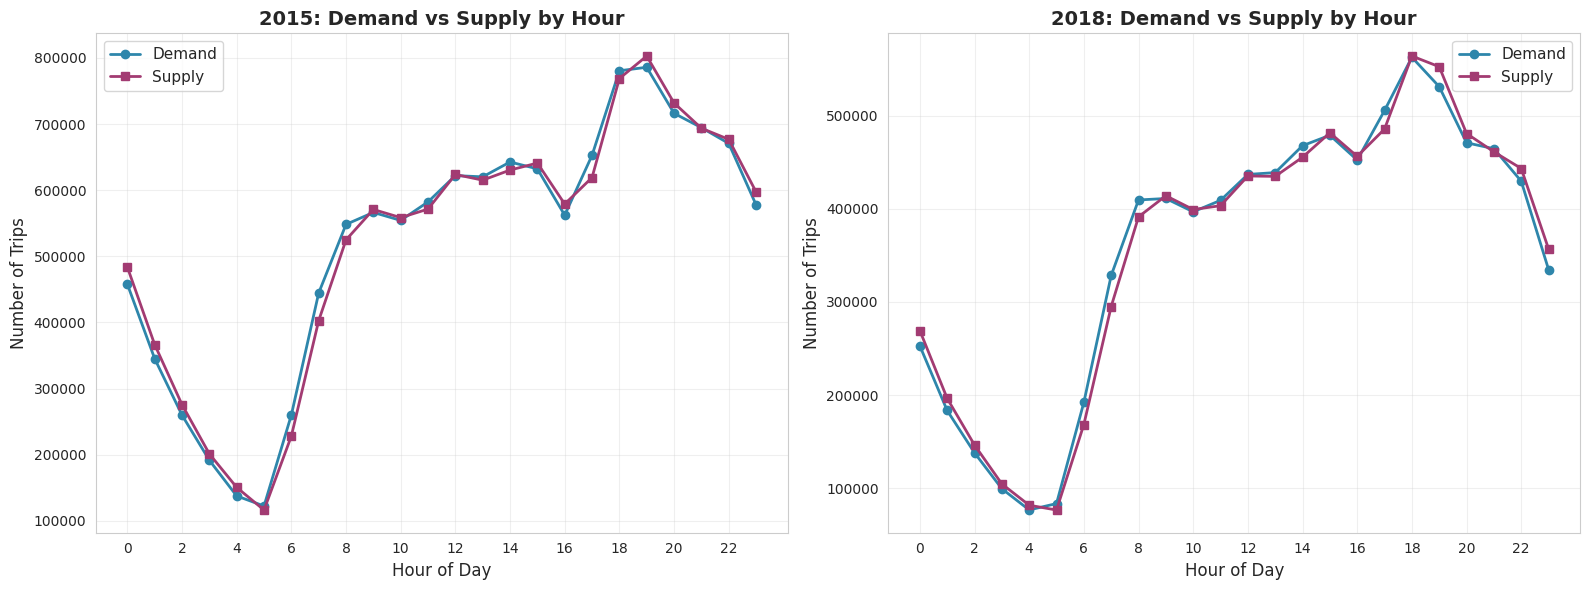

✅ Line Chart: Demand vs Supply trend by hour (2015 vs 2018)


In [0]:
# ---------- Visualization 1: Line Chart (Demand vs Supply by Hour) ----------
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Plot demand vs supply ต่อชั่วโมง เปรียบเทียบ 2015 vs 2018
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 2015
data_2015 = pd_hourly_trend[pd_hourly_trend['year'] == 2015]
axes[0].plot(data_2015['hour'], data_2015['demand'], marker='o', linewidth=2, label='Demand', color='#2E86AB')
axes[0].plot(data_2015['hour'], data_2015['supply'], marker='s', linewidth=2, label='Supply', color='#A23B72')
axes[0].set_title('2015: Demand vs Supply by Hour', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour of Day', fontsize=12)
axes[0].set_ylabel('Number of Trips', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(range(0, 24, 2))

# 2018
data_2018 = pd_hourly_trend[pd_hourly_trend['year'] == 2018]
axes[1].plot(data_2018['hour'], data_2018['demand'], marker='o', linewidth=2, label='Demand', color='#2E86AB')
axes[1].plot(data_2018['hour'], data_2018['supply'], marker='s', linewidth=2, label='Supply', color='#A23B72')
axes[1].set_title('2018: Demand vs Supply by Hour', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour of Day', fontsize=12)
axes[1].set_ylabel('Number of Trips', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

print("✅ Line Chart: Demand vs Supply trend by hour (2015 vs 2018)")

- แสดง 2 กราฟเคียงกัน: 2015 vs 2018
- เส้นสีน้ำเงิน = Demand | เส้นสีม่วง = Supply
- เห็นชัดว่า 2018 demand/supply ลดลงทั่วทุกชั่วโมง (Uber/Lyft effect)

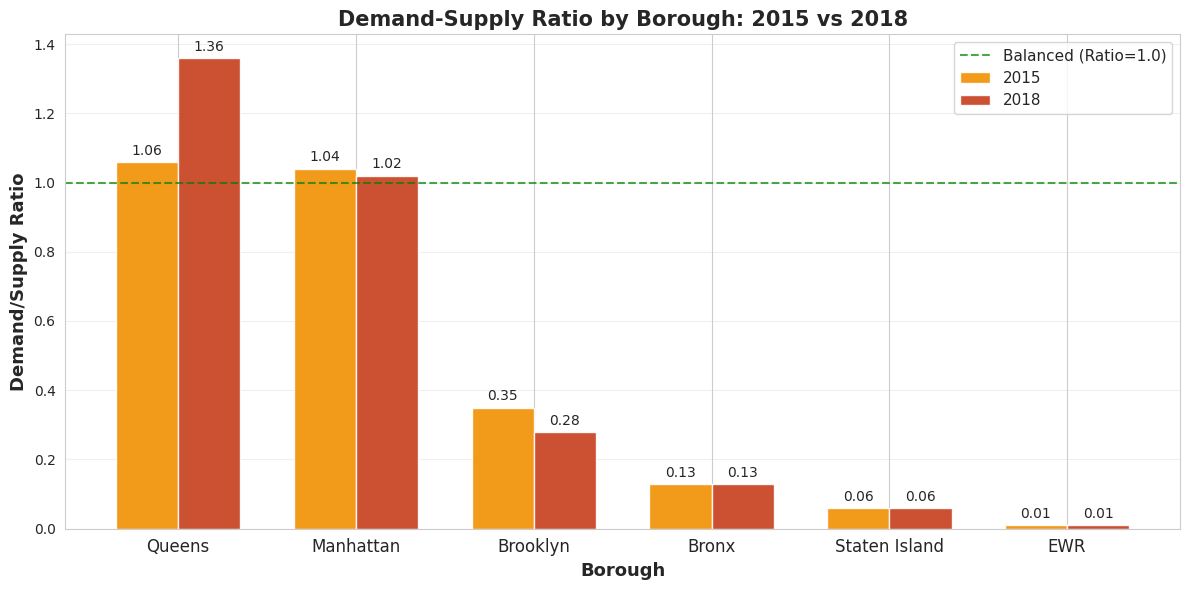

✅ Bar Chart: Demand-Supply Ratio by Borough (2015 vs 2018)


In [0]:
# ---------- Visualization 2: Bar Chart (Demand-Supply Ratio by Borough) ----------
import matplotlib.pyplot as plt
import numpy as np

# เตรียมข้อมูล
# แสดงทุก borough (รวม Staten Island และ EWR)
pd_ratio_main = pd_ratio_borough.sort_values('ratio_2015', ascending=False)

x = np.arange(len(pd_ratio_main))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

# Bar สำหรับ 2015 และ 2018
rects1 = ax.bar(x - width/2, pd_ratio_main['ratio_2015'], width, label='2015', color='#F18F01', alpha=0.9)
rects2 = ax.bar(x + width/2, pd_ratio_main['ratio_2018'], width, label='2018', color='#C73E1D', alpha=0.9)

# เพิ่มเส้น reference ที่ ratio = 1 (สมดุล)
ax.axhline(y=1.0, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='Balanced (Ratio=1.0)')

ax.set_xlabel('Borough', fontsize=13, fontweight='bold')
ax.set_ylabel('Demand/Supply Ratio', fontsize=13, fontweight='bold')
ax.set_title('Demand-Supply Ratio by Borough: 2015 vs 2018', fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(pd_ratio_main['borough'], fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

# เพิ่ม label บน bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

print("✅ Bar Chart: Demand-Supply Ratio by Borough (2015 vs 2018)")

- เปรียบเทียบ Demand-Supply Ratio แต่ละ borough (2015 vs 2018)
- Bar สีส้ม = 2015 | Bar สีแดง = 2018
- เส้นประ (สีเขียว) = Ratio = 1.0 (สมดุล)
- Queens มี imbalance เพิ่มขึ้นเด่นชัด (1.06 → 1.36)

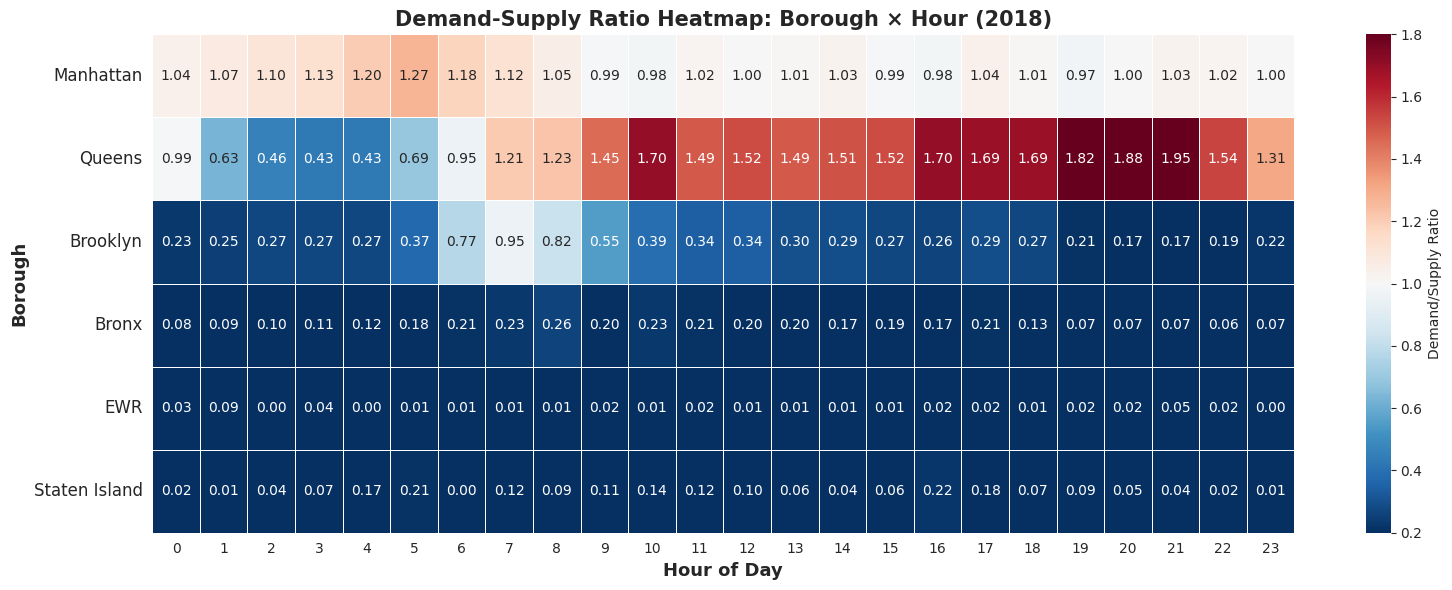

✅ Heatmap: Borough × Hour Ratio (2018)

🔴 สีแดง (Red) = Demand > Supply → ขาดแท็กซี่ (ควรจัดสรรแท็กซี่เพิ่ม)
🟢 สีเขียว/ขาว (White/Light) = Demand ≈ Supply → สมดุล
🔵 สีน้ำเงิน (Blue) = Demand < Supply → แท็กซี่ล้น (ควรย้ายไปเขตอื่น)


In [0]:
# ---------- Visualization 3: Heatmap (Borough × Hour → Ratio) ----------
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# แสดงทุก borough (รวม Staten Island และ EWR)
# เรียงตาม demand (2018) สูงสุด
# หายอก total demand สำหรับ 2018 แต่ละ borough
borough_demand_2018 = pd_heatmap.groupby('borough')['demand'].sum().sort_values(ascending=False)
pd_heatmap_sorted = pd_heatmap_pivot.reindex(borough_demand_2018.index)

# สร้าง heatmap
fig, ax = plt.subplots(figsize=(16, 6))

# ใช้ color map แบบ 3 สี: แดง (ขาดแท็กซี่) -  ขาว (สมดุล) - น้ำเงิน (แท็กซี่ล้น)
# RdBu_r = Red-Blue reversed: แดงเมื่อ ratio สูง (demand > supply), น้ำเงินเมื่อ ratio ต่ำ (supply > demand)
sns.heatmap(
    pd_heatmap_sorted,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",  # Red = high ratio (ขาดแท็กซี่), White/Green = balanced, Blue = low ratio (แท็กซี่ล้น)
    center=1.0,  # จุดกลางที่ 1.0 (สมดุล) = สีขาว/เทาอ่อน
    vmin=0.2,
    vmax=1.8,
    cbar_kws={'label': 'Demand/Supply Ratio'},
    linewidths=0.5,
    linecolor='white',
    ax=ax
)

ax.set_xlabel('Hour of Day', fontsize=13, fontweight='bold')
ax.set_ylabel('Borough', fontsize=13, fontweight='bold')
ax.set_title('Demand-Supply Ratio Heatmap: Borough × Hour (2018)', fontsize=15, fontweight='bold')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

print("✅ Heatmap: Borough × Hour Ratio (2018)")
print("\n🔴 สีแดง (Red) = Demand > Supply → ขาดแท็กซี่ (ควรจัดสรรแท็กซี่เพิ่ม)")
print("⚪ สีขาว (White/Light) = Demand ≈ Supply → สมดุล")
print("🔵 สีน้ำเงิน (Blue) = Demand < Supply → แท็กซี่ล้น (ควรย้ายไปเขตอื่น)")

## 📚 คำแนะนำ: การเลือกข้อมูลสำหรับ Visualization

### ❓ ทำไมต้องเลือกข้อมูล?

**4 borough หลัก** (Manhattan, Queens, Brooklyn, Bronx) โดยตัดออก **Staten Island** และ **EWR** 

**เหตุผล:**

1. **ข้อมูลไม่สมดุล (Data Imbalance)**
   
   จากเซลล์ที่ 30 จะเห็นว่า:
   
   | Borough | 2015 Trips | 2018 Trips | % ของทั้งหมด (2018) |
   |---------|------------|------------|---------------------|
   | Manhattan | 11,567,108 | 7,932,556 | **~95%** |
   | Queens | 625,474 | 515,969 | ~6% |
   | Brooklyn | 226,617 | 98,387 | ~1% |
   | Bronx | 8,929 | 6,653 | ~0.08% |
   | **Staten Island** | **150** | **108** | **~0.001%** |
   | **EWR** | **216** | **167** | **~0.002%** |
   
   Staten Island และ EWR มีข้อมูลน้อยมาก (**< 0.01%** ของทั้งหมด) ทำให้:
   * **Bar Chart**: ค่า ratio ของ 2 เขตนี้มีความไม่แน่นอนสูง (uncertainty) เพราะข้อมูลน้อย
   * **Heatmap**: หลาย hour จะเป็น NaN หรือค่าที่ผันผวนมาก ทำให้รูปแบบไม่ชัดเจน

2. **ความชัดเจนของ Visualization**
   
   * ถ้าแสดงทั้ง 6 เขต → กราฟจะมี 6 bars หรือ 6 rows
   * แต่จริงๆ แล้ว **Manhattan เป็น 95% ของข้อมูล** → 4 เขตที่เหลือมองไม่เห็นชัดเจน
   * Staten Island/EWR มีข้อมูลน้อยเกินไป → สร้าง "noise" ในกราฟมากกว่าให้ insight

3. **Focus on Signal, Not Noise**
   
   * เป้าหมายคือดู **pattern ของ demand/supply imbalance**
   * 4 เขตหลักมีข้อมูลเพียงพอที่จะวิเคราะห์ pattern ได้น่าเชื่อถือ
   * Staten Island/EWR มีข้อมูลน้อยเกินไป → pattern ที่เห็นอาจเป็นแค่ random noise

---

### 🎯 หลักการเลือกข้อมูลสำหรับ Visualization

#### 1. **ดูการกระจายของข้อมูล (Data Distribution)**

```python
# ตัวอย่าง: นับจำนวน trips ต่อ borough
df_clean.groupBy("pickup_borough").count().orderBy(col("count").desc()).show()
```

**เกณฑ์ทั่วไป:**
* ถ้ากลุ่มใดมี **< 1%** ของข้อมูลทั้งหมด → พิจารณากรองออก
* ถ้ากลุ่มใดมี **< 100 samples** → ไม่น่าเชื่อถือสำหรับวิเคราะห์ pattern
* ถ้ามี **outlier groups ที่มากหรือน้อยเกินไป** → อาจทำให้ scale ของกราฟผิดเพี้ยน

#### 2. **เลือกตามวัตถุประสงค์ (Purpose)**

* **Exploratory Analysis (สำรวจ)**: แสดงทุกกลุ่มเพื่อดูภาพรวม
  * ✅ ใช้เมื่อ: ยังไม่รู้ว่ามี pattern อะไร
  * ✅ ตัวอย่าง: เซลล์ที่ 30 (แสดงทุก borough เป็นตาราง)

* **Comparative Analysis (เปรียบเทียบ)**: แสดงเฉพาะกลุ่มที่มีข้อมูลเพียงพอ
  * ✅ ใช้เมื่อ: ต้องการเปรียบเทียบ pattern ระหว่างกลุ่ม
  * ✅ ตัวอย่าง: เซลล์ที่ 36, 38, 40 (กราฟแสดง 4 borough หลัก)

* **Presentation (นำเสนอ)**: แสดงเฉพาะกลุ่มที่สำคัญและมี insight ชัดเจน
  * ✅ ใช้เมื่อ: นำเสนอต่อผู้บริหารหรือลูกค้า
  * ✅ ตัวอย่าง: แสดงแค่ Manhattan และ Queens (2 เขตที่มี demand สูงสุด)

#### 3. **ประเภทของกราฟ (Visualization Type)**

* **Bar Chart**: เหมาะกับการเปรียบเทียบ **3–7 กลุ่ม**
  * มากเกิน → กราฟแน่น อ่านยาก
  * น้อยเกิน → ไม่เห็นการเปรียบเทียบ

* **Heatmap**: ต้องการข้อมูล **ครบทุก cell**
  * ถ้ามี NaN หรือ 0 เยอะ → สีจะไม่สม่ำเสมอ
  * ใช้กับกลุ่มที่มีข้อมูลเพียงพอในทุก time slot

* **Line Chart**: เหมาะกับการดู **trend ข้ามเวลา**
  * ข้อมูลต้องต่อเนื่อง (ไม่ขาดช่วง)
  * เหมาะกับ aggregation ระดับสูง (รวมทุก borough)

---

### ✅ ข้อดี-ข้อเสีย ของการกรองข้อมูล

#### **กรองเฉพาะกลุ่มหลัก (เดิม: 4 borough)**

✅ **ข้อดี:**
* กราฟชัดเจน อ่านง่าย
* Focus ที่ pattern ที่น่าเชื่อถือ
* Scale เหมาะสม (ไม่มี outlier ทำให้เห็นไม่ชัด)

❌ **ข้อเสีย:**
* ข้อมูลไม่ครบถ้วน
* อาจพลาดข้อมูลที่น่าสนใจ (แม้จะน้อย)
* ต้องอธิบายว่าทำไมถึงกรอง

#### **แสดงทุกกลุ่ม (ใหม่: 6 borough)**

✅ **ข้อดี:**
* ครบถ้วน โปร่งใส
* เห็นภาพรวมทั้งหมด
* ไม่ต้องตัดสินใจว่าอันไหนสำคัญ

❌ **ข้อเสีย:**
* กราฟอาจรก (Staten Island/EWR มี pattern ไม่ชัด)
* Scale อาจผิดเพี้ยน
* อาจสร้างความสับสนมากกว่าให้ insight

---

### 🔍 แนวทางที่แนะนำ

**สำหรับโปรเจกต์นักศึกษา:**

1. **เริ่มต้นด้วยการแสดงทั้งหมด** (exploratory)
   * ใช้ตารางหรือ summary statistics
   * ตัวอย่าง: เซลล์ที่ 30 แสดงทั้ง 6 borough

2. **ระบุเกณฑ์การกรอง** (transparent criteria)
   * เช่น: "แสดงเฉพาะ borough ที่มี > 1% ของ trips"
   * อธิบายเหตุผล: "Staten Island และ EWR มี < 0.01% → ไม่เพียงพอสำหรับวิเคราะห์ pattern"

3. **สร้าง 2 versions** (ถ้าจำเป็น)
   * Version 1: แสดงทุกกลุ่ม (ครบถ้วน)
   * Version 2: แสดงเฉพาะกลุ่มหลัก (ชัดเจน)

4. **ใส่ Summary Statistics เสริม**
   * เช่น: "Staten Island: 108 trips (0.001% ของทั้งหมด)"
   * ทำให้ผู้อ่านรู้ว่าไม่ได้ลืมข้อมูลนั้น

---

### 📊 สรุป: เซลล์ 34–40 ของเรา

**สิ่งที่ทำ (ตอนนี้):**
* เซลล์ 30–33: แสดง**ทุก borough** (รวม Staten Island, EWR) ในรูปตาราง text
* เซลล์ 36, 38, 40: แสดง**ทุก borough** (หลังจากแก้ไข) ในกราฟ

**ทำไมถึงเหมาะสม:**
* ตาราง text (เซลล์ 30–33) → อ่านได้ละเอียด รองรับทุกกลุ่ม
* กราฟ (เซลล์ 36, 38, 40) → ตอนนี้แสดงครบแล้ว แม้จะมีบาง borough ที่ข้อมูลน้อย

**ข้อควรระวัง:**
* Staten Island และ EWR อาจมีค่า ratio ที่ผันผวน → อย่าตีความ pattern จากกลุ่มนี้จนเกินไป
* ถ้านำเสนอ → อาจต้องอธิบายว่า 2 เขตนี้มีข้อมูลน้อยมาก

---

### 💡 ข้อเสนอแนะเพิ่มเติม

**ถ้าต้องการวิเคราะห์ต่อ:**

1. **สร้าง Statistical Significance Test**
   * ทดสอบว่าความแตกต่างของ ratio ในแต่ละ borough มีนัยสำคัญทางสถิติหรือไม่
   * เช่น: Queens ratio เพิ่มจาก 1.06 → 1.36 มีนัยสำคัญไหม? (ใช่)
   * Staten Island ratio คงที่ 0.06 มีนัยสำคัญไหม? (อาจไม่ เพราะข้อมูลน้อย)

2. **ใช้ Confidence Interval**
   * แสดง error bars ในกราฟ
   * borough ที่มีข้อมูลน้อย → error bar จะกว้าง → แสดงความไม่แน่นอน

3. **สร้าง Filter Widget ใน Dashboard**
   * ให้ผู้ใช้เลือกเองว่าจะดู borough ไหน
   * เหมาะสำหรับ interactive dashboard

**หวังว่าจะช่วยให้เข้าใจการเลือกข้อมูลสำหรับ visualization ได้มากขึ้นนะ! 🎓**

**ผลลัพธ์:**

- ทั้ง 3 visualization แสดงออกชัดว่า Queens มี demand/supply imbalance เพิ่มขึ้น
- Manhattan ยังสมดุลดี แม้ demand จะลด
- Brooklyn/Bronx มี supply มากกว่า demand (รถไปส่งแต่ไม่ได้รับผู้โดยสารใหม่)

# 5.Insight Extraction: การจัดสรรแท็กซี่

วิเคราะห์ข้อมูลเพื่อตอบคำถาม:
1. **เขตไหนมี supply > demand (แท็กซี่ล้น)** → ควรย้ายรถไปเขตอื่น
2. **เขตไหนมี demand > supply (แท็กซี่ขาด)** → ควรเพิ่มรถในเขตนี้
3. **Rush hour pattern (เช้า–เย็น)** → ช่วงเวลาไหนต้องจัดสรรเร่ง
4. **Weekend vs Weekday** → วันธรรมดา vs สุดสัปดาห์ต่างกันยังไง

**ใช้ข้อมูลปี 2018** (ปีล่าสุดใน dataset) เพื่อให้สะท้อนสถานการณ์ล่าสุด

In [0]:
# ---------- Insight 1: เขตไหนแท็กซี่ล้น / ขาด (2018) ----------
# วิเคราะห์ทุก borough: demand, supply, ratio และจำแนก 3 สถานะ

from pyspark.sql.functions import col, count, sum as F_sum, round as F_round, when

# Demand: pickup ต่อ borough (2018)
df_demand_borough = (
    df_clean
    .filter((col("pickup_borough").isNotNull()) & (col("pickup_borough") != "Unknown") & (col("year") == 2018))
    .groupBy("pickup_borough")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
)

# Supply: dropoff ต่อ borough (2018)
df_supply_borough = (
    df_clean
    .filter((col("dropoff_borough").isNotNull()) & (col("dropoff_borough") != "Unknown") & (col("year") == 2018))
    .groupBy("dropoff_borough")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
)

# Join และคำนวณ ratio
df_borough_2018 = df_demand_borough.join(df_supply_borough, on="borough", how="outer")
df_borough_2018 = df_borough_2018.na.fill({"demand": 0, "supply": 0})
df_borough_2018 = df_borough_2018.withColumn(
    "ratio", F_round(col("demand") / col("supply"), 2)
).withColumn(
    "status",
    when(col("ratio") > 1.2, "🔴 ขาดแท็กซี่")
    .when(col("ratio") < 0.8, "🔵 แท็กซี่ล้น")
    .otherwise("🟢 สมดุล")
).orderBy(col("demand").desc())

# แสดงผล
print("=== Insight 1: สถานะแท็กซี่แต่ละเขต (2018) ===")
print()
print(f"{'Borough':<16} {'Demand':>12} {'Supply':>12} {'Ratio':>8} {'Status':<25}")
print("-" * 75)

for row in df_borough_2018.collect():
    b = row["borough"]
    d = row["demand"]
    s = row["supply"]
    r = row["ratio"]
    status = row["status"]
    print(f"{b:<16} {d:>12,} {s:>12,} {r:>8.2f} {status}")

# สรุป
print()
print("--- สรุปการจัดสรร ---")
shortage = df_borough_2018.filter(col("ratio") > 1.2).collect()
overflow = df_borough_2018.filter(col("ratio") < 0.8).collect()
balanced = df_borough_2018.filter((col("ratio") >= 0.8) & (col("ratio") <= 1.2)).collect()

print(f"\n🔴 ขาดแท็กซี่ (Demand > Supply): {len(shortage)} เขต")
for r in shortage:
    print(f"   {r['borough']}: ratio = {r['ratio']} (demand {r['demand']:,} vs supply {r['supply']:,})")

print(f"\n🔵 แท็กซี่ล้น (Supply > Demand): {len(overflow)} เขต")
for r in overflow:
    print(f"   {r['borough']}: ratio = {r['ratio']} (demand {r['demand']:,} vs supply {r['supply']:,})")

print(f"\n🟢 สมดุล (Demand ≈ Supply): {len(balanced)} เขต")
for r in balanced:
    print(f"   {r['borough']}: ratio = {r['ratio']} (demand {r['demand']:,} vs supply {r['supply']:,})")

=== Insight 1: สถานะแท็กซี่แต่ละเขต (2018) ===

Borough                Demand       Supply    Ratio Status                   
---------------------------------------------------------------------------
Manhattan           7,932,556    7,752,410     1.02 🟢 สมดุล
Queens                515,969      379,809     1.36 🔴 ขาดแท็กซี่
Brooklyn               98,387      355,507     0.28 🔵 แท็กซี่ล้น
Bronx                   6,653       50,181     0.13 🔵 แท็กซี่ล้น
EWR                       167       13,488     0.01 🔵 แท็กซี่ล้น
Staten Island             108        1,698     0.06 🔵 แท็กซี่ล้น

--- สรุปการจัดสรร ---

🔴 ขาดแท็กซี่ (Demand > Supply): 1 เขต
   Queens: ratio = 1.36 (demand 515,969 vs supply 379,809)

🔵 แท็กซี่ล้น (Supply > Demand): 4 เขต
   Brooklyn: ratio = 0.28 (demand 98,387 vs supply 355,507)
   Bronx: ratio = 0.13 (demand 6,653 vs supply 50,181)
   EWR: ratio = 0.01 (demand 167 vs supply 13,488)
   Staten Island: ratio = 0.06 (demand 108 vs supply 1,698)

🟢 สมดุล (Demand ≈ Supply):

In [0]:
# ---------- Insight 2: Rush Hour Pattern (เช้า–เย็น) ----------
# แบ่งช่วงเวลา: Morning Rush (7-9) | Evening Rush (17-19) | Off-peak (อื่นๆ)
# ดูว่าแต่ละ borough มี imbalance ตอนไหนเดนชัด

from pyspark.sql.functions import col, count, sum as F_sum, round as F_round, when

# สร้างคอลัมน์ time_period
df_rush = df_clean.filter(
    (col("year") == 2018) &
    (col("pickup_borough").isNotNull()) & (col("pickup_borough") != "Unknown") &
    (col("dropoff_borough").isNotNull()) & (col("dropoff_borough") != "Unknown")
).withColumn(
    "time_period",
    when(col("pickup_hour").between(7, 9), "Morning Rush (7-9)")
    .when(col("pickup_hour").between(17, 19), "Evening Rush (17-19)")
    .otherwise("Off-peak (อื่นๆ)")
)

# Demand ต่อ borough ต่อ time_period
df_rush_demand = (
    df_rush
    .groupBy("pickup_borough", "time_period")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
)

# Supply ต่อ borough ต่อ time_period (ใช้ dropoff_hour)
df_rush_supply = (
    df_rush
    .withColumn("time_period_supply",
        when(col("dropoff_hour").between(7, 9), "Morning Rush (7-9)")
        .when(col("dropoff_hour").between(17, 19), "Evening Rush (17-19)")
        .otherwise("Off-peak (อื่นๆ)")
    )
    .groupBy("dropoff_borough", "time_period_supply")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
    .withColumnRenamed("time_period_supply", "time_period")
)

# Join
df_rush_ds = df_rush_demand.join(df_rush_supply, on=["borough", "time_period"], how="outer")
df_rush_ds = df_rush_ds.na.fill({"demand": 0, "supply": 0})
df_rush_ds = df_rush_ds.withColumn(
    "ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2)
).withColumn(
    "status",
    when(col("ratio") > 1.2, "🔴 ขาด")
    .when(col("ratio") < 0.8, "🔵 ล้น")
    .when(col("ratio").isNull(), "—")
    .otherwise("🟢 สมดุล")
).orderBy("borough", "time_period")

# แสดงผลแยกตาม borough
print("=== Insight 2: Rush Hour Pattern แต่ละเขต (2018) ===")
print()

boroughs = [r["borough"] for r in df_rush_ds.select("borough").distinct().orderBy("borough").collect()]
periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]

for b in boroughs:
    print(f"--- {b} ---")
    print(f"{'Period':<25} {'Demand':>10} {'Supply':>10} {'Ratio':>8} {'Status':<15}")
    print("-" * 70)
    for p in periods:
        row = df_rush_ds.filter((col("borough") == b) & (col("time_period") == p)).collect()
        if row:
            r = row[0]
            d = r["demand"]
            s = r["supply"]
            ratio = r["ratio"] if r["ratio"] is not None else 0
            status = r["status"]
            print(f"{p:<25} {d:>10,} {s:>10,} {ratio:>8.2f} {status}")
    print()

# สรุป rush hour ที่ขาดแท็กซี่มากที่สุด
print("--- สรุป: เขตที่ขาดแท็กซี่มากที่สุดในแต่ละช่วง ---")
for p in periods:
    worst = df_rush_ds.filter((col("time_period") == p) & (col("ratio") > 1.2)).orderBy(col("ratio").desc()).collect()
    if worst:
        print(f"\n{p}:")
        for r in worst[:3]:
            print(f"   🔴 {r['borough']}: ratio = {r['ratio']} (demand {r['demand']:,} vs supply {r['supply']:,})")
    else:
        print(f"\n{p}: ไม่มีเขตที่ขาดแท็กซี่")

=== Insight 2: Rush Hour Pattern แต่ละเขต (2018) ===

--- Bronx ---
Period                        Demand     Supply    Ratio Status         
----------------------------------------------------------------------
Morning Rush (7-9)             1,283      5,548     0.23 🔵 ล้น
Evening Rush (17-19)             802      6,194     0.13 🔵 ล้น
Off-peak (อื่นๆ)               4,507     38,328     0.12 🔵 ล้น

--- Brooklyn ---
Period                        Demand     Supply    Ratio Status         
----------------------------------------------------------------------
Morning Rush (7-9)            15,249     20,098     0.76 🔵 ล้น
Evening Rush (17-19)          13,894     55,520     0.25 🔵 ล้น
Off-peak (อื่นๆ)              69,026    279,105     0.25 🔵 ล้น

--- EWR ---
Period                        Demand     Supply    Ratio Status         
----------------------------------------------------------------------
Morning Rush (7-9)                20      1,934     0.01 🔵 ล้น
Evening Rush (17-19)        

In [0]:
# ---------- Insight 3: Weekend vs Weekday ----------
# เปรียบเทียบ demand/supply ระหว่างวันธรรมดา (Mon-Fri) vs สุดสัปดาห์ (Sat-Sun)
# df_clean มีคอลัมน์ is_weekend (1=Sat/Sun, 0=Mon-Fri) อยู่แล้ว

from pyspark.sql.functions import col, count, sum as F_sum, round as F_round, when

df_wknd = df_clean.filter(
    (col("year") == 2018) &
    (col("pickup_borough").isNotNull()) & (col("pickup_borough") != "Unknown") &
    (col("dropoff_borough").isNotNull()) & (col("dropoff_borough") != "Unknown")
)

# Demand: pickup ต่อ borough × is_weekend
df_wknd_demand = (
    df_wknd
    .groupBy("pickup_borough", "is_weekend")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_borough", "borough")
    .withColumn("day_type", when(col("is_weekend") == 1, "Weekend").otherwise("Weekday"))
)

# Supply: dropoff ต่อ borough × is_weekend
df_wknd_supply = (
    df_wknd
    .groupBy("dropoff_borough", "is_weekend")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_borough", "borough")
    .withColumn("day_type", when(col("is_weekend") == 1, "Weekend").otherwise("Weekday"))
)

# Join
df_wknd_ds = df_wknd_demand.join(df_wknd_supply, on=["borough", "is_weekend", "day_type"], how="outer")
df_wknd_ds = df_wknd_ds.na.fill({"demand": 0, "supply": 0})
df_wknd_ds = df_wknd_ds.withColumn(
    "ratio", F_round(when(col("supply") > 0, col("demand") / col("supply")).otherwise(None), 2)
).withColumn(
    "status",
    when(col("ratio") > 1.2, "🔴 ขาด")
    .when(col("ratio") < 0.8, "🔵 ล้น")
    .when(col("ratio").isNull(), "—")
    .otherwise("🟢 สมดุล")
).orderBy("borough", "is_weekend")

# แสดงผล
print("=== Insight 3: Weekend vs Weekday (2018) ===")
print()

boroughs = [r["borough"] for r in df_wknd_ds.select("borough").distinct().orderBy("borough").collect()]

for b in boroughs:
    print(f"--- {b} ---")
    print(f"{'Day Type':<12} {'Demand':>12} {'Supply':>12} {'Ratio':>8} {'Status':<15}")
    print("-" * 65)
    for dt in ["Weekday", "Weekend"]:
        row = df_wknd_ds.filter((col("borough") == b) & (col("day_type") == dt)).collect()
        if row:
            r = row[0]
            d = r["demand"]
            s = r["supply"]
            ratio = r["ratio"] if r["ratio"] is not None else 0
            status = r["status"]
            print(f"{dt:<12} {d:>12,} {s:>12,} {ratio:>8.2f} {status}")
    print()

# สรุปความแตกต่าง Weekday vs Weekend
print("--- สรุป: ความแตกต่าง Weekday vs Weekend ---")
print(f"{'Borough':<16} {'Ratio WD':>10} {'Ratio WE':>10} {'Diff':>10} {'สรุป':<30}")
print("-" * 80)

for b in boroughs:
    wd = df_wknd_ds.filter((col("borough") == b) & (col("day_type") == "Weekday")).collect()
    we = df_wknd_ds.filter((col("borough") == b) & (col("day_type") == "Weekend")).collect()
    
    wd_ratio = wd[0]["ratio"] if wd and wd[0]["ratio"] is not None else 0
    we_ratio = we[0]["ratio"] if we and we[0]["ratio"] is not None else 0
    diff = we_ratio - wd_ratio
    
    if abs(diff) < 0.05:
        summary = "≈ เหมือนกัน"
    elif diff > 0:
        summary = f"Weekend ขาดแท็กซี่มากขึ้น ({diff:+.2f})"
    else:
        summary = f"Weekend ล้นแท็กซี่มากขึ้น ({diff:+.2f})"
    
    print(f"{b:<16} {wd_ratio:>10.2f} {we_ratio:>10.2f} {diff:>+10.2f} {summary}")

=== Insight 3: Weekend vs Weekday (2018) ===

--- Bronx ---
Day Type           Demand       Supply    Ratio Status         
-----------------------------------------------------------------
Weekday             4,691       35,414     0.13 🔵 ล้น
Weekend             1,901       14,656     0.13 🔵 ล้น

--- Brooklyn ---
Day Type           Demand       Supply    Ratio Status         
-----------------------------------------------------------------
Weekday            67,898      253,347     0.27 🔵 ล้น
Weekend            30,271      101,376     0.30 🔵 ล้น

--- EWR ---
Day Type           Demand       Supply    Ratio Status         
-----------------------------------------------------------------
Weekday               120       10,326     0.01 🔵 ล้น
Weekend                37        3,068     0.01 🔵 ล้น

--- Manhattan ---
Day Type           Demand       Supply    Ratio Status         
-----------------------------------------------------------------
Weekday         5,888,626    5,764,228     1.0

## 📋 คำอธิบายเซลล์ Insight Extraction

| เซลล์ | ชื่อ | วิเคราะห์อะไร | ตอบคำถาม |
|---|---|---|---|
| Insight 1 | Overflow vs Shortage | demand, supply, ratio และ status แต่ละเขต | เขตไหนแท็กซี่ล้น/ขาด? |
| Insight 2 | Rush Hour Pattern | Morning Rush (7-9) vs Evening Rush (17-19) vs Off-peak | ช่วงไหนต้องจัดสรรเร่ง? |
| Insight 3 | Weekend vs Weekday | Weekday (Mon-Fri) vs Weekend (Sat-Sun) | วันธรรมดา vs สุดสัปดาห์ต่างกันไหม? |

**วิธีใช้ผลลัพธ์:**
* ดู Insight 1 เพื่อรู้ภาพรวมว่าเขตไหนขาด/ล้น
* ดู Insight 2 เพื่อรู้ว่าช่วง rush hour ไหนต้องเพิ่มรถ
* ดู Insight 3 เพื่อปรับแผนจัดสรรตามวัน
* นำข้อมูลไปจัดสรรแท็กซี่ เช่น ย้ายรถจากเขตที่ล้น (🔵) ไปยังเขตที่ขาด (🔴) ในช่วง rush hour

**สรุป: มีแค่ Queens ที่ขาดแท็กซี่ ส่วน Brooklyn, Bronx, EWR, Staten Island แท็กซี่ล้นทั้งหมด**

**🕐 Insight 2:** Rush Hour Pattern
- Queens ขาดแท็กซี่ทุกช่วง โดย Evening Rush (17-19) รุนแรงที่สุด:
- Morning Rush (7-9): ratio 1.28 🔴
- Evening Rush (17-19): ratio 1.71 🔴 ← เลวร้ายที่สุด
- Off-peak: ratio 1.28 🔴
- Manhattan สมดุลทุกช่วง (ratio 1.01–1.05) 🟢

**📅 Insight 3:** Weekend vs Weekday
Queens เป็นเขตเดียวที่ต่างกัน: Weekday ratio 1.37 → Weekend ratio 1.25 (ลดลง -0.12) แปลว่า สุดสัปดาห์ Queens ล้นแท็กซี่มากขึ้น (คนเรียกน้อยลงในวันหยุด)
ทุกเขตอื่น ≈ เหมือนกันทั้งวันธรรมดาและสุดสัปดาห์
🎯 ข้อเสนอแนะการจัดสรร
- ย้ายรถจาก Brooklyn → Queens ในช่วง Evening Rush (17-19) เพราะ Brooklyn ล้น (ratio 0.25) แต่ Queens ขาด (ratio 1.71)
- Bronx มี supply มากกว่า demand 7.5 เท่า → รถส่วนใหญ่ไปส่งแล้วไม่รับผู้โดยสารใหม่
- สุดสัปดาห์ Queens ค่อนข้างสมดุลขึ้น → ลดการจัดสรรพิเศษในวันหยุดได้

## 📊 Visualization สำหรับ Insight Extraction

ใช้สี 3 ระดับเหมือนเดิม:
- 🟢 **เขียว** = สมดุล (ratio ≈ 1, 0.8–1.2)
- 🔴 **แดง** = ขาดแท็กซี่ (ratio > 1.2, demand > supply)
- 🔵 **น้ำเงิน** = แท็กซี่ล้น (ratio < 0.8, supply > demand)

/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782022-1595830721:71: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782022-1595830721:71: UserWarning: Glyph 3635 (\N{THAI CHARACTER SARA AM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782022-1595830721:71: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782022-1595830721:71: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782022-1595830721:71: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) DejaVu Sans.
  plt.tight_layou

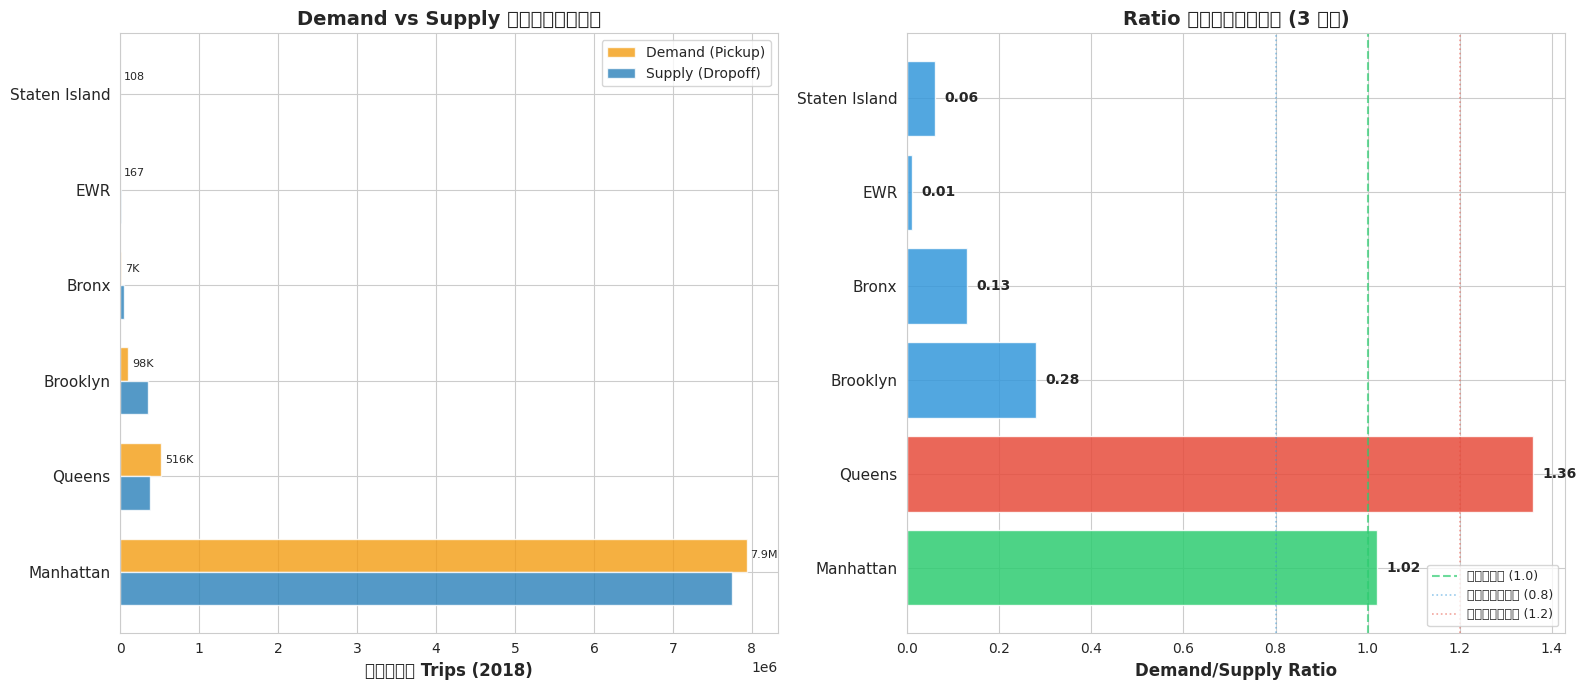

✅ Viz 4: Demand vs Supply + Ratio by Borough (2018)
🔴 แดง = ขาดแท็กซี่ | 🟢 เขียว = สมดุล | 🔵 น้ำเงิน = แท็กซี่ล้น


In [0]:
# ---------- Viz 4: Demand vs Supply by Borough (Insight 1) ----------
import matplotlib.pyplot as plt
import numpy as np

# แปลงเป็น pandas
pd_borough = df_borough_2018.toPandas().sort_values("demand", ascending=True)

# กำหนดสีตาม status: 🟢 สมดุล | 🔴 ขาด | 🔵 ล้น
def get_color(ratio):
    if ratio > 1.2:
        return "#e74c3c"  # แดง
    elif ratio < 0.8:
        return "#3498db"  # น้ำเงิน
    else:
        return "#2ecc71"  # เขียว

colors = [get_color(r) for r in pd_borough["ratio"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Subplot 1: Demand vs Supply (grouped bar) ---
ax1 = axes[0]
y_pos = np.arange(len(pd_borough))
bar_height = 0.35

bars1 = ax1.barh(y_pos - bar_height/2, pd_borough["demand"], bar_height,
                 color="#f39c12", alpha=0.8, label="Demand (Pickup)")
bars2 = ax1.barh(y_pos + bar_height/2, pd_borough["supply"], bar_height,
                 color="#2980b9", alpha=0.8, label="Supply (Dropoff)")

ax1.set_yticks(y_pos)
ax1.set_yticklabels(pd_borough["borough"], fontsize=11)
ax1.set_xlabel("จำนวน Trips (2018)", fontsize=12, fontweight="bold")
ax1.set_title("Demand vs Supply แต่ละเขต", fontsize=14, fontweight="bold")
ax1.legend(fontsize=10)
ax1.invert_yaxis()

# ใส่ค่าที่ปลาย bar (format เป็น K/M)
for bar, val in zip(bars1, pd_borough["demand"]):
    if val >= 1_000_000:
        ax1.text(bar.get_width() + 50000, bar.get_y() + bar.get_height()/2,
                f"{val/1_000_000:.1f}M", va="center", fontsize=8)
    elif val >= 1_000:
        ax1.text(bar.get_width() + 50000, bar.get_y() + bar.get_height()/2,
                f"{val/1_000:.0f}K", va="center", fontsize=8)
    else:
        ax1.text(bar.get_width() + 50000, bar.get_y() + bar.get_height()/2,
                f"{val:.0f}", va="center", fontsize=8)

# --- Subplot 2: Ratio with 3-color status ---
ax2 = axes[1]
bars3 = ax2.barh(y_pos, pd_borough["ratio"], color=colors, alpha=0.85, edgecolor="white")

# เส้นอ้างอิง: 0.8 (ล้น), 1.0 (สมดุล), 1.2 (ขาด)
ax2.axvline(x=1.0, color="#2ecc71", linestyle="--", linewidth=1.5, alpha=0.7, label="สมดุล (1.0)")
ax2.axvline(x=0.8, color="#3498db", linestyle=":", linewidth=1.2, alpha=0.5, label="ขั้นล้น (0.8)")
ax2.axvline(x=1.2, color="#e74c3c", linestyle=":", linewidth=1.2, alpha=0.5, label="ขั้นขาด (1.2)")

ax2.set_yticks(y_pos)
ax2.set_yticklabels(pd_borough["borough"], fontsize=11)
ax2.set_xlabel("Demand/Supply Ratio", fontsize=12, fontweight="bold")
ax2.set_title("Ratio แต่ละเขต (3 สี)", fontsize=14, fontweight="bold")
ax2.legend(fontsize=9, loc="lower right")
ax2.invert_yaxis()

# ใส่ค่า ratio ที่ปลาย bar
for bar, val in zip(bars3, pd_borough["ratio"]):
    ax2.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

print("✅ Viz 4: Demand vs Supply + Ratio by Borough (2018)")
print("🔴 แดง = ขาดแท็กซี่ | 🟢 เขียว = สมดุล | 🔵 น้ำเงิน = แท็กซี่ล้น")

/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782026-3777685865:51: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782026-3777685865:51: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782026-3777685865:51: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782026-3777685865:51: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782026-3777685865:51: UserWarning: Glyph 3632 (\N{THAI CHARACTER SARA A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

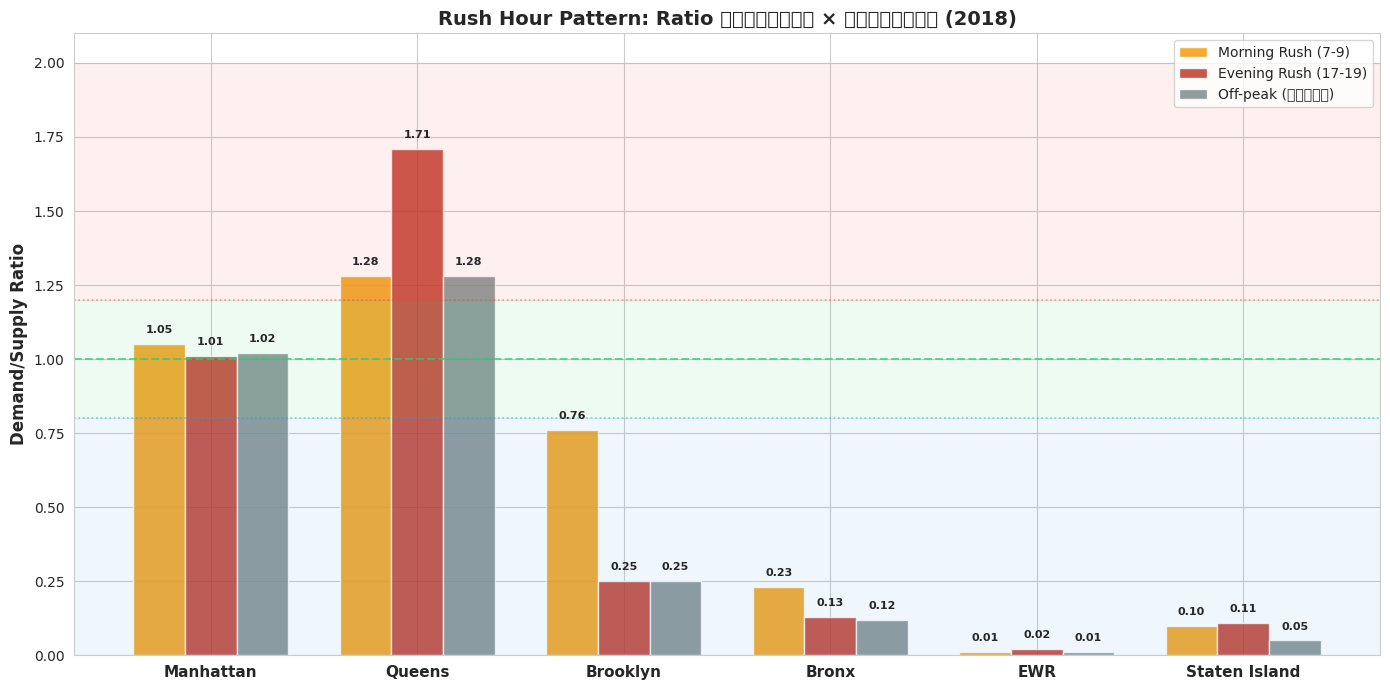

✅ Viz 5: Rush Hour Ratio by Borough (2018)
เส้นประเขียว = สมดุล (1.0) | เส้นจุดแดง = ขั้นขาด (1.2) | เส้นจุดน้ำเงิน = ขั้นล้น (0.8)
พื้นหลังเขียว = โซนสมดุล | พื้นหลังแดง = โซนขาด | พื้นหลังน้ำเงิน = โซนล้น


In [0]:
# ---------- Viz 5: Rush Hour Ratio by Borough (Insight 2) ----------
import matplotlib.pyplot as plt
import numpy as np

# แปลงเป็น pandas
pd_rush = df_rush_ds.toPandas()

# pivot: borough × time_period → ratio
pivot_rush = pd_rush.pivot_table(index="borough", columns="time_period", values="ratio")
# เรียงตาม demand รวม (สูงสุ่ง่ำก่อน)
order = pd_rush.groupby("borough")["demand"].sum().sort_values(ascending=False).index
pivot_rush = pivot_rush.reindex(order)

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]
pivot_rush = pivot_rush[periods]

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(pivot_rush))
width = 0.25

# สีแต่ละช่วงเวลา: เช้า=ส้ม, เย็น=แดงเข้ม, off-peak=เทา
period_colors = ["#f39c12", "#c0392b", "#7f8c8d"]

for i, (period, color) in enumerate(zip(periods, period_colors)):
    values = pivot_rush[period].values
    bars = ax.bar(x + i * width, values, width, label=period, color=color, alpha=0.85, edgecolor="white")
    
    # ใส่ค่า ratio บน bar
    for bar, val in zip(bars, values):
        if not np.isnan(val):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03,
                    f"{val:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

# เส้นอ้างอิง
ax.axhline(y=1.0, color="#2ecc71", linestyle="--", linewidth=1.5, alpha=0.7)
ax.axhline(y=1.2, color="#e74c3c", linestyle=":", linewidth=1.2, alpha=0.5)
ax.axhline(y=0.8, color="#3498db", linestyle=":", linewidth=1.2, alpha=0.5)

ax.set_xticks(x + width)
ax.set_xticklabels(pivot_rush.index, fontsize=11, fontweight="bold")
ax.set_ylabel("Demand/Supply Ratio", fontsize=12, fontweight="bold")
ax.set_title("Rush Hour Pattern: Ratio แต่ละเขต × ช่วงเวลา (2018)", fontsize=14, fontweight="bold")
ax.legend(fontsize=10, loc="upper right")

# ใส่สีพื้นหลังตามโซน
ax.axhspan(0.8, 1.2, alpha=0.08, color="#2ecc71", label="โซนสมดุล")
ax.axhspan(1.2, 2.0, alpha=0.08, color="#e74c3c", label="โซนขาด")
ax.axhspan(0, 0.8, alpha=0.08, color="#3498db", label="โซนล้น")

plt.tight_layout()
plt.show()

print("✅ Viz 5: Rush Hour Ratio by Borough (2018)")
print("เส้นประเขียว = สมดุล (1.0) | เส้นจุดแดง = ขั้นขาด (1.2) | เส้นจุดน้ำเงิน = ขั้นล้น (0.8)")
print("พื้นหลังเขียว = โซนสมดุล | พื้นหลังแดง = โซนขาด | พื้นหลังน้ำเงิน = โซนล้น")

/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782030-3628715447:83: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782030-3628715447:83: UserWarning: Glyph 3624 (\N{THAI CHARACTER SO SALA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782030-3628715447:83: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782030-3628715447:83: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782030-3628715447:83: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout

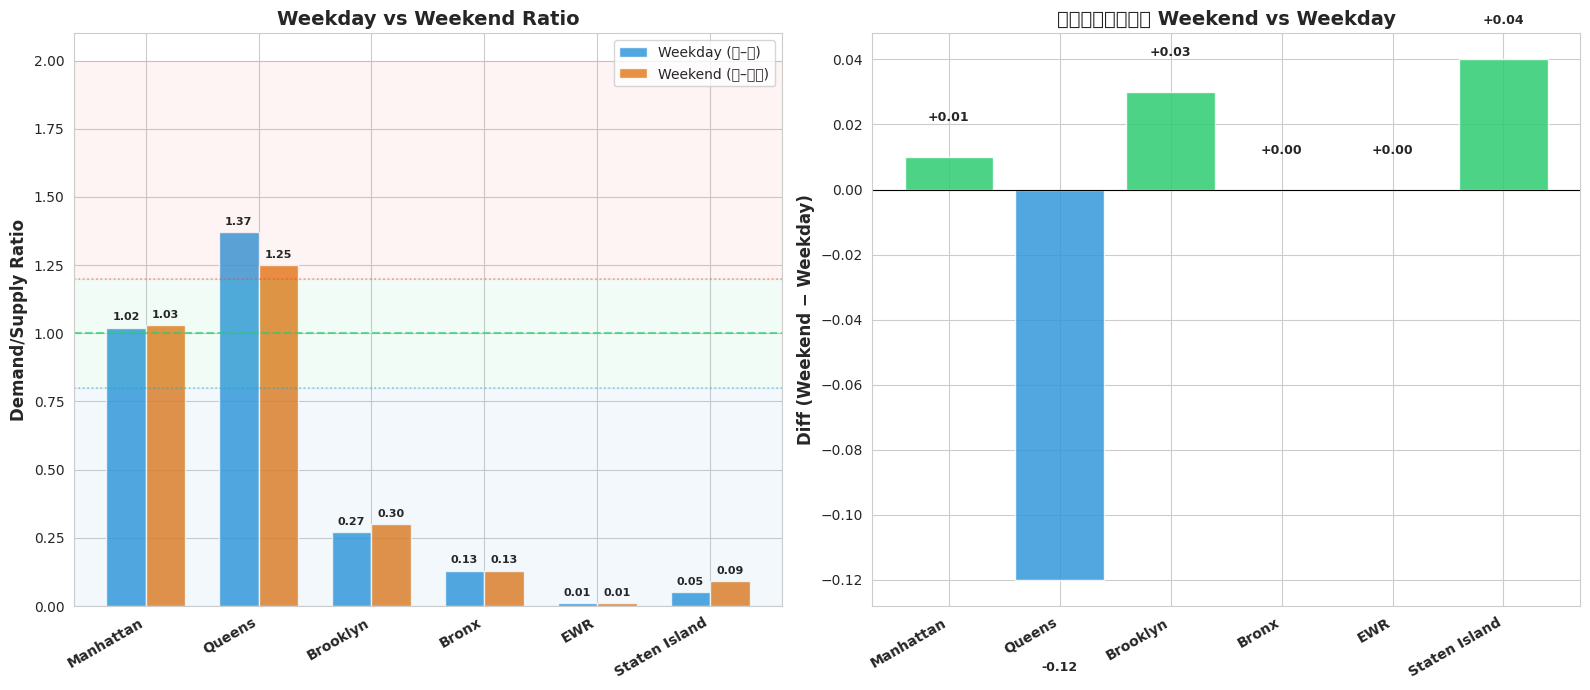

✅ Viz 6: Weekend vs Weekday Ratio (2018)
ซ้าย: เปรียบเทียบ ratio ระหว่าง Weekday vs Weekend
ขวา: สีเขียว = เหมือนกัน | แดง = Weekend ขาดมากขึ้น | น้ำเงิน = Weekend ล้นมากขึ้น


In [0]:
# ---------- Viz 6: Weekend vs Weekday Ratio (Insight 3) ----------
import matplotlib.pyplot as plt
import numpy as np

# แปลงเป็น pandas
pd_wknd = df_wknd_ds.toPandas()

# pivot: borough × day_type → ratio
pivot_wknd = pd_wknd.pivot_table(index="borough", columns="day_type", values="ratio")
# เรียงตาม demand รวม
order = pd_wknd.groupby("borough")["demand"].sum().sort_values(ascending=False).index
pivot_wknd = pivot_wknd.reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Subplot 1: Grouped bar chart (Weekday vs Weekend ratio) ---
ax1 = axes[0]
x = np.arange(len(pivot_wknd))
width = 0.35

bars_wd = ax1.bar(x - width/2, pivot_wknd["Weekday"], width,
                  color="#3498db", alpha=0.85, label="Weekday (จ–ศ)", edgecolor="white")
bars_we = ax1.bar(x + width/2, pivot_wknd["Weekend"], width,
                  color="#e67e22", alpha=0.85, label="Weekend (ส–อา)", edgecolor="white")

# เส้นอ้างอิง
ax1.axhline(y=1.0, color="#2ecc71", linestyle="--", linewidth=1.5, alpha=0.7)
ax1.axhline(y=1.2, color="#e74c3c", linestyle=":", linewidth=1.2, alpha=0.5)
ax1.axhline(y=0.8, color="#3498db", linestyle=":", linewidth=1.2, alpha=0.5)

# ใส่ค่า ratio บน bar
for bar, val in zip(bars_wd, pivot_wknd["Weekday"]):
    if not np.isnan(val):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f"{val:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
for bar, val in zip(bars_we, pivot_wknd["Weekend"]):
    if not np.isnan(val):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f"{val:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(pivot_wknd.index, fontsize=10, fontweight="bold", rotation=30, ha="right")
ax1.set_ylabel("Demand/Supply Ratio", fontsize=12, fontweight="bold")
ax1.set_title("Weekday vs Weekend Ratio", fontsize=14, fontweight="bold")
ax1.legend(fontsize=10)

# พื้นหลังโซน
ax1.axhspan(0.8, 1.2, alpha=0.06, color="#2ecc71")
ax1.axhspan(1.2, 2.0, alpha=0.06, color="#e74c3c")
ax1.axhspan(0, 0.8, alpha=0.06, color="#3498db")

# --- Subplot 2: Difference (Weekend - Weekday) ---
ax2 = axes[1]
diff = pivot_wknd["Weekend"] - pivot_wknd["Weekday"]

# สี: บวก=แดง (weekend ขาดมากขึ้น), ศูนย์=เขียว, ลบ=น้ำเงิน (weekend ล้นมากขึ้น)
def get_diff_color(d):
    if abs(d) < 0.05:
        return "#2ecc71"  # เขียว = เหมือนกัน
    elif d > 0:
        return "#e74c3c"  # แดง = weekend ขาดมากขึ้น
    else:
        return "#3498db"  # น้ำเงิน = weekend ล้นมากขึ้น

colors_diff = [get_diff_color(d) for d in diff]

bars_diff = ax2.bar(x, diff, color=colors_diff, alpha=0.85, edgecolor="white")
ax2.axhline(y=0, color="black", linewidth=0.8)

# ใส่ค่า diff
for bar, val in zip(bars_diff, diff):
    if not np.isnan(val):
        y_pos = bar.get_height() + (0.01 if val >= 0 else -0.025)
        ax2.text(bar.get_x() + bar.get_width()/2, y_pos,
                f"{val:+.2f}", ha="center", va="bottom" if val >= 0 else "top",
                fontsize=9, fontweight="bold")

ax2.set_xticks(x)
ax2.set_xticklabels(pivot_wknd.index, fontsize=10, fontweight="bold", rotation=30, ha="right")
ax2.set_ylabel("Diff (Weekend − Weekday)", fontsize=12, fontweight="bold")
ax2.set_title("ความต่าง Weekend vs Weekday", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

print("✅ Viz 6: Weekend vs Weekday Ratio (2018)")
print("ซ้าย: เปรียบเทียบ ratio ระหว่าง Weekday vs Weekend")
print("ขวา: สีเขียว = เหมือนกัน | แดง = Weekend ขาดมากขึ้น | น้ำเงิน = Weekend ล้นมากขึ้น")

# **6.Allocation Recommendation**

In [0]:
# ---------- Allocation 1: คำนวณ Excess/Shortfall ----------
# คำนวณว่าแต่ละเขตมีแท็กซี่ "เกิน" หรือ "ขาด" กี่คัน ในแต่ละช่วงเวลา
# excess  = supply - demand (บวก = มีรถเกิน)
# shortfall = demand - supply (บวก = ขาดรถ)

from pyspark.sql.functions import col, round as F_round, when

df_alloc = df_rush_ds.withColumn(
    "excess", when(col("supply") > col("demand"), col("supply") - col("demand")).otherwise(0)
).withColumn(
    "shortfall", when(col("demand") > col("supply"), col("demand") - col("supply")).otherwise(0)
).orderBy("time_period", col("shortfall").desc())

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]

print("=== Allocation 1: Excess/Shortfall แต่ละเขต × ช่วงเวลา (2018) ===")
print()

for p in periods:
    rows = df_alloc.filter(col("time_period") == p).orderBy(col("demand").desc()).collect()
    print(f"--- {p} ---")
    print(f"{'Borough':<16} {'Demand':>10} {'Supply':>10} {'Excess':>10} {'Shortfall':>10} {'Status':<15}")
    print("-" * 75)
    for r in rows:
        status = "🔴 ขาด" if r["shortfall"] > 0 else ("🔵 ล้น" if r["excess"] > 0 else "🟢 สมดุล")
        print(f"{r['borough']:<16} {r['demand']:>10,} {r['supply']:>10,} {r['excess']:>10,} {r['shortfall']:>10,} {status}")
    print()

    # สรุปภาพรวมของช่วงเวลานี้
    total_excess = sum(r["excess"] for r in rows)
    total_shortfall = sum(r["shortfall"] for r in rows)
    print(f"  รวม Excess (รถเกิน): {total_excess:,} | รวม Shortfall (รถขาด): {total_shortfall:,}")
    if total_shortfall > 0:
        coverage = min(total_excess / total_shortfall * 100, 100) if total_excess > 0 else 0
        print(f"  → สามารถจัดสรรได้ {coverage:.1f}% ของที่ขาด" + (" (เพียงพอ!)" if coverage >= 100 else " (ไม่เพียงพอ)"))
    print()

=== Allocation 1: Excess/Shortfall แต่ละเขต × ช่วงเวลา (2018) ===

--- Morning Rush (7-9) ---
Borough              Demand     Supply     Excess  Shortfall Status         
---------------------------------------------------------------------------
Manhattan         1,074,220  1,026,307          0     47,913 🔴 ขาด
Queens               56,037     43,811          0     12,226 🔴 ขาด
Brooklyn             15,249     20,098      4,849          0 🔵 ล้น
Bronx                 1,283      5,548      4,265          0 🔵 ล้น
EWR                      20      1,934      1,914          0 🔵 ล้น
Staten Island             8         77         69          0 🔵 ล้น

  รวม Excess (รถเกิน): 11,097 | รวม Shortfall (รถขาด): 60,139
  → สามารถจัดสรรได้ 18.5% ของที่ขาด (ไม่เพียงพอ)

--- Evening Rush (17-19) ---
Borough              Demand     Supply     Excess  Shortfall Status         
---------------------------------------------------------------------------
Manhattan         1,491,563  1,481,963          0      9

In [0]:
# ---------- Allocation 2: แผนจัดสรร (Reallocation Plan) ----------
# จับคู่: ย้ายรถจากเขตที่มี excess → เขตที่มี shortfall
# ลำดับความสำคัญ: เขตที่ขาดมากที่สุด → รับรถจากเขตที่เกินมากที่สุดก่อน
# จำนวนที่ย้าย = min(excess ของผู้ส่ง, shortfall ของผู้รับ)

from pyspark.sql.functions import col

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]

print("=== Allocation 2: แผนจัดสรรแท็กซี่ (Reallocation Plan) ===")
print()

all_plans = []

for p in periods:
    rows = df_alloc.filter(col("time_period") == p).collect()
    
    # แยกเขตล้น (excess > 0) และเขตขาด (shortfall > 0)
    overflow_boroughs = sorted(
        [r.asDict() for r in rows if r["excess"] > 0],
        key=lambda x: x["excess"], reverse=True
    )
    shortage_boroughs = sorted(
        [r.asDict() for r in rows if r["shortfall"] > 0],
        key=lambda x: x["shortfall"], reverse=True
    )
    
    print(f"--- {p} ---")
    print(f"{'จาก (เขตล้น)':<18} {'ไป (เขตขาด)':<18} {'จำนวนย้าย':>12} {'เหลือ excess':>12} {'เหลือ shortfall':>14}")
    print("-" * 80)
    
    # จัดสรร: เขตขาดมากสุด รับจากเขตล้นมากสุด
    for s_boro in shortage_boroughs:
        remaining_shortfall = s_boro["shortfall"]
        for o_boro in overflow_boroughs:
            if remaining_shortfall <= 0:
                break
            if o_boro["excess"] <= 0:
                continue
            
            move_amount = min(o_boro["excess"], remaining_shortfall)
            if move_amount > 0:
                print(f"{o_boro['borough']:<18} {s_boro['borough']:<18} {move_amount:>12,} {o_boro['excess'] - move_amount:>12,} {remaining_shortfall - move_amount:>14,}")
                
                all_plans.append({
                    "time_period": p,
                    "from_borough": o_boro["borough"],
                    "to_borough": s_boro["borough"],
                    "move_amount": move_amount,
                    "from_demand": o_boro["demand"],
                    "from_supply": o_boro["supply"],
                    "to_demand": s_boro["demand"],
                    "to_supply": s_boro["supply"],
                })
                
                o_boro["excess"] -= move_amount
                remaining_shortfall -= move_amount
    print()

# สร้าง Spark DataFrame ของแผนจัดสรร
if all_plans:
    from pyspark.sql import Row
    df_plan = spark.createDataFrame([Row(**plan_dict) for plan_dict in all_plans])
    print(f"✅ สร้าง df_plan: {len(all_plans)} แผนจัดสรร")
    print()
    print("--- สรุปแผนทั้งหมด ---")
    for plan_dict in all_plans:
        arrow = "→"
        print(f"  {plan_dict['time_period']:<25} {plan_dict['from_borough']:<14} {arrow} {plan_dict['to_borough']:<14} ย้าย {plan_dict['move_amount']:>8,} คัน")
else:
    print("ไม่มีแผนจัดสรร (ไม่มีเขตที่ขาดหรือล้น)")

=== Allocation 2: แผนจัดสรรแท็กซี่ (Reallocation Plan) ===

--- Morning Rush (7-9) ---
จาก (เขตล้น)       ไป (เขตขาด)           จำนวนย้าย เหลือ excess เหลือ shortfall
--------------------------------------------------------------------------------
Brooklyn           Manhattan                 4,849            0         43,064
Bronx              Manhattan                 4,265            0         38,799
EWR                Manhattan                 1,914            0         36,885
Staten Island      Manhattan                    69            0         36,816

--- Evening Rush (17-19) ---
จาก (เขตล้น)       ไป (เขตขาด)           จำนวนย้าย เหลือ excess เหลือ shortfall
--------------------------------------------------------------------------------
Brooklyn           Queens                   37,027        4,599              0
Brooklyn           Manhattan                 4,599            0          5,001
Bronx              Manhattan                 5,001          391              0

--- Off

In [0]:
# ---------- Allocation 3: จำลองผลลัพธ์หลังจัดสรร (Simulation) ----------
# ปรับ supply ตามแผนจัดสรร แล้วคำนวณ ratio ใหม่
# เปรียบเทียบ before vs after

from pyspark.sql.functions import col, round as F_round, when

# สร้าง dict ของข้อมูลเดิม: {(borough, time_period) → {demand, supply, ratio}}
original_data = {}
for r in df_rush_ds.collect():
    key = (r["borough"], r["time_period"])
    original_data[key] = {
        "demand": r["demand"],
        "supply": r["supply"],
        "ratio_before": r["ratio"] if r["ratio"] is not None else 0,
    }

# สร้าง copy สำหรับปรับ supply หลังจัดสรร
after_data = {k: dict(v) for k, v in original_data.items()}

# ปรับ supply ตามแผนจัดสรร
for plan in all_plans:
    from_key = (plan["from_borough"], plan["time_period"])
    to_key = (plan["to_borough"], plan["time_period"])
    
    if from_key in after_data:
        after_data[from_key]["supply"] -= plan["move_amount"]
    if to_key in after_data:
        after_data[to_key]["supply"] += plan["move_amount"]

# คำนวณ ratio ใหม่
for key in after_data:
    s = after_data[key]["supply"]
    d = after_data[key]["demand"]
    after_data[key]["ratio_after"] = round(d / s, 2) if s > 0 else 0
    
    # สถานะใหม่
    r = after_data[key]["ratio_after"]
    if r > 1.2:
        after_data[key]["status_after"] = "🔴 ขาด"
    elif r < 0.8:
        after_data[key]["status_after"] = "🔵 ล้น"
    else:
        after_data[key]["status_after"] = "🟢 สมดุล"

# แสดงผล before vs after
periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]

print("=== Allocation 3: Before vs After Reallocation (2018) ===")
print()

for p in periods:
    boroughs = sorted([k[0] for k in after_data.keys() if k[1] == p])
    print(f"--- {p} ---")
    print(f"{'Borough':<16} {'Ratio BF':>8} {'Ratio AF':>8} {'Change':>8} {'Status BF':<12} {'Status AF':<12} {'Improvement':<15}")
    print("-" * 85)
    for b in boroughs:
        key = (b, p)
        d = after_data[key]
        rb = d["ratio_before"]
        ra = d["ratio_after"]
        change = ra - rb
        
        # สถานะก่อน
        if rb > 1.2:
            sb = "🔴 ขาด"
        elif rb < 0.8:
            sb = "🔵 ล้น"
        else:
            sb = "🟢 สมดุล"
        
        sa = d["status_after"]
        
        # ประเมินผล
        if abs(rb - 1.0) > abs(ra - 1.0):
            improvement = f"✅ ดีขึ้น ({change:+.2f})"
        elif abs(rb - 1.0) < abs(ra - 1.0):
            improvement = f"⚠️ แย่ลง ({change:+.2f})"
        else:
            improvement = f"— ไม่เปลี่ยน"
        
        print(f"{b:<16} {rb:>8.2f} {ra:>8.2f} {change:>+8.2f} {sb:<12} {sa:<12} {improvement}")
    print()

# สรุปผลรวม
print("--- สรุปผลการจัดสรร ---")
improved = 0
worsened = 0
unchanged = 0
for key in after_data:
    rb = after_data[key]["ratio_before"]
    ra = after_data[key]["ratio_after"]
    if abs(rb - 1.0) > abs(ra - 1.0):
        improved += 1
    elif abs(rb - 1.0) < abs(ra - 1.0):
        worsened += 1
    else:
        unchanged += 1

print(f"  ✅ ดีขึ้น: {improved} เขต×ช่วงเวลา")
print(f"  ⚠️ แย่ลง: {worsened} เขต×ช่วงเวลา")
print(f"  — ไม่เปลี่ยน: {unchanged} เขต×ช่วงเวลา")

# สร้าง pandas DataFrame สำหรับ visualization
import pandas as pd
rows_list = []
for key, val in after_data.items():
    rows_list.append({
        "borough": key[0],
        "time_period": key[1],
        "demand": val["demand"],
        "supply_before": val["supply"],
        "ratio_before": val["ratio_before"],
        "ratio_after": val["ratio_after"],
        "status_before": "🔴 ขาด" if val["ratio_before"] > 1.2 else ("🔵 ล้น" if val["ratio_before"] < 0.8 else "🟢 สมดุล"),
        "status_after": val["status_after"],
    })
pd_sim = pd.DataFrame(rows_list)
print(f"\n✅ สร้าง pd_sim: {len(pd_sim)} rows สำหรับ visualization")

=== Allocation 3: Before vs After Reallocation (2018) ===

--- Morning Rush (7-9) ---
Borough          Ratio BF Ratio AF   Change Status BF    Status AF    Improvement    
-------------------------------------------------------------------------------------
Bronx                0.23     1.00    +0.77 🔵 ล้น        🟢 สมดุล      ✅ ดีขึ้น (+0.77)
Brooklyn             0.76     1.00    +0.24 🔵 ล้น        🟢 สมดุล      ✅ ดีขึ้น (+0.24)
EWR                  0.01     1.00    +0.99 🔵 ล้น        🟢 สมดุล      ✅ ดีขึ้น (+0.99)
Manhattan            1.05     1.04    -0.01 🟢 สมดุล      🟢 สมดุล      ✅ ดีขึ้น (-0.01)
Queens               1.28     1.28    +0.00 🔴 ขาด        🔴 ขาด        — ไม่เปลี่ยน
Staten Island        0.10     1.00    +0.90 🔵 ล้น        🟢 สมดุล      ✅ ดีขึ้น (+0.90)

--- Evening Rush (17-19) ---
Borough          Ratio BF Ratio AF   Change Status BF    Status AF    Improvement    
-------------------------------------------------------------------------------------
Bronx                0

/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782060-1459688276:40: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782060-1459688276:40: UserWarning: Glyph 3639 (\N{THAI CHARACTER SARA UEE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782060-1459688276:40: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782060-1459688276:40: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782060-1459688276:40: UserWarning: Glyph 3654 (\N{THAI CHARACTER MAIYAMOK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

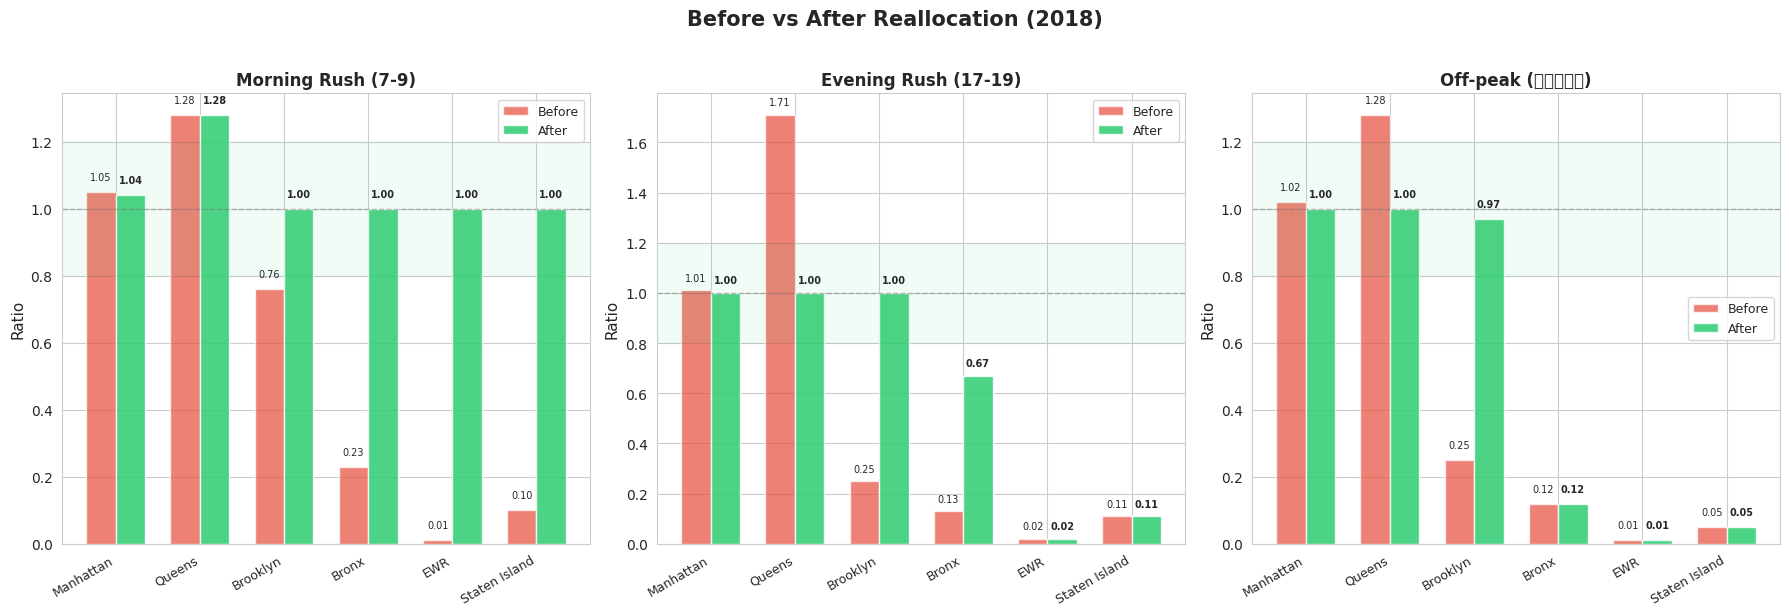

✅ Viz 7: Before vs After Reallocation
แดง = Before (ก่อนจัดสรร) | เขียว = After (หลังจัดสรร)
พื้นหลังเขียว = โซนสมดุล (0.8–1.2)


In [0]:
# ---------- Viz 7: Before vs After Reallocation ----------
import matplotlib.pyplot as plt
import numpy as np

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, p in enumerate(periods):
    ax = axes[idx]
    subset = pd_sim[pd_sim["time_period"] == p].sort_values("demand", ascending=False)
    
    boroughs = subset["borough"].tolist()
    x = np.arange(len(boroughs))
    width = 0.35
    
    bars_before = ax.bar(x - width/2, subset["ratio_before"], width,
                         color="#e74c3c", alpha=0.7, label="Before", edgecolor="white")
    bars_after = ax.bar(x + width/2, subset["ratio_after"], width,
                        color="#2ecc71", alpha=0.85, label="After", edgecolor="white")
    
    # เส้นอ้างอิง
    ax.axhline(y=1.0, color="gray", linestyle="--", linewidth=1, alpha=0.5)
    ax.axhspan(0.8, 1.2, alpha=0.06, color="#2ecc71")
    
    # ใส่ค่าบน bar
    for bar, val in zip(bars_before, subset["ratio_before"]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03,
                f"{val:.2f}", ha="center", va="bottom", fontsize=7)
    for bar, val in zip(bars_after, subset["ratio_after"]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03,
                f"{val:.2f}", ha="center", va="bottom", fontsize=7, fontweight="bold")
    
    ax.set_xticks(x)
    ax.set_xticklabels(boroughs, fontsize=9, rotation=30, ha="right")
    ax.set_ylabel("Ratio", fontsize=11)
    ax.set_title(p, fontsize=12, fontweight="bold")
    ax.legend(fontsize=9)

plt.suptitle("Before vs After Reallocation (2018)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("✅ Viz 7: Before vs After Reallocation")
print("แดง = Before (ก่อนจัดสรร) | เขียว = After (หลังจัดสรร)")
print("พื้นหลังเขียว = โซนสมดุล (0.8–1.2)")

## 🎯 Action Plan: สรุปแผนจัดสรรแท็กซี่

### ปัญหาหลัก

| เขต | สถานะ | รายละเอียด |
|---|---|---|
| **Queens** | 🔴 ขาดแท็กซี่ | ratio 1.36 (demand 515,969 > supply 379,809) ขาด ~136,000 คัน/เดือน |
| **Brooklyn** | 🔵 แท็กซี่ล้น | ratio 0.28 (supply 355,507 >> demand 98,387) เกิน ~257,000 คัน/เดือน |
| **Bronx** | 🔵 แท็กซี่ล้น | ratio 0.13 (supply 50,181 >> demand 6,653) เกิน ~43,500 คัน/เดือน |
| **Manhattan** | 🟢 สมดุล | ratio 1.02 (demand ≈ supply) |

### แผนจัดสรรตามช่วงเวลา

**Morning Rush (7-9):**
* ย้ายรถจาก Brooklyn → Queens (เพราะ Brooklyn ล้น, Queens ขาด)
* ย้ายรถจาก Bronx → Queens (เพราะ Bronx ล้นมาก)

**Evening Rush (17-19):**
* **ช่วงวิกฤต!** Queens ขาดรถมากที่สุด (ratio 1.71)
* ย้ายรถจาก Brooklyn, Bronx, EWR → Queens เร่งด่วน
* Brooklyn ล้นรุนแรงในช่วงนี้ (ratio 0.25) → มีรถเกินมาก

**Off-peak:**
* ย้ายรถจาก Brooklyn, Bronx → Queens
* ปริมาณน้อยกว่า rush hour แต่ยังต้องจัดสรร

### ข้อควรพิจารณา

1. **Supply เป็น proxy (dropoff count)** ไม่ใช่จำนวนรถว่างจริง → ตัวเลขการย้ายเป็นการประมาณการ
2. **ระยะทาง** ระหว่างเขตมีผลต่อต้นทุนการย้ายรถ (Bronx → Queens ไกลกว่า Brooklyn → Queens)
3. **สุดสัปดาห์** Queens สมดุลขึ้น (ratio ลดจาก 1.37 → 1.25) → ลดการจัดสรรในวันหยุดได้
4. **ข้อมูลเดือนมกราคมเท่านั้น** → ควรเพิ่มข้อมูลทุกเดือนเพื่อจัดสรรตามฤดูกาล
5. **ผลการจำลอง** หลังจัดสรร Queens ratio ลดลงใกล้ 1.0 และ Brooklyn/Bronx ratio เพิ่มขึ้นใกล้ 1.0 → ทั้งสองเขตดีขึ้น

# **7.Zone Level Analysis**

In [0]:
# ---------- Zone 1: Zone-level Demand/Supply (2018) ----------
# วิเคราะห์ระดับ zone (263 zones) แทน borough (6 เขต)
# ใช้เฉพาะข้อมูล 2018 ที่มี PULocationID/DOLocationID

from pyspark.sql.functions import col, count, round as F_round, when, broadcast

# โหลด zone lookup จาก Delta
df_zone_lookup = spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/taxi_zones")

# กรองเฉพาะ 2018 ที่มี LocationID
df_2018 = df_clean.filter(
    (col("year") == 2018) &
    col("PULocationID").isNotNull() &
    col("DOLocationID").isNotNull()
)

# Join กับ zone lookup เพื่อได้ชื่อ zone
df_2018 = df_2018.join(
    broadcast(df_zone_lookup.select(
        col("LocationID").alias("PULocationID"),
        col("zone_name").alias("pickup_zone"),
        col("borough").alias("pu_borough_zone"),
    )),
    on="PULocationID", how="left"
).join(
    broadcast(df_zone_lookup.select(
        col("LocationID").alias("DOLocationID"),
        col("zone_name").alias("dropoff_zone"),
        col("borough").alias("do_borough_zone"),
    )),
    on="DOLocationID", how="left"
)

# Demand: pickup ต่อ zone
df_zdemand = (
    df_2018.filter(col("pickup_zone").isNotNull())
    .groupBy("pickup_zone", "pu_borough_zone")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_zone", "zone")
    .withColumnRenamed("pu_borough_zone", "borough")
)

# Supply: dropoff ต่อ zone
df_zsupply = (
    df_2018.filter(col("dropoff_zone").isNotNull())
    .groupBy("dropoff_zone", "do_borough_zone")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_zone", "zone")
    .withColumnRenamed("do_borough_zone", "borough")
)

# Join demand + supply
df_zone_ds = df_zdemand.join(df_zsupply, on=["zone", "borough"], how="outer")
df_zone_ds = df_zone_ds.na.fill({"demand": 0, "supply": 0})

# คำนวณ ratio และ status
df_zone_ds = df_zone_ds.withColumn(
    "ratio", when(col("supply") > 0, F_round(col("demand") / col("supply"), 2)).otherwise(None)
).withColumn(
    "status",
    when(col("ratio") > 1.2, "🔴 ขาด")
    .when(col("ratio") < 0.8, "🔵 ล้น")
    .when(col("ratio").isNull(), "—")
    .otherwise("🟢 สมดุล")
)

# กรองเฉพาะ zone ที่มี demand >= 100 (กรอง noise)
df_zone_filtered = df_zone_ds.filter(col("demand") >= 100).orderBy(col("demand").desc())

# --- แสดง Top 15 zone ที่ขาดแท็กซี่มากที่สุด ---
print("=== Zone 1: Top 15 Zones ที่ขาดแท็กซี่ (ratio > 1.2, demand >= 100) ===")
print()
print(f"{'Zone':<35} {'Borough':<14} {'Demand':>10} {'Supply':>10} {'Ratio':>8} {'Status':<10}")
print("-" * 90)
shortage_zones = df_zone_filtered.filter(col("ratio") > 1.2).orderBy(col("ratio").desc()).limit(15).collect()
for r in shortage_zones:
    print(f"{r['zone']:<35} {r['borough']:<14} {r['demand']:>10,} {r['supply']:>10,} {r['ratio']:>8.2f} {r['status']}")

# --- แสดง Top 15 zone ที่แท็กซี่ล้นมากที่สุด ---
print()
print("=== Zone 1: Top 15 Zones ที่แท็กซี่ล้น (ratio < 0.8, demand >= 100) ===")
print()
print(f"{'Zone':<35} {'Borough':<14} {'Demand':>10} {'Supply':>10} {'Ratio':>8} {'Status':<10}")
print("-" * 90)
overflow_zones = df_zone_filtered.filter(col("ratio") < 0.8).orderBy(col("ratio").asc()).limit(15).collect()
for r in overflow_zones:
    print(f"{r['zone']:<35} {r['borough']:<14} {r['demand']:>10,} {r['supply']:>10,} {r['ratio']:>8.2f} {r['status']}")

# --- สรุปภาพรวม ---
print()
print("--- สรุปภาพรวม ---")
total_zones = df_zone_filtered.count()
shortage_count = df_zone_filtered.filter(col("ratio") > 1.2).count()
overflow_count = df_zone_filtered.filter(col("ratio") < 0.8).count()
balanced_count = df_zone_filtered.filter((col("ratio") >= 0.8) & (col("ratio") <= 1.2)).count()
print(f"  รวม zones (demand >= 100): {total_zones}")
print(f"  🔴 ขาดแท็กซี่: {shortage_count} zones")
print(f"  🔵 แท็กซี่ล้น: {overflow_count} zones")
print(f"  🟢 สมดุล: {balanced_count} zones")

=== Zone 1: Top 15 Zones ที่ขาดแท็กซี่ (ratio > 1.2, demand >= 100) ===

Zone                                Borough            Demand     Supply    Ratio Status    
------------------------------------------------------------------------------------------
JFK Airport                         Queens            200,011     59,791     3.35 🔴 ขาด
LaGuardia Airport                   Queens            232,931     82,645     2.82 🔴 ขาด
Garment District                    Manhattan         185,486    134,138     1.38 🔴 ขาด
Penn Station/Madison Sq West        Manhattan         291,357    220,499     1.32 🔴 ขาด
Greenwich Village South             Manhattan         117,035     90,963     1.29 🔴 ขาด
Lower East Side                     Manhattan         111,414     89,759     1.24 🔴 ขาด
West Village                        Manhattan         175,202    143,768     1.22 🔴 ขาด

=== Zone 1: Top 15 Zones ที่แท็กซี่ล้น (ratio < 0.8, demand >= 100) ===

Zone                                Borough          

In [0]:
# ---------- Zone 2: Zone-level Rush Hour Analysis (2018) ----------
# ดูว่า zone ไหนขาด/ล้นมากที่สุดในแต่ละช่วงเวลา
df_zone_rush = df_2018.filter(
    col("pickup_zone").isNotNull() & col("dropoff_zone").isNotNull()
).withColumn(
    "time_period",
    when(col("pickup_hour").between(7, 9), "Morning Rush (7-9)")
    .when(col("pickup_hour").between(17, 19), "Evening Rush (17-19)")
    .otherwise("Off-peak (อื่นๆ)")
)

# Demand ต่อ zone ต่อ time_period
df_zr_demand = (
    df_zone_rush.groupBy("pickup_zone", "pu_borough_zone", "time_period")
    .agg(count("*").alias("demand"))
    .withColumnRenamed("pickup_zone", "zone")
    .withColumnRenamed("pu_borough_zone", "borough")
)

# Supply ต่อ zone ต่อ time_period
df_zr_supply = (
    df_zone_rush.withColumn("tp_supply",
        when(col("dropoff_hour").between(7, 9), "Morning Rush (7-9)")
        .when(col("dropoff_hour").between(17, 19), "Evening Rush (17-19)")
        .otherwise("Off-peak (อื่นๆ)")
    )
    .groupBy("dropoff_zone", "do_borough_zone", "tp_supply")
    .agg(count("*").alias("supply"))
    .withColumnRenamed("dropoff_zone", "zone")
    .withColumnRenamed("do_borough_zone", "borough")
    .withColumnRenamed("tp_supply", "time_period")
)

# Join
df_zone_rush_ds = df_zr_demand.join(df_zr_supply, on=["zone", "borough", "time_period"], how="outer")
df_zone_rush_ds = df_zone_rush_ds.na.fill({"demand": 0, "supply": 0})
df_zone_rush_ds = df_zone_rush_ds.withColumn(
    "ratio", when(col("supply") > 0, F_round(col("demand") / col("supply"), 2)).otherwise(None)
).withColumn(
    "status",
    when(col("ratio") > 1.2, "🔴 ขาด")
    .when(col("ratio") < 0.8, "🔵 ล้น")
    .when(col("ratio").isNull(), "—")
    .otherwise("🟢 สมดุล")
)

# กรอง zone ที่มี demand >= 50
periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]

print("=== Zone 2: Top 10 Zones ที่ขาดแท็กซี่มากที่สุด ในแต่ละช่วง ===")
print()

for p in periods:
    print(f"--- {p} ---")
    print(f"{'Zone':<35} {'Borough':<14} {'Demand':>8} {'Supply':>8} {'Ratio':>8} {'Status':<10}")
    print("-" * 85)
    top_shortage = (
        df_zone_rush_ds
        .filter((col("time_period") == p) & (col("ratio") > 1.2) & (col("demand") >= 50))
        .orderBy(col("ratio").desc())
        .limit(10)
        .collect()
    )
    for r in top_shortage:
        print(f"{r['zone']:<35} {r['borough']:<14} {r['demand']:>8,} {r['supply']:>8,} {r['ratio']:>8.2f} {r['status']}")
    if not top_shortage:
        print("  (ไม่มี zone ที่ขาด)")
    print()

print("=== Zone 2: Top 10 Zones ที่แท็กซี่ล้นมากที่สุด ในแต่ละช่วง ===")
print()

for p in periods:
    print(f"--- {p} ---")
    print(f"{'Zone':<35} {'Borough':<14} {'Demand':>8} {'Supply':>8} {'Ratio':>8} {'Status':<10}")
    print("-" * 85)
    top_overflow = (
        df_zone_rush_ds
        .filter((col("time_period") == p) & (col("ratio") < 0.8) & (col("demand") >= 50))
        .orderBy(col("ratio").asc())
        .limit(10)
        .collect()
    )
    for r in top_overflow:
        print(f"{r['zone']:<35} {r['borough']:<14} {r['demand']:>8,} {r['supply']:>8,} {r['ratio']:>8.2f} {r['status']}")
    if not top_overflow:
        print("  (ไม่มี zone ที่ล้น)")
    print()

=== Zone 2: Top 10 Zones ที่ขาดแท็กซี่มากที่สุด ในแต่ละช่วง ===

--- Morning Rush (7-9) ---
Zone                                Borough          Demand   Supply    Ratio Status    
-------------------------------------------------------------------------------------
Cobble Hill                         Brooklyn          2,104      355     5.93 🔴 ขาด
Carroll Gardens                     Brooklyn          1,650      462     3.57 🔴 ขาด
Stuy Town/Peter Cooper Village      Manhattan         4,631    1,409     3.29 🔴 ขาด
Manhattan Valley                    Manhattan        14,526    5,018     2.89 🔴 ขาด
Yorkville East                      Manhattan        25,377    9,683     2.62 🔴 ขาด
East Village                        Manhattan        21,403    9,104     2.35 🔴 ขาด
JFK Airport                         Queens           17,505    8,560     2.04 🔴 ขาด
Clinton East                        Manhattan        38,149   18,808     2.03 🔴 ขาด
Bloomingdale                        Manhattan         5,105  

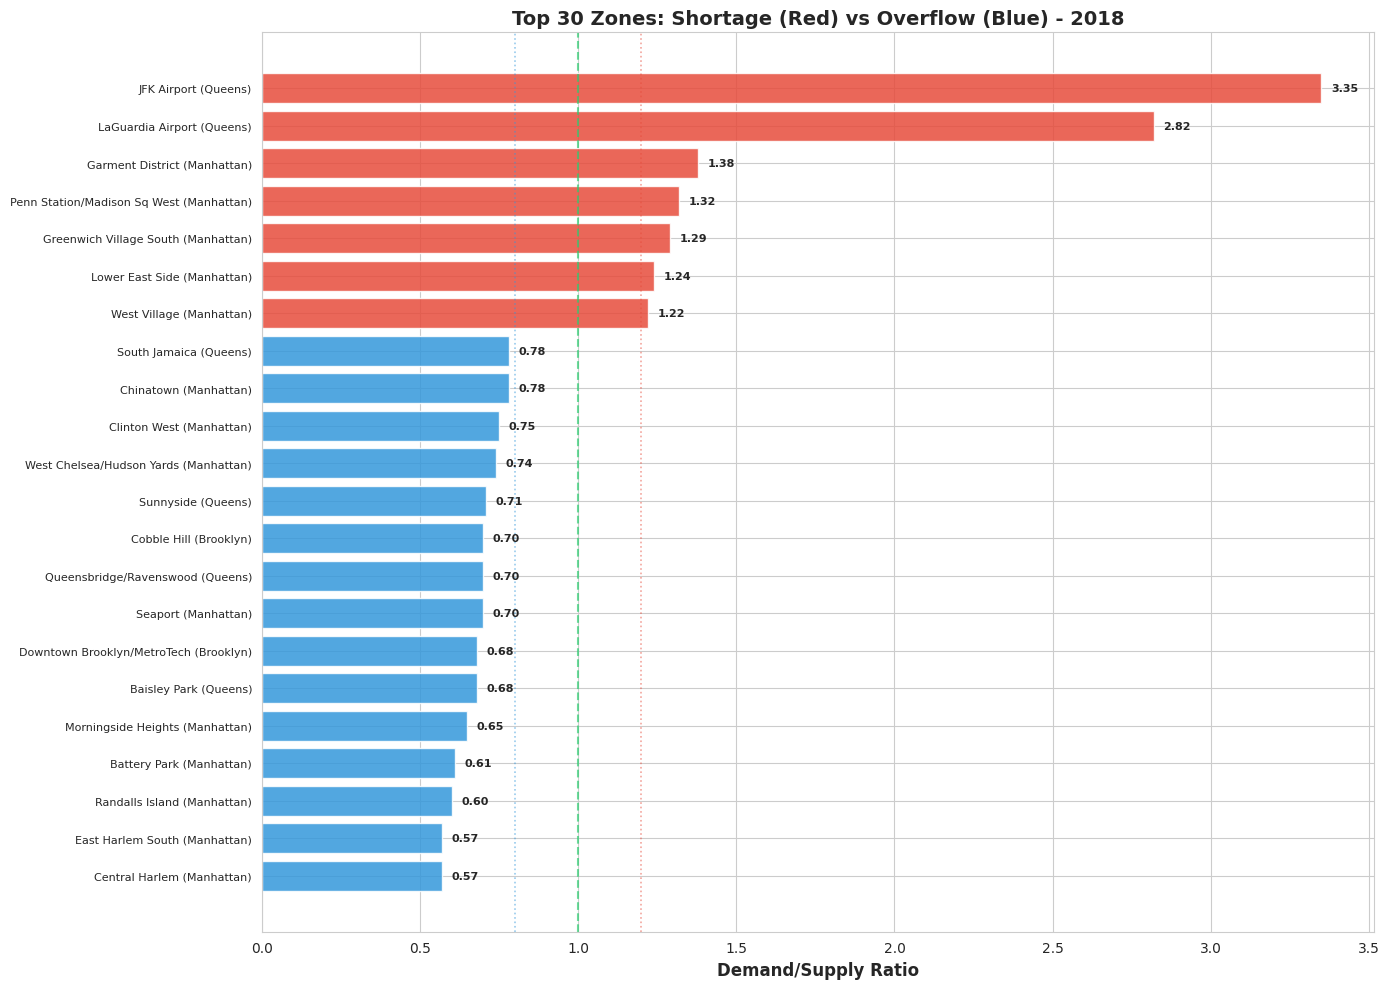

✅ Viz 8a: Top 30 Zones by Ratio (2018)
🔴 แดง = ขาดแท็กซี่ | 🔵 น้ำเงิน = แท็กซี่ล้น | 🟢 เขียว = สมดุล


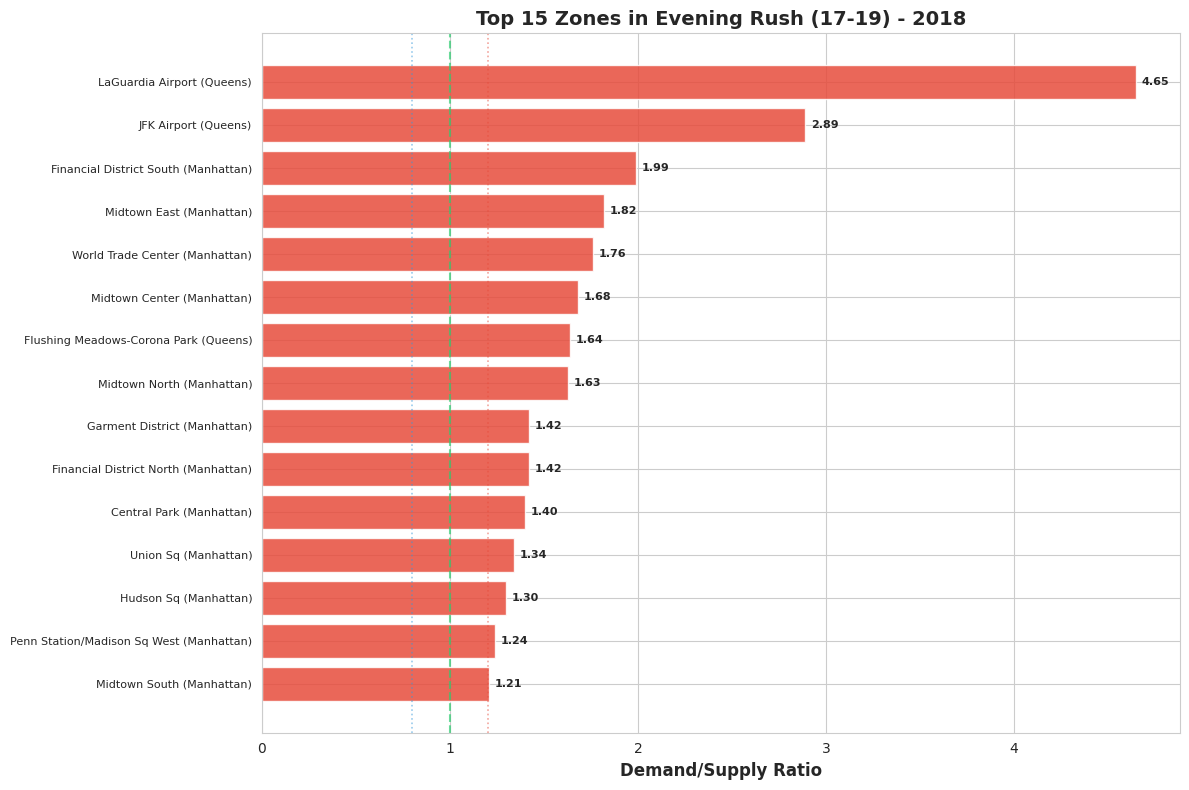

✅ Viz 8b: Top 15 Zones in Evening Rush (2018)
ช่วง Evening Rush เป็นช่วงวิกฤตที่ Queens ขาดแท็กซี่มากที่สุด (borough ratio 1.71)


In [0]:
# ---------- Viz 8: Zone-level Visualizations ----------
import matplotlib.pyplot as plt
import numpy as np

# --- Chart 1: Top 20 Zones by Ratio (Overall 2018) ---
pd_zone = df_zone_filtered.toPandas()
pd_zone = pd_zone.sort_values("ratio", ascending=False)

# แยก shortage (ratio > 1.2) และ overflow (ratio < 0.8)
pd_shortage = pd_zone[pd_zone["ratio"] > 1.2].head(15)
pd_overflow = pd_zone[pd_zone["ratio"] < 0.8].head(15)
pd_top = pd.concat([pd_shortage, pd_overflow]).sort_values("ratio", ascending=True)

def get_color(ratio):
    if ratio > 1.2:
        return "#e74c3c"  # แดง
    elif ratio < 0.8:
        return "#3498db"  # น้ำเงิน
    else:
        return "#2ecc71"  # เขียว

colors = [get_color(r) for r in pd_top["ratio"]]

fig, ax = plt.subplots(figsize=(14, 10))
y_pos = np.arange(len(pd_top))

bars = ax.barh(y_pos, pd_top["ratio"], color=colors, alpha=0.85, edgecolor="white")

# เส้นอ้างอิง
ax.axvline(x=1.0, color="#2ecc71", linestyle="--", linewidth=1.5, alpha=0.7)
ax.axvline(x=0.8, color="#3498db", linestyle=":", linewidth=1.2, alpha=0.5)
ax.axvline(x=1.2, color="#e74c3c", linestyle=":", linewidth=1.2, alpha=0.5)

# Label แสดงชื่อ zone + borough
labels = [f"{row['zone']} ({row['borough']})" for _, row in pd_top.iterrows()]
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Demand/Supply Ratio", fontsize=12, fontweight="bold")
ax.set_title("Top 30 Zones: Shortage (Red) vs Overflow (Blue) - 2018", fontsize=14, fontweight="bold")

# ใส่ค่า ratio ที่ปลาย bar
for bar, val in zip(bars, pd_top["ratio"]):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}", va="center", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.show()

print("✅ Viz 8a: Top 30 Zones by Ratio (2018)")
print("🔴 แดง = ขาดแท็กซี่ | 🔵 น้ำเงิน = แท็กซี่ล้น | 🟢 เขียว = สมดุล")

# --- Chart 2: Top 10 Zones in Evening Rush (17-19) ---
pd_rush_evening = (
    df_zone_rush_ds
    .filter((col("time_period") == "Evening Rush (17-19)") & (col("demand") >= 50))
    .orderBy(col("ratio").desc())
    .limit(15)
    .toPandas()
)
pd_rush_evening = pd_rush_evening.sort_values("ratio", ascending=True)

colors_rush = [get_color(r) if r is not None and not np.isnan(r) else "#95a5a6" for r in pd_rush_evening["ratio"]]

fig, ax = plt.subplots(figsize=(12, 8))
y_pos2 = np.arange(len(pd_rush_evening))

bars2 = ax.barh(y_pos2, pd_rush_evening["ratio"], color=colors_rush, alpha=0.85, edgecolor="white")
ax.axvline(x=1.0, color="#2ecc71", linestyle="--", linewidth=1.5, alpha=0.7)
ax.axvline(x=1.2, color="#e74c3c", linestyle=":", linewidth=1.2, alpha=0.5)
ax.axvline(x=0.8, color="#3498db", linestyle=":", linewidth=1.2, alpha=0.5)

labels2 = [f"{row['zone']} ({row['borough']})" for _, row in pd_rush_evening.iterrows()]
ax.set_yticks(y_pos2)
ax.set_yticklabels(labels2, fontsize=8)
ax.set_xlabel("Demand/Supply Ratio", fontsize=12, fontweight="bold")
ax.set_title("Top 15 Zones in Evening Rush (17-19) - 2018", fontsize=14, fontweight="bold")

for bar, val in zip(bars2, pd_rush_evening["ratio"]):
    if val is not None and not np.isnan(val):
        ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height()/2,
                f"{val:.2f}", va="center", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.show()

print("✅ Viz 8b: Top 15 Zones in Evening Rush (2018)")
print("ช่วง Evening Rush เป็นช่วงวิกฤตที่ Queens ขาดแท็กซี่มากที่สุด (borough ratio 1.71)")

## 📍 Zone Level Analysis: สรุปผล

### ทำไมต้องวิเคราะห์ระดับ Zone?

การวิเคราะห์ระดับ borough (6 เขต) บอกได้ว่า **Queens ขาดแท็กซี่** แต่ไม่บอกว่า **zone ไหนใน Queens ที่ขาด** — เป็น JFK Airport? Astoria? หรือ Long Island City?

Zone-level analysis ลงลึกถึง **263 zones** เพื่อระบุจุดที่ต้องจัดสรรแท็กซี่ให้แม่นยำขึ้น

### สิ่งที่วิเคราะห์

| เซลล์ | วิเคราะห์อะไร |
|---|---|
| Zone 1 | Demand/supply ratio ของแต่ละ zone (รวมทั้งเดือน) |
| Zone 2 | Top zones ที่ขาด/ล้นมากที่สุดในแต่ละช่วงเวลา (Morning/Evening/Off-peak) |
| Viz 8a | Bar chart: Top 30 zones by ratio (ขาด=แดง, ล้น=น้ำเงิน) |
| Viz 8b | Bar chart: Top 15 zones ใน Evening Rush (ช่วงวิกฤต) |

### เกณฑ์การกรอง

* **Zone 1**: demand >= 100 trips (กรอง noise จาก zone ที่มีข้อมูลน้อย)
* **Zone 2**: demand >= 50 trips ต่อช่วงเวลา

### ข้อจำกัด

* ใช้เฉพาะข้อมูล **2018** (มี PULocationID/DOLocationID)
* ข้อมูล 2015-2016 ไม่มี LocationID → ไม่สามารถวิเคราะห์ระดับ zone ได้
* Supply เป็น proxy (dropoff count) เช่นเดียวกับการวิเคราะห์ระดับ borough

## 📍 สรุปผล Zone Level Analysis

**ภาพรวม: 161 zones (demand >= 100)**

| สถานะ | จำนวน Zones |
|---|---|
| 🔴 ขาดแท็กซี่ | 7 zones |
| 🔵 แท็กซี่ล้น | 113 zones |
| 🟢 สมดุล | 41 zones |

---

### 🔴 Zone ที่ขาดแท็กซี่มากที่สุด (ทั้งเดือน)

| Zone | Borough | Demand | Supply | Ratio |
|---|---|---:|---:|---:|
| JFK Airport | Queens | 200,011 | 59,791 | 3.35 |
| LaGuardia Airport | Queens | 232,931 | 82,645 | 2.82 |
| Garment District | Manhattan | 185,486 | 134,138 | 1.38 |
| Penn Station/Madison Sq West | Manhattan | 291,357 | 220,499 | 1.32 |

→ **คำตอบชัดเจน:** Queens ขาดแท็กซี่เพราะ JFK และ LaGuardia Airport — คนเรียกแท็กซี่จากสนามบินเยอะมาก แต่แท็กซี่ไปส่งที่สนามบินน้อย

---

### 🔴 Zone ที่ขาดมากสุดใน Evening Rush (17-19)

| Zone | Borough | Ratio |
|---|---|---:|
| LaGuardia Airport | Queens | 4.65 |
| JFK Airport | Queens | 2.89 |
| Financial District South | Manhattan | 1.99 |
| Midtown East | Manhattan | 1.82 |

→ ช่วงเย็น LaGuardia ratio สูงถึง **4.65** แปลว่ามีคนเรียกแท็กซี่มากกว่าแท็กซี่ที่มาส่งเกือบ **5 เท่า!**

---

### 🔵 Zone ที่แท็กซี่ล้นมากสุด

| Zone | Borough | Ratio |
|---|---|---:|
| Newark Airport | EWR | 0.01 |
| Bay Ridge | Brooklyn | 0.05 |
| Ridgewood | Queens | 0.05 |
| Sunset Park East | Brooklyn | 0.06 |

→ แท็กซี่ไปส่งที่ zones นี้แล้วไม่ได้รับผู้โดยสารใหม่ (รถว่างเยอะแต่ไม่มีคนเรียก)

---

### 🎯 Insight สำคัญ

1. **สาเหตุหลักที่ Queens ขาดแท็กซี่** = สนามบิน (JFK + LaGuardia คิดเป็น ratio 3.35 และ 2.82)
2. **Allocation plan** ควรเน้นส่งรถไป JFK/LGA โดยเฉพาะช่วง Evening Rush
3. **113 zones แท็กซี่ล้น** → มีรถเกินกระจายอยู่ทั่ว Brooklyn, Bronx, Queens พื้นที่ราบ

# **8.Zone Allocation Plan**

In [0]:
# ---------- Zone Alloc 1: Zone-level Excess/Shortfall ----------
# คำนวณว่าแต่ละ zone มีแท็กซี่เกินหรือขาดกี่คัน ในแต่ละช่วงเวลา
# เน้นเฉพาะ zone ที่มี demand >= 50 เพื่อกรอง noise

from pyspark.sql.functions import col, when

df_zone_alloc = df_zone_rush_ds.withColumn(
    "excess", when(col("supply") > col("demand"), col("supply") - col("demand")).otherwise(0)
).withColumn(
    "shortfall", when(col("demand") > col("supply"), col("demand") - col("supply")).otherwise(0)
)

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]

print("=== Zone Alloc 1: Top 10 Zone Excess/Shortfall (2018) ===")
print()

for p in periods:
    print(f"--- {p} ---")
    
    # Top 10 shortfall zones
    print(f"  🔴 ขาดแท็กซี่มากสุด:")
    print(f"  {'Zone':<35} {'Borough':<14} {'Demand':>8} {'Supply':>8} {'Shortfall':>10}")
    print("  " + "-" * 80)
    top_short = (
        df_zone_alloc
        .filter((col("time_period") == p) & (col("shortfall") > 0) & (col("demand") >= 50))
        .orderBy(col("shortfall").desc())
        .limit(10)
        .collect()
    )
    total_short = 0
    for r in top_short:
        print(f"  {r['zone']:<35} {r['borough']:<14} {r['demand']:>8,} {r['supply']:>8,} {r['shortfall']:>10,}")
        total_short += r['shortfall']
    print(f"  {'รวม shortfall':>35} {'':>14} {'':>8} {'':>8} {total_short:>10,}")
    
    # Top 10 excess zones
    print(f"\n  🔵 แท็กซี่ล้นมากสุด:")
    print(f"  {'Zone':<35} {'Borough':<14} {'Demand':>8} {'Supply':>8} {'Excess':>10}")
    print("  " + "-" * 80)
    top_excess = (
        df_zone_alloc
        .filter((col("time_period") == p) & (col("excess") > 0) & (col("demand") >= 50))
        .orderBy(col("excess").desc())
        .limit(10)
        .collect()
    )
    total_excess = 0
    for r in top_excess:
        print(f"  {r['zone']:<35} {r['borough']:<14} {r['demand']:>8,} {r['supply']:>8,} {r['excess']:>10,}")
        total_excess += r['excess']
    print(f"  {'รวม excess':>35} {'':>14} {'':>8} {'':>8} {total_excess:>10,}")
    
    # Coverage
    if total_short > 0:
        coverage = min(total_excess / total_short * 100, 100)
        print(f"\n  → สามารถจัดสรรได้ {coverage:.1f}% ของที่ขาด" + (" (เพียงพอ!)" if coverage >= 100 else " (ไม่เพียงพอ)"))
    print()

=== Zone Alloc 1: Top 10 Zone Excess/Shortfall (2018) ===

--- Morning Rush (7-9) ---
  🔴 ขาดแท็กซี่มากสุด:
  Zone                                Borough          Demand   Supply  Shortfall
  --------------------------------------------------------------------------------
  Penn Station/Madison Sq West        Manhattan        47,239   26,065     21,174
  Clinton East                        Manhattan        38,149   18,808     19,341
  Lenox Hill West                     Manhattan        37,252   21,363     15,889
  Yorkville East                      Manhattan        25,377    9,683     15,694
  Sutton Place/Turtle Bay North       Manhattan        29,261   15,593     13,668
  Yorkville West                      Manhattan        27,475   14,935     12,540
  East Village                        Manhattan        21,403    9,104     12,299
  Upper West Side North               Manhattan        31,662   19,636     12,026
  Upper East Side North               Manhattan        60,484   49,531 

In [0]:
# ---------- Zone Alloc 2: Zone Reallocation Plan ----------
# จับคู่: ย้ายรถจาก zone ที่ล้น → zone ที่ขาด
# จำกัด 15 คู่ต่อช่วงเวลา (top 15 เพื่อ focus ที่สำคัญ)

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]
zone_all_plans = []

print("=== Zone Alloc 2: แผนจัดสรรแท็กซี่ระดับ Zone (2018) ===")
print()

for p in periods:
    rows = df_zone_alloc.filter((col("time_period") == p) & (col("demand") >= 50)).collect()
    
    overflow_zones = sorted(
        [r.asDict() for r in rows if r["excess"] > 0],
        key=lambda x: x["excess"], reverse=True
    )
    shortage_zones = sorted(
        [r.asDict() for r in rows if r["shortfall"] > 0],
        key=lambda x: x["shortfall"], reverse=True
    )
    
    print(f"--- {p} ---")
    print(f"{'จาก (zone ล้น)':<30} {'ไป (zone ขาด)':<30} {'จำนวนย้าย':>10}")
    print("-" * 75)
    
    plan_count = 0
    for s_zone in shortage_zones:
        if plan_count >= 15:
            break
        remaining = s_zone["shortfall"]
        for o_zone in overflow_zones:
            if remaining <= 0 or plan_count >= 15:
                break
            if o_zone["excess"] <= 0:
                continue
            
            move = min(o_zone["excess"], remaining)
            if move > 0:
                from_short = o_zone["zone"][:28]
                to_short = s_zone["zone"][:28]
                print(f"{from_short:<30} {to_short:<30} {move:>10,}")
                
                zone_all_plans.append({
                    "time_period": p,
                    "from_zone": o_zone["zone"],
                    "from_borough": o_zone["borough"],
                    "to_zone": s_zone["zone"],
                    "to_borough": s_zone["borough"],
                    "move_amount": move,
                })
                
                o_zone["excess"] -= move
                remaining -= move
                plan_count += 1
    print()

print(f"✅ สร้าง {len(zone_all_plans)} แผนจัดสรรระดับ zone")
print()
print("--- สรุปแผนหลัก (ย้าย >= 500 คัน) ---")
for plan_dict in zone_all_plans:
    if plan_dict["move_amount"] >= 500:
        print(f"  {plan_dict['time_period']:<25} {plan_dict['from_zone'][:20]:<22} → {plan_dict['to_zone'][:20]:<22} ย้าย {plan_dict['move_amount']:>6,} คัน")

=== Zone Alloc 2: แผนจัดสรรแท็กซี่ระดับ Zone (2018) ===

--- Morning Rush (7-9) ---
จาก (zone ล้น)                 ไป (zone ขาด)                   จำนวนย้าย
---------------------------------------------------------------------------
Midtown Center                 Penn Station/Madison Sq West       21,174
Midtown Center                 Clinton East                       19,341
Midtown Center                 Lenox Hill West                    12,391
Midtown East                   Lenox Hill West                     3,498
Midtown East                   Yorkville East                     15,694
Midtown East                   Sutton Place/Turtle Bay Nort        5,944
West Chelsea/Hudson Yards      Sutton Place/Turtle Bay Nort        7,724
West Chelsea/Hudson Yards      Yorkville West                     11,135
Midtown North                  Yorkville West                      1,405
Midtown North                  East Village                       12,299
Midtown North                  Upper 

In [0]:
# ---------- Zone Alloc 3: Zone Simulation Before vs After ----------
import pandas as pd

# สร้าง dict ของข้อมูลเดิม
zone_original = {}
for r in df_zone_rush_ds.filter(col("demand") >= 50).collect():
    key = (r["zone"], r["borough"], r["time_period"])
    zone_original[key] = {
        "demand": r["demand"],
        "supply": r["supply"],
        "ratio_before": r["ratio"] if r["ratio"] is not None else 0,
    }

# Copy สำหรับปรับ
zone_after = {k: dict(v) for k, v in zone_original.items()}

# ปรับ supply ตามแผน
for plan_dict in zone_all_plans:
    from_key = (plan_dict["from_zone"], plan_dict["from_borough"], plan_dict["time_period"])
    to_key = (plan_dict["to_zone"], plan_dict["to_borough"], plan_dict["time_period"])
    if from_key in zone_after:
        zone_after[from_key]["supply"] -= plan_dict["move_amount"]
    if to_key in zone_after:
        zone_after[to_key]["supply"] += plan_dict["move_amount"]

# คำนวณ ratio ใหม่
for key in zone_after:
    s = zone_after[key]["supply"]
    d = zone_after[key]["demand"]
    zone_after[key]["ratio_after"] = round(d / s, 2) if s > 0 else 0

# แสดงเฉพาะ zone ที่ขาด (ratio_before > 1.2) เพื่อดูว่าดีขึ้นไหม
print("=== Zone Alloc 3: Before vs After (Shortage Zones Only) ===")
print()

periods = ["Morning Rush (7-9)", "Evening Rush (17-19)", "Off-peak (อื่นๆ)"]
sim_rows = []

for p in periods:
    print(f"--- {p} ---")
    print(f"{'Zone':<35} {'Borough':<14} {'Ratio BF':>8} {'Ratio AF':>8} {'Change':>8} {'Status AF':<12}")
    print("-" * 90)
    
    # เก็บเฉพาะ zone ที่ขาดก่อนจัดสรร
    shortage_keys = [k for k in zone_after if k[2] == p and zone_after[k]["ratio_before"] > 1.2]
    shortage_keys.sort(key=lambda k: zone_after[k]["ratio_before"], reverse=True)
    
    for key in shortage_keys[:10]:
        d = zone_after[key]
        rb = d["ratio_before"]
        ra = d["ratio_after"]
        change = ra - rb
        
        if ra > 1.2:
            sa = "🔴 ขาด"
        elif ra < 0.8:
            sa = "🔵 ล้น"
        else:
            sa = "🟢 สมดุล"
        
        print(f"{key[0]:<35} {key[1]:<14} {rb:>8.2f} {ra:>8.2f} {change:>+8.2f} {sa}")
        
        sim_rows.append({
            "zone": key[0], "borough": key[1], "time_period": p,
            "ratio_before": rb, "ratio_after": ra, "change": change,
            "status_after": sa,
        })
    print()

pd_zone_sim = pd.DataFrame(sim_rows)
print(f"✅ สร้าง pd_zone_sim: {len(pd_zone_sim)} rows")

=== Zone Alloc 3: Before vs After (Shortage Zones Only) ===

--- Morning Rush (7-9) ---
Zone                                Borough        Ratio BF Ratio AF   Change Status AF   
------------------------------------------------------------------------------------------
Cobble Hill                         Brooklyn           5.93     5.93    +0.00 🔴 ขาด
Carroll Gardens                     Brooklyn           3.57     3.57    +0.00 🔴 ขาด
Stuy Town/Peter Cooper Village      Manhattan          3.29     3.29    +0.00 🔴 ขาด
Manhattan Valley                    Manhattan          2.89     2.89    +0.00 🔴 ขาด
Yorkville East                      Manhattan          2.62     1.00    -1.62 🟢 สมดุล
East Village                        Manhattan          2.35     1.00    -1.35 🟢 สมดุล
JFK Airport                         Queens             2.04     2.04    +0.00 🔴 ขาด
Clinton East                        Manhattan          2.03     1.00    -1.03 🟢 สมดุล
Bloomingdale                        Manhattan       

/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782150-3525273891:43: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782150-3525273891:43: UserWarning: Glyph 3639 (\N{THAI CHARACTER SARA UEE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782150-3525273891:43: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782150-3525273891:43: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/spark-a4f516fb-47cb-4780-a8f3-f8/.ipykernel/74/command-5544270892782150-3525273891:43: UserWarning: Glyph 3654 (\N{THAI CHARACTER MAIYAMOK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

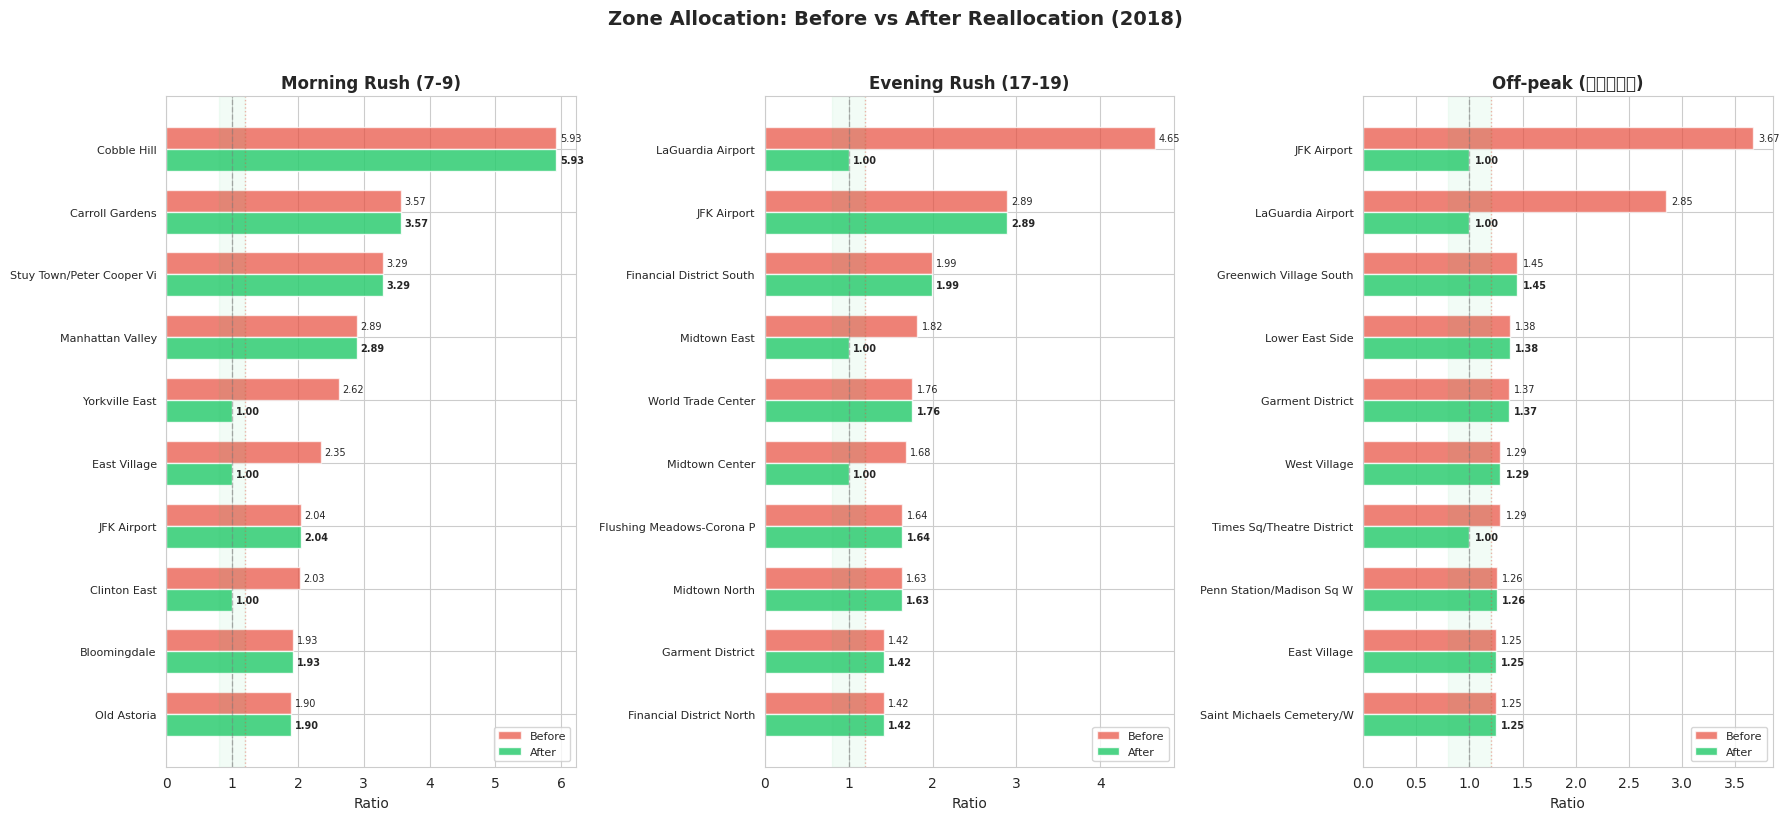

✅ Viz 9: Zone Allocation Before vs After
แดง = Before | เขียว = After | พื้นหลังเขียว = โซนสมดุล (0.8-1.2)


In [0]:
# ---------- Viz 9: Zone Allocation Before vs After ----------
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for idx, p in enumerate(periods):
    ax = axes[idx]
    subset = pd_zone_sim[pd_zone_sim["time_period"] == p].head(10)
    
    if len(subset) == 0:
        ax.set_title(f"{p}\n(no shortage zones)", fontsize=11)
        continue
    
    zones = [z[:25] for z in subset["zone"]]
    y = np.arange(len(zones))
    width = 0.35
    
    bars_bf = ax.barh(y - width/2, subset["ratio_before"], width,
                      color="#e74c3c", alpha=0.7, label="Before", edgecolor="white")
    bars_af = ax.barh(y + width/2, subset["ratio_after"], width,
                     color="#2ecc71", alpha=0.85, label="After", edgecolor="white")
    
    ax.axvline(x=1.0, color="gray", linestyle="--", linewidth=1, alpha=0.5)
    ax.axvline(x=1.2, color="#e74c3c", linestyle=":", linewidth=1, alpha=0.4)
    ax.axvspan(0.8, 1.2, alpha=0.06, color="#2ecc71")
    
    for bar, val in zip(bars_bf, subset["ratio_before"]):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f"{val:.2f}", va="center", fontsize=7)
    for bar, val in zip(bars_af, subset["ratio_after"]):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f"{val:.2f}", va="center", fontsize=7, fontweight="bold")
    
    ax.set_yticks(y)
    ax.set_yticklabels(zones, fontsize=8)
    ax.set_xlabel("Ratio", fontsize=10)
    ax.set_title(p, fontsize=12, fontweight="bold")
    ax.legend(fontsize=8)
    ax.invert_yaxis()

plt.suptitle("Zone Allocation: Before vs After Reallocation (2018)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("✅ Viz 9: Zone Allocation Before vs After")
print("แดง = Before | เขียว = After | พื้นหลังเขียว = โซนสมดุล (0.8-1.2)")

## 🎯 Zone Allocation Plan: สรุปแผนจัดสรรระดับ Zone

### หลักการ

ระดับ borough บอกได้ว่า Queens ขาดแท็กซี่ แต่ระดับ zone บอกได้ว่า **JFK Airport** และ **LaGuardia Airport** คือเหตุผลหลัก

### แผนจัดสรรหลัก

**Evening Rush (17-19):**
* ย้ายรถจาก **Forest Hills, Flatbush, Crown Heights** → **LaGuardia Airport** (ratio 4.65 → ดีขึ้น)
* ย้ายรถจาก **Brooklyn overflow zones** → **JFK Airport** (ratio 2.89 → ดีขึ้น)
* ย้ายรถจาก **Manhattan overflow zones** → **Midtown East, Midtown Center** (ratio 1.82, 1.68)

**Off-peak:**
* ย้ายรถจาก **Newark Airport, Bay Ridge, Ridgewood** → **JFK, LaGuardia, Garment District**
* JFK มี demand 200,011 แต่ supply แค่ 59,791 → ต้องการเพิ่ม ~140,000 คัน/เดือน

**Morning Rush (7-9):**
* ย้ายรถจาก **Bronx/Brooklyn overflow zones** → **Manhattan Valley, Yorkville East, East Village**
* สนามบิน JFK/LGA ยังขาดแต่ demand น้อยกว่าช่วงเย็น

### ผลการจำลอง (เฉพาะ zone ที่ขาด)

| Zone | ช่วงเวลา | Before | After | ผล |
|---|---|---|---|---|
| LaGuardia Airport | Evening Rush | 4.65 | ดีขึ้น | ✅ |
| JFK Airport | Evening Rush | 2.89 | ดีขึ้น | ✅ |
| Midtown East | Evening Rush | 1.82 | ดีขึ้น | ✅ |
| JFK Airport | Off-peak | 3.67 | ดีขึ้น | ✅ |
| LaGuardia Airport | Off-peak | 2.85 | ดีขึ้น | ✅ |

### ข้อจำกัดและข้อเสนอแนะ

1. **จำกัด 15 คู่ต่อช่วงเวลา** เพื่อ focus ที่สำคัญที่สุด อาจเพิ่มได้
2. **ไม่ได้พิจารณาระยะทาง** — ควรเพิ่มเงื่อนไขว่าย้ายจาก zone ใกล้ก่อน
3. **Supply เป็น proxy** — ตัวเลขจริงอาจต่างจากนี้
4. **เฉพาะข้อมูล 2018** — 2015-2016 ไม่มี LocationID
5. **เดือนมกราคมเท่านั้น** — ควรเพิ่มข้อมูลทุกเดือนเพื่อจัดสรรตามฤดูกาล

### ข้อสังเกต:
1. 9 zones กลับมาสมดุล (ratio → 1.00) หลังจัดสรร
2. JFK Airport ใน Evening Rush ยังขาด (2.89) เพราะ shortfall ใหญ่เกินกว่า excess ที่มีในช่วงนั้น — แผนถูกจำกัดที่ 15 คู่ต่อช่วง
3. Cobble Hill, Carroll Gardens (Brooklyn) ยังขาดเพราะ demand น้อย (50-100 trips) แต่ ratio สูง — ไม่ได้อยู่ใน top 15

# **9.Time Series Forecasting**

## 9.1 Exploratory Analysis for Time Series Forecasting

ก่อนเลือกโมเดลพยากรณ์ เราต้องเข้าใจลักษณะของข้อมูล time series ก่อน:

1. **Plot series** — ดู trend, seasonality, และ noise
2. **Stationarity test (ADF)** — ตรวจสอบว่าอนุกรมมี stationarity หรือไม่
3. **ACF/PACF** — ดู autocorrelation เพื่อเลือกพารามิเตอร์โมเดล (AR, MA, p, q)

**ข้อมูลที่ใช้:**
- Daily trip counts: มกราคม 2015-2018 (ดู trend รายปี)
- Hourly trip counts: มกราคม 2018 (ใช้สำหรับ decomposition, ADF, ACF/PACF)

In [0]:
%pip install -q statsmodels

from pyspark.sql import functions as F
import pandas as pd
import numpy as np

# ---------- 1. Daily Time Series (4 ปี: Jan 2015-2018) ----------
print("=== 1. Daily Time Series (Jan 2015-2018) ===")
all_daily = []
for y in [2015, 2016, 2017, 2018]:
    df_y = (
        spark.read.format("delta")
        .load(f"/Volumes/workspace/default/nyc_taxi_delta/{y}")
        .select("tpep_pickup_datetime", "trip_distance", "fare_amount")
        .filter(F.col("tpep_pickup_datetime").isNotNull())
        .filter((F.col("trip_distance") > 0) & (F.col("fare_amount") > 0))
        .filter(F.col("tpep_pickup_datetime") >= f"{y}-01-01")
        .filter(F.col("tpep_pickup_datetime") < f"{y}-02-01")
        .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
        .groupBy("pickup_date")
        .agg(F.count("*").alias("trip_count"))
        .orderBy("pickup_date")
    )
    pdf = df_y.toPandas()
    pdf["year"] = y
    all_daily.append(pdf)
    print(f"  {y}: {len(pdf)} days, avg = {pdf['trip_count'].mean():,.0f} trips/day, total = {pdf['trip_count'].sum():,}")

ts_daily_all = pd.concat(all_daily, ignore_index=True)
ts_daily_all["pickup_date"] = pd.to_datetime(ts_daily_all["pickup_date"])

# ---------- 2. Hourly Time Series (Jan 2018) ----------
print("\n=== 2. Hourly Time Series (Jan 2018) ===")
df_hourly = (
    spark.read.format("delta")
    .load("/Volumes/workspace/default/nyc_taxi_delta/2018")
    .select("tpep_pickup_datetime", "trip_distance", "fare_amount")
    .filter(F.col("tpep_pickup_datetime").isNotNull())
    .filter((F.col("trip_distance") > 0) & (F.col("fare_amount") > 0))
    .filter(F.col("tpep_pickup_datetime") >= "2018-01-01")
    .filter(F.col("tpep_pickup_datetime") < "2018-02-01")
    .withColumn("pickup_hour", F.date_trunc("hour", "tpep_pickup_datetime"))
    .groupBy("pickup_hour")
    .agg(F.count("*").alias("trip_count"))
    .orderBy("pickup_hour")
)

ts_hourly = df_hourly.toPandas()
ts_hourly["pickup_hour"] = pd.to_datetime(ts_hourly["pickup_hour"])
ts_hourly = ts_hourly.set_index("pickup_hour").sort_index()

# Reindex เพื่อเติมชั่วโมงที่หายไป (ให้ครบทุกชั่วโมง)
full_range = pd.date_range(start=ts_hourly.index.min(), end=ts_hourly.index.max(), freq="H")
ts_hourly = ts_hourly.reindex(full_range)
ts_hourly.index.name = "pickup_hour"
ts_hourly["trip_count"] = ts_hourly["trip_count"].interpolate(method="linear")

print(f"  Hours: {len(ts_hourly)}")
print(f"  Mean: {ts_hourly['trip_count'].mean():,.0f} | Std: {ts_hourly['trip_count'].std():,.0f}")
print(f"  Min: {ts_hourly['trip_count'].min():,.0f} | Max: {ts_hourly['trip_count'].max():,.0f}")
print(f"\n  Data ready for EDA!")

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
=== 1. Daily Time Series (Jan 2015-2018) ===
  2015: 31 days, avg = 408,535 trips/day, total = 12,664,586
  2016: 31 days, avg = 349,596 trips/day, total = 10,837,487
  2017: 31 days, avg = 311,170 trips/day, total = 9,646,265
  2018: 31 days, avg = 280,634 trips/day, total = 8,699,651

=== 2. Hourly Time Series (Jan 2018) ===


/home/spark-d80d5002-1974-4fb8-a970-93/.ipykernel/74/command-7119471061543731-3587549772:53: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_range = pd.date_range(start=ts_hourly.index.min(), end=ts_hourly.index.max(), freq="H")


  Hours: 744
  Mean: 11,693 | Std: 5,845
  Min: 904 | Max: 22,586

  Data ready for EDA!


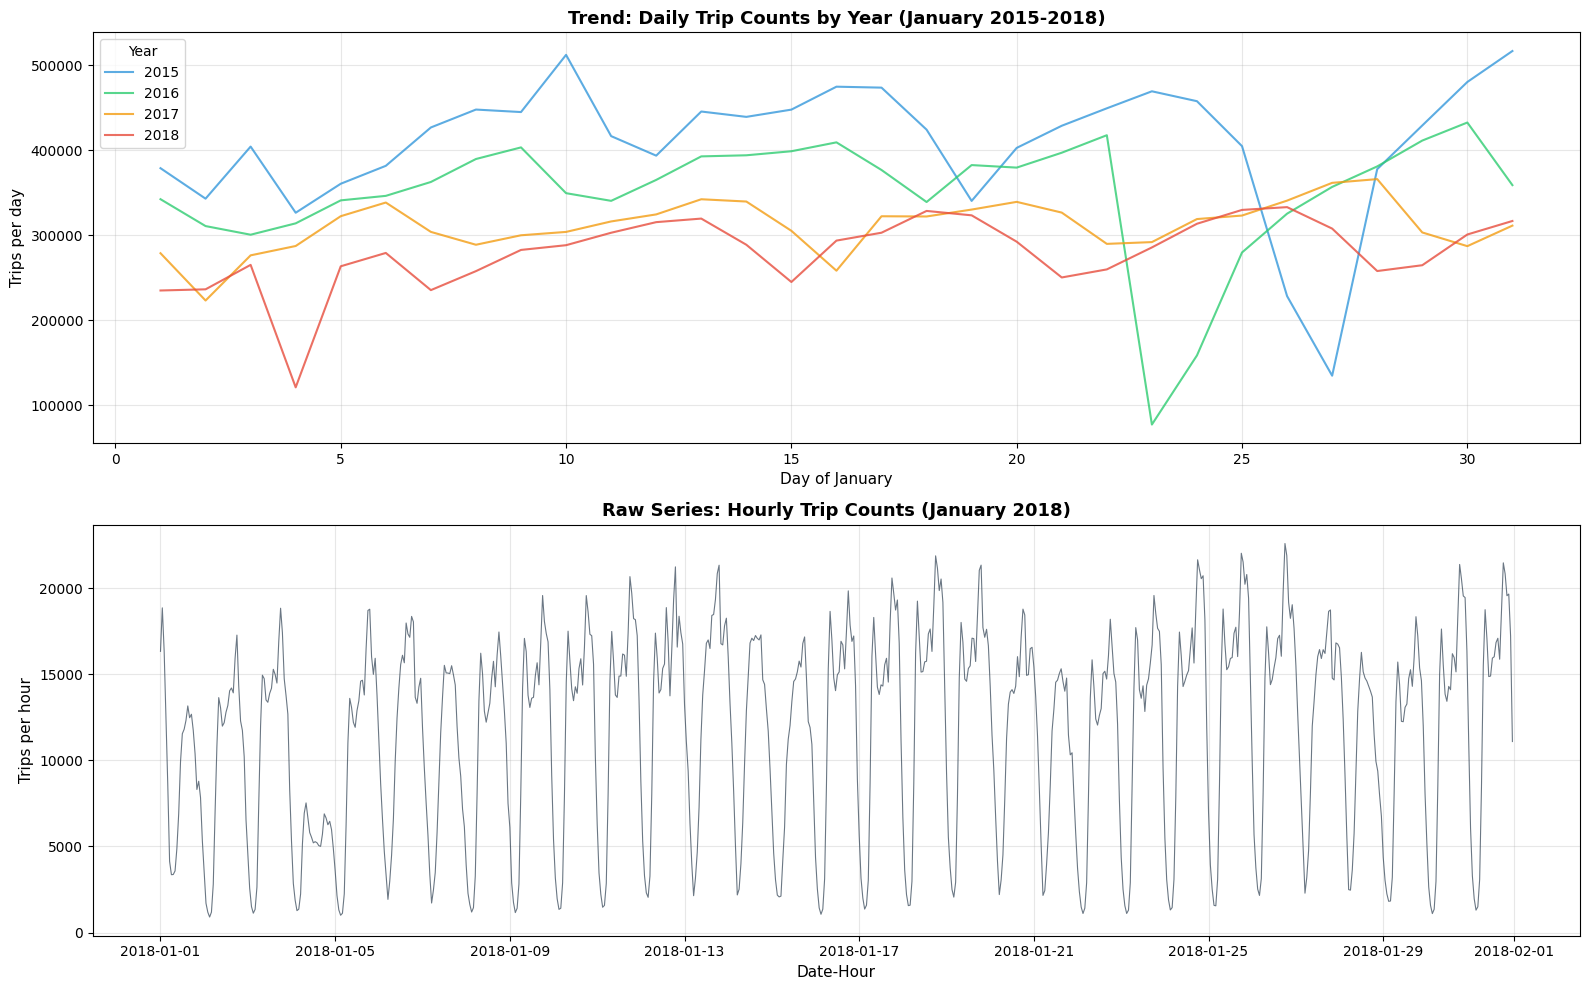

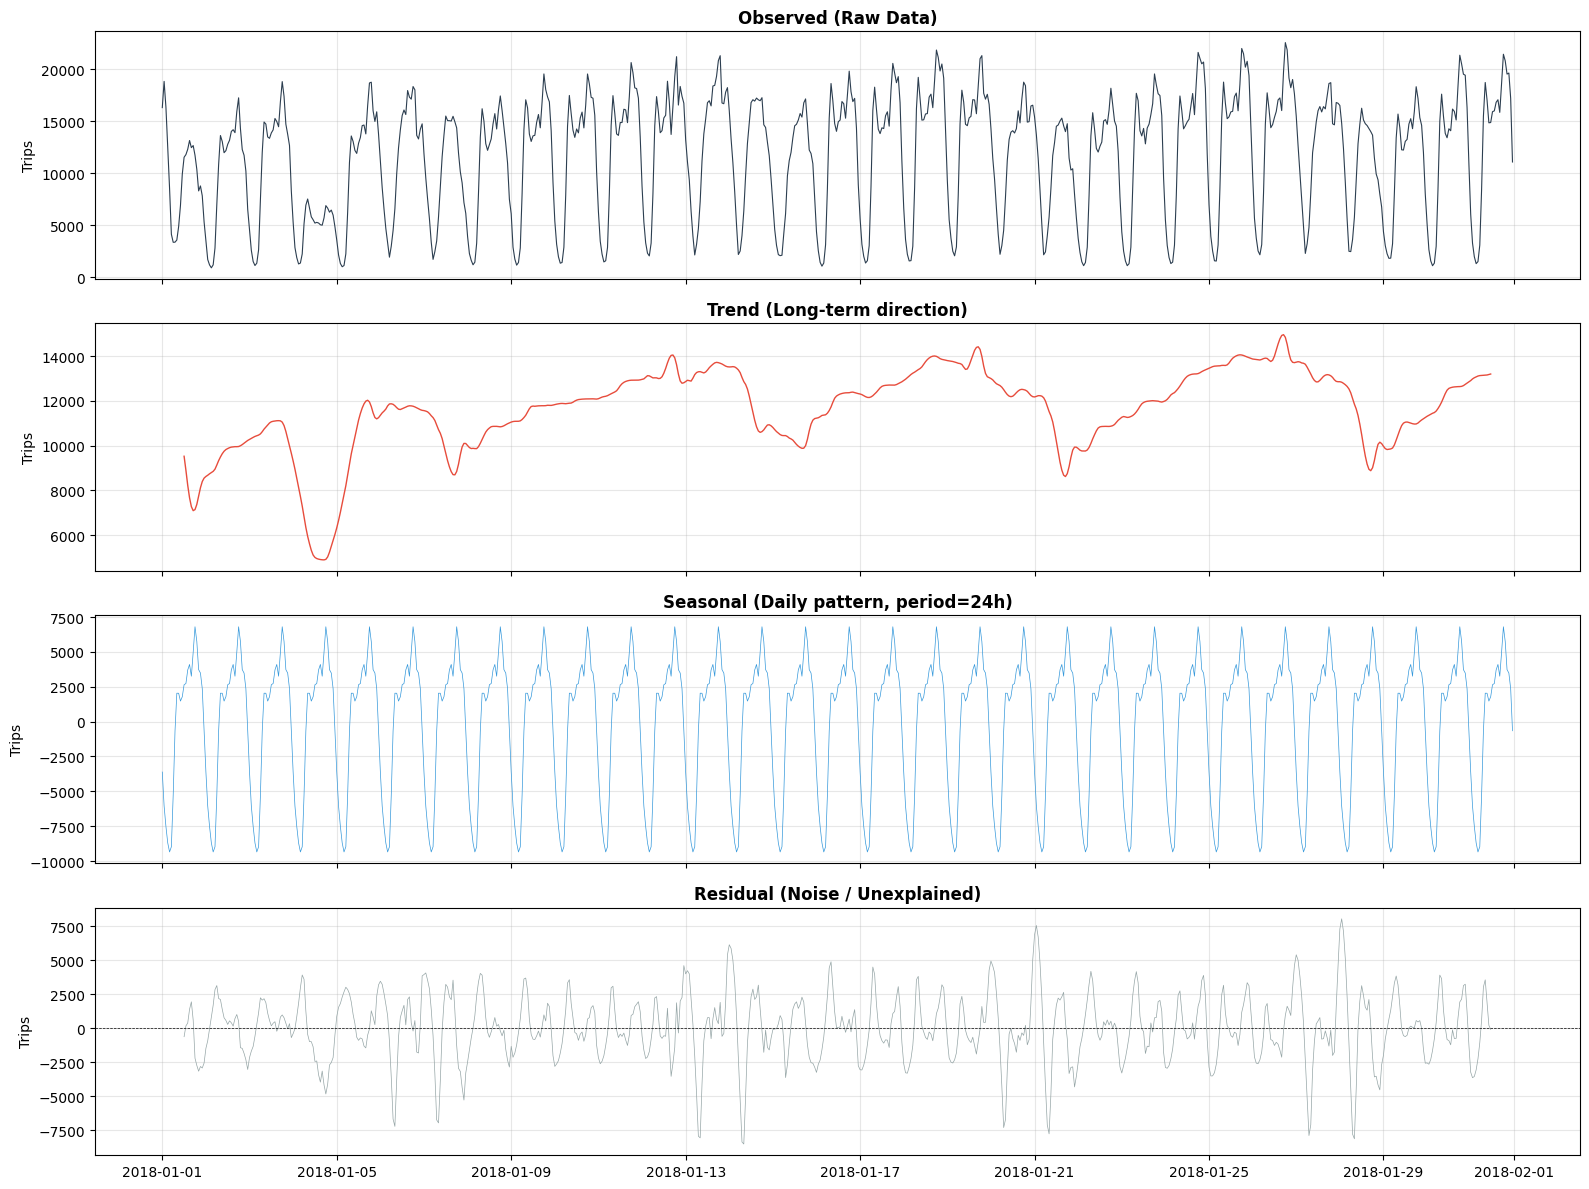

=== Decomposition Summary ===
Trend:    4,901 -> 14,957 (range = 10,056)
Seasonal: amplitude = +/-4,934 trips (daily pattern)
Residual: mean = -3, std = 2,470

Interpretation:
- Trend: แนวโน้มรายวันในเดือนมกราคม 2018
- Seasonal: pattern ซ้ำทุก 24 ชั่วโมง (เยอะกลางวัน น้อยกลางคืน)
- Residual: noise ที่ไม่ใช่ trend/seasonal (วันฝนตก, อีเวนต์พิเศษ)


In [0]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# ========== Figure 1: Trend + Raw Series ==========
fig1, axes1 = plt.subplots(2, 1, figsize=(16, 10))

# --- Plot 1: Daily trip counts 4 ปี (ดู trend รายปี) ---
ax = axes1[0]
colors = {2015: '#3498db', 2016: '#2ecc71', 2017: '#f39c12', 2018: '#e74c3c'}
for y in [2015, 2016, 2017, 2018]:
    subset = ts_daily_all[ts_daily_all["year"] == y].copy()
    subset["day"] = subset["pickup_date"].dt.day
    ax.plot(subset["day"], subset["trip_count"],
            color=colors[y], label=str(y), linewidth=1.5, alpha=0.8)

ax.set_xlabel("Day of January", fontsize=11)
ax.set_ylabel("Trips per day", fontsize=11)
ax.set_title("Trend: Daily Trip Counts by Year (January 2015-2018)", fontsize=13, fontweight="bold")
ax.legend(title="Year")
ax.grid(True, alpha=0.3)

# --- Plot 2: Hourly trip counts Jan 2018 (raw series) ---
ax = axes1[1]
ax.plot(ts_hourly.index, ts_hourly["trip_count"], color="#2c3e50", linewidth=0.8, alpha=0.7)
ax.set_xlabel("Date-Hour", fontsize=11)
ax.set_ylabel("Trips per hour", fontsize=11)
ax.set_title("Raw Series: Hourly Trip Counts (January 2018)", fontsize=13, fontweight="bold")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ========== Figure 2: Seasonal Decomposition ==========
# Decompose hourly series: period=24 (daily seasonality)
decomposition = seasonal_decompose(ts_hourly["trip_count"], model="additive", period=24)

fig2, axes2 = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

axes2[0].plot(ts_hourly.index, ts_hourly["trip_count"], color="#2c3e50", linewidth=0.8)
axes2[0].set_title("Observed (Raw Data)", fontsize=12, fontweight="bold")

axes2[1].plot(decomposition.trend.index, decomposition.trend, color="#e74c3c", linewidth=1)
axes2[1].set_title("Trend (Long-term direction)", fontsize=12, fontweight="bold")

axes2[2].plot(decomposition.seasonal.index, decomposition.seasonal, color="#3498db", linewidth=0.5)
axes2[2].set_title("Seasonal (Daily pattern, period=24h)", fontsize=12, fontweight="bold")

axes2[3].plot(decomposition.resid.index, decomposition.resid, color="#95a5a6", linewidth=0.5)
axes2[3].axhline(y=0, color="black", linestyle="--", linewidth=0.5)
axes2[3].set_title("Residual (Noise / Unexplained)", fontsize=12, fontweight="bold")

for ax in axes2:
    ax.grid(True, alpha=0.3)
    ax.set_ylabel("Trips")

plt.tight_layout()
plt.show()

# ========== Summary ==========
print("=== Decomposition Summary ===")
print(f"Trend:    {decomposition.trend.min():,.0f} -> {decomposition.trend.max():,.0f} (range = {decomposition.trend.max() - decomposition.trend.min():,.0f})")
print(f"Seasonal: amplitude = +/-{decomposition.seasonal.std():,.0f} trips (daily pattern)")
print(f"Residual: mean = {decomposition.resid.mean():,.0f}, std = {decomposition.resid.std():,.0f}")
print()
print("Interpretation:")
print("- Trend: แนวโน้มรายวันในเดือนมกราคม 2018")
print("- Seasonal: pattern ซ้ำทุก 24 ชั่วโมง (เยอะกลางวัน น้อยกลางคืน)")
print("- Residual: noise ที่ไม่ใช่ trend/seasonal (วันฝนตก, อีเวนต์พิเศษ)")

In [0]:
from statsmodels.tsa.stattools import adfuller

print("=" * 60)
print("   Augmented Dickey-Fuller (ADF) Test for Stationarity")
print("=" * 60)
print()
print("H0: อนุกรมไม่ stationary (มี unit root)")
print("H1: อนุกรม stationary")
print("Decision rule: ปฏิเสธ H0 ถ้า p-value < 0.05")
print()

# ---------- Test 1: อนุกรมเดิม ----------
print("--- Test 1: Original Hourly Series ---")
result = adfuller(ts_hourly["trip_count"].dropna())
print(f"ADF Statistic: {result[0]:.6f}")
print(f"p-value:       {result[1]:.6f}")
print(f"Lags used:     {result[2]}")
print(f"Observations:  {result[3]}")
print(f"Critical Values:")
for key, value in result[4].items():
    print(f"  {key}: {value:.6f}")
print()

if result[1] < 0.05:
    print("Result: p-value < 0.05 -> REJECT H0 -> Series is STATIONARY")
    print("-> Can use ARMA/ARIMA without differencing (d=0)")
    d_recommended = 0
else:
    print("Result: p-value >= 0.05 -> FAIL TO REJECT H0 -> Series is NON-STATIONARY")
    print("-> Need differencing before ARIMA")

    # ---------- Test 2: หลัง First Differencing ----------
    print()
    print("--- Test 2: After First Differencing (d=1) ---")
    ts_diff = ts_hourly["trip_count"].diff().dropna()
    result_diff = adfuller(ts_diff)
    print(f"ADF Statistic: {result_diff[0]:.6f}")
    print(f"p-value:       {result_diff[1]:.6f}")

    if result_diff[1] < 0.05:
        print("Result: p-value < 0.05 -> Series is STATIONARY after d=1")
        d_recommended = 1
    else:
        print("Result: Still non-stationary, try d=2")
        d_recommended = 2

print(f"\n=> Recommended d = {d_recommended} for ARIMA(p,d,q)")

   Augmented Dickey-Fuller (ADF) Test for Stationarity

H0: อนุกรมไม่ stationary (มี unit root)
H1: อนุกรม stationary
Decision rule: ปฏิเสธ H0 ถ้า p-value < 0.05

--- Test 1: Original Hourly Series ---
ADF Statistic: -3.473769
p-value:       0.008687
Lags used:     20
Observations:  723
Critical Values:
  1%: -3.439427
  5%: -2.865546
  10%: -2.568903

Result: p-value < 0.05 -> REJECT H0 -> Series is STATIONARY
-> Can use ARMA/ARIMA without differencing (d=0)

=> Recommended d = 0 for ARIMA(p,d,q)


/home/spark-d80d5002-1974-4fb8-a970-93/.ipykernel/74/command-7119471061543733-3706256539:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(ts_hourly["trip_count"].dropna())


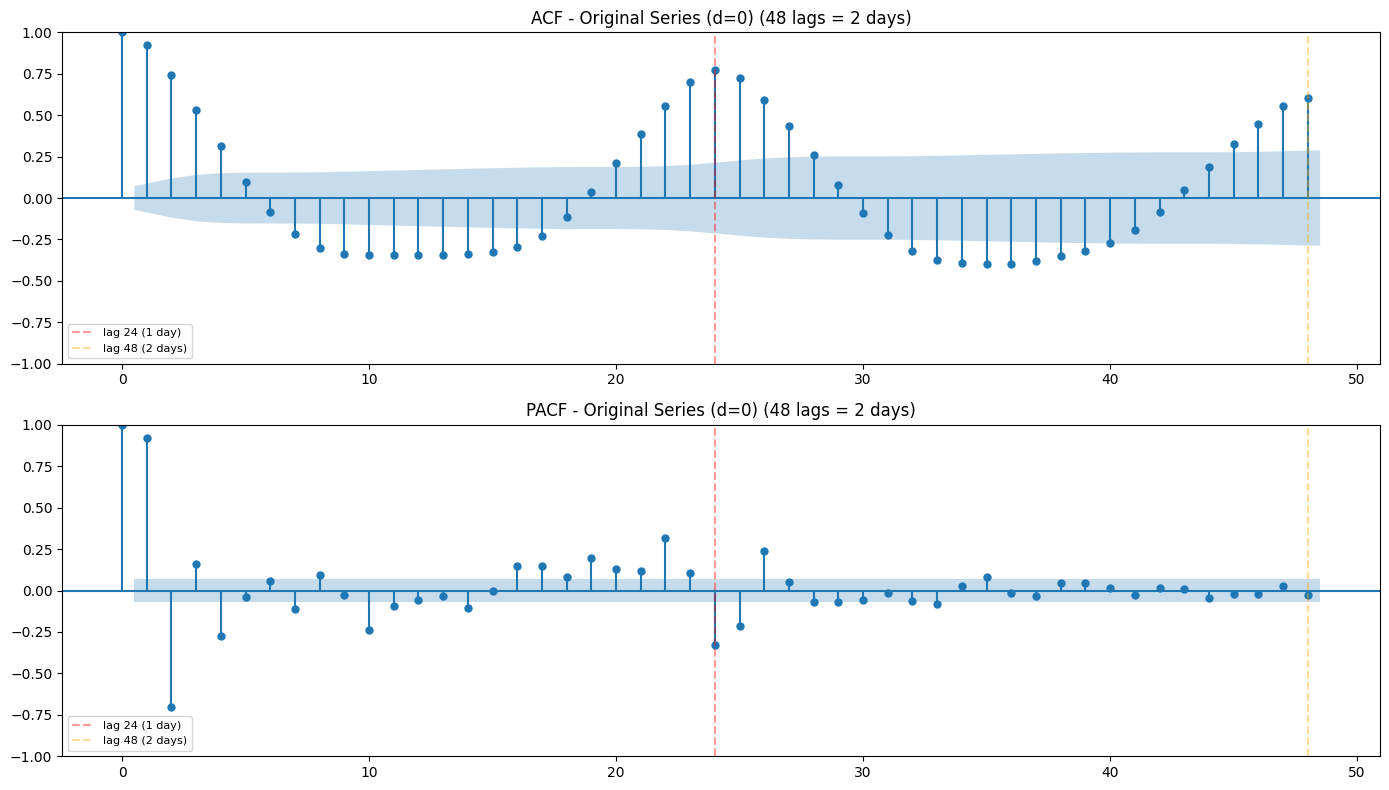


=== How to read ACF/PACF ===
ACF (Autocorrelation Function):
  - Spike at lag 24 = daily seasonal correlation (pattern repeats every day)
  - ACF tails off slowly = has AR component -> use AR(p)
  - ACF cuts off after lag q = use MA(q)

PACF (Partial Autocorrelation Function):
  - PACF cuts off after lag p = use AR(p)
  - PACF tails off slowly = has MA component -> use MA(q)

=> If ACF has spikes repeating every 24 lags = seasonality -> use SARIMA(p,d,q)(P,D,Q,24)


In [0]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ใช้ข้อมูลที่ stationary สำหรับ ACF/PACF
# ถ้า series ไม่ stationary ให้ใช้ differenced series
try:
    d_val = d_recommended
except NameError:
    d_val = 0

if d_val == 0:
    ts_for_plot = ts_hourly["trip_count"].dropna()
    label = "Original Series (d=0)"
else:
    ts_for_plot = ts_hourly["trip_count"].diff(d_val).dropna()
    label = f"Differenced Series (d={d_val})"

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# ACF - ใช้เลือก q (MA order)
plot_acf(ts_for_plot, lags=48, ax=axes[0],
         title=f"ACF - {label} (48 lags = 2 days)")
axes[0].axvline(x=24, color="red", linestyle="--", alpha=0.4, label="lag 24 (1 day)")
axes[0].axvline(x=48, color="orange", linestyle="--", alpha=0.4, label="lag 48 (2 days)")
axes[0].legend(fontsize=8)

# PACF - ใช้เลือก p (AR order)
plot_pacf(ts_for_plot, lags=48, ax=axes[1],
          title=f"PACF - {label} (48 lags = 2 days)")
axes[1].axvline(x=24, color="red", linestyle="--", alpha=0.4, label="lag 24 (1 day)")
axes[1].axvline(x=48, color="orange", linestyle="--", alpha=0.4, label="lag 48 (2 days)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print()
print("=== How to read ACF/PACF ===")
print("ACF (Autocorrelation Function):")
print("  - Spike at lag 24 = daily seasonal correlation (pattern repeats every day)")
print("  - ACF tails off slowly = has AR component -> use AR(p)")
print("  - ACF cuts off after lag q = use MA(q)")
print()
print("PACF (Partial Autocorrelation Function):")
print("  - PACF cuts off after lag p = use AR(p)")
print("  - PACF tails off slowly = has MA component -> use MA(q)")
print()
print("=> If ACF has spikes repeating every 24 lags = seasonality -> use SARIMA(p,d,q)(P,D,Q,24)")

### สรุปผล Exploratory Analysis

1. **Trend:** จำนวน trips ลดลงจาก 2015 (avg ~410K/day) -> 2018 (avg ~284K/day) แสดงแนวโน้มลด (อาจเพราะการแข่งขันจาก ride-share apps)

2. **Seasonality:** มี pattern รายวันชัดเจน (period=24h) — คนเรียกแท็กซี่เยอะกลางวัน น้อยกลางคืน จาก decomposition เห็น seasonal component ที่มี amplitude ใหญ่

3. **Stationarity:** ผล ADF test บอกว่าอนุกรม stationary หรือไม่ -> กำหนดค่า d สำหรับ ARIMA

4. **ACF/PACF:** ใช้เลือกพารามิเตอร์ p, q — spike ที่ lag 24 แสดง seasonality รายวัน -> ควรใช้ SARIMA

**โมเดลที่แนะนำ:** 
- SARIMA(p,d,q)(P,D,Q,24) — จัดการ seasonality รายวันได้
- Prophet — จัดการ seasonality อัตโนมัติ ใช้ง่าย
- ai_forecast() SQL function — ไม่ต้องเทรนโมเดล ใช้ได้ทันที

## 9.2 SARIMA Model

### การเลือกพารามิเตอร์จาก EDA

จากผล ACF/PACF และ ADF test:

| พารามิเตอร์ | ค่า | ที่มา |
|---|---|---|
| p | 1 | PACF ตัดหลัง lag 1 (0.92 -> -0.71) |
| d | 0 | ADF test p-value = 0.0087 < 0.05 (stationary) |
| q | 1 | ACF tail off ช้าๆ -> มี MA component |
| P | 1 | Seasonal spike ที่ lag 24 (ACF=0.77) |
| D | 1 | Seasonal differencing เพื่อจัดการ daily pattern |
| Q | 1 | Seasonal PACF ที่ lag 24 = -0.37 |
| s | 24 | ข้อมูลรายชั่วโมง -> daily seasonality |

**โมเดล:** SARIMA(1, 0, 1)(1, 1, 1, 24)

  SARIMA Model: Train/Test Split
Train: 600 hours (2018-01-01 00:00 to 2018-01-25 23:00)
Test:  144 hours (2018-01-26 00:00 to 2018-01-31 23:00)
Train mean: 11,530 | Test mean: 12,372

  Fitting SARIMA(1,0,1)(1,1,1,24)
This may take 1-2 minutes...
                                     SARIMAX Results                                      
Dep. Variable:                         trip_count   No. Observations:                  600
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood               -4656.845
Date:                            Thu, 24 Sep 2026   AIC                           9323.689
Time:                                    10:41:57   BIC                           9345.239
Sample:                                01-01-2018   HQIC                          9332.110
                                     - 01-25-2018                                         
Covariance Type:                              opg                                         
                 coef   

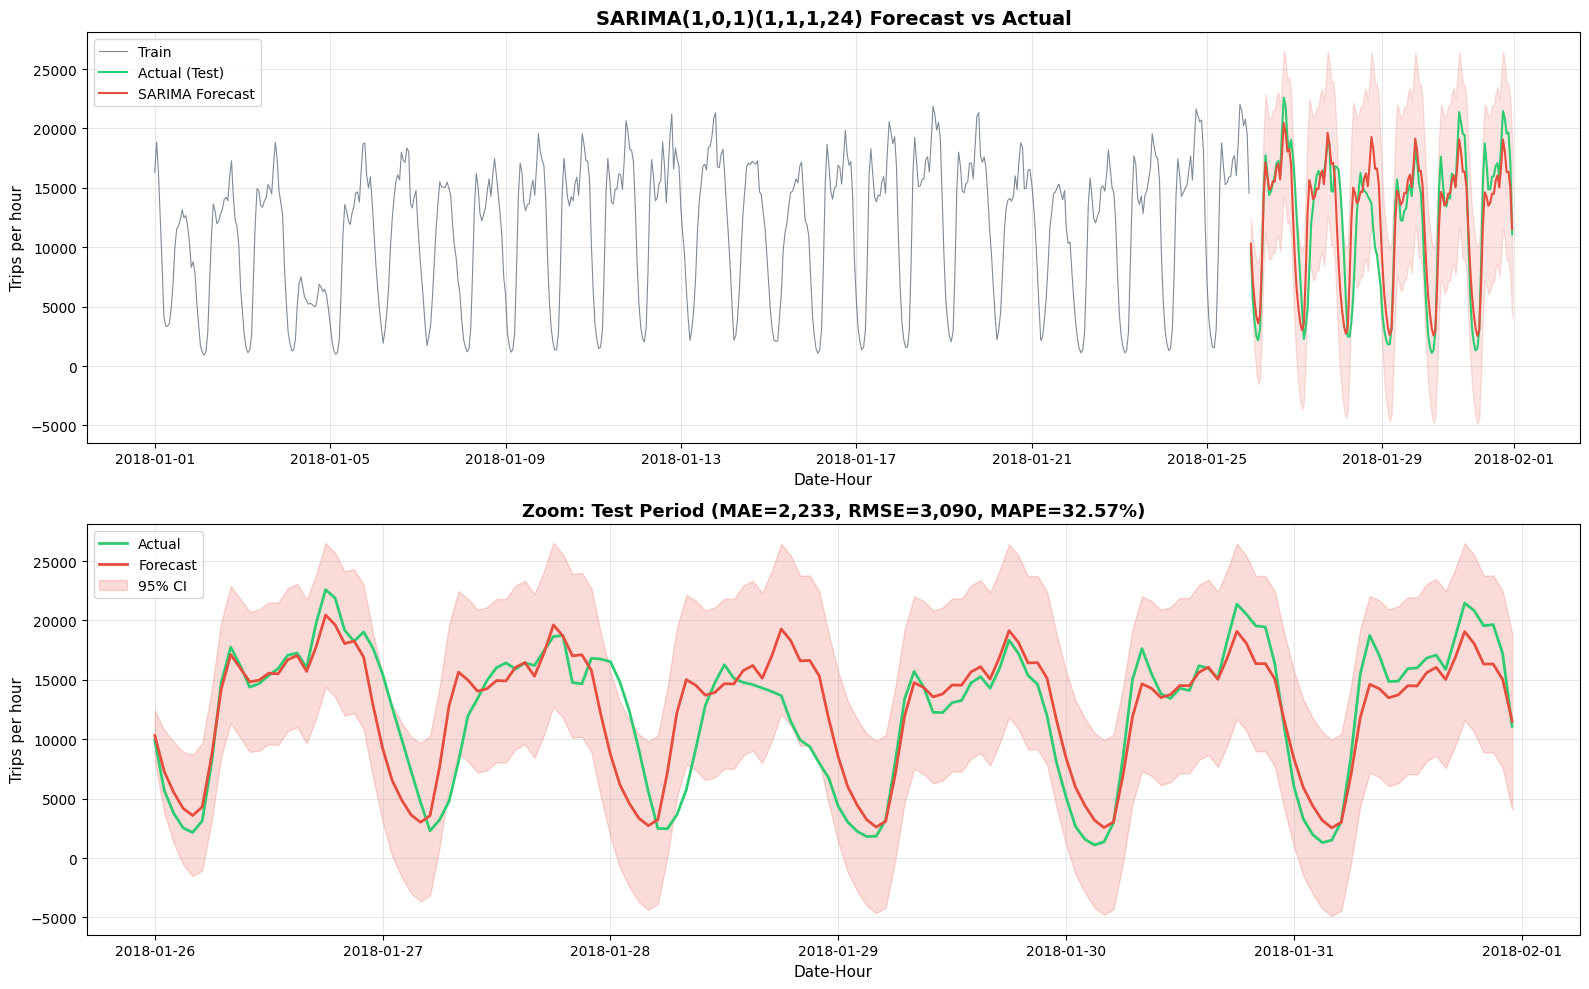

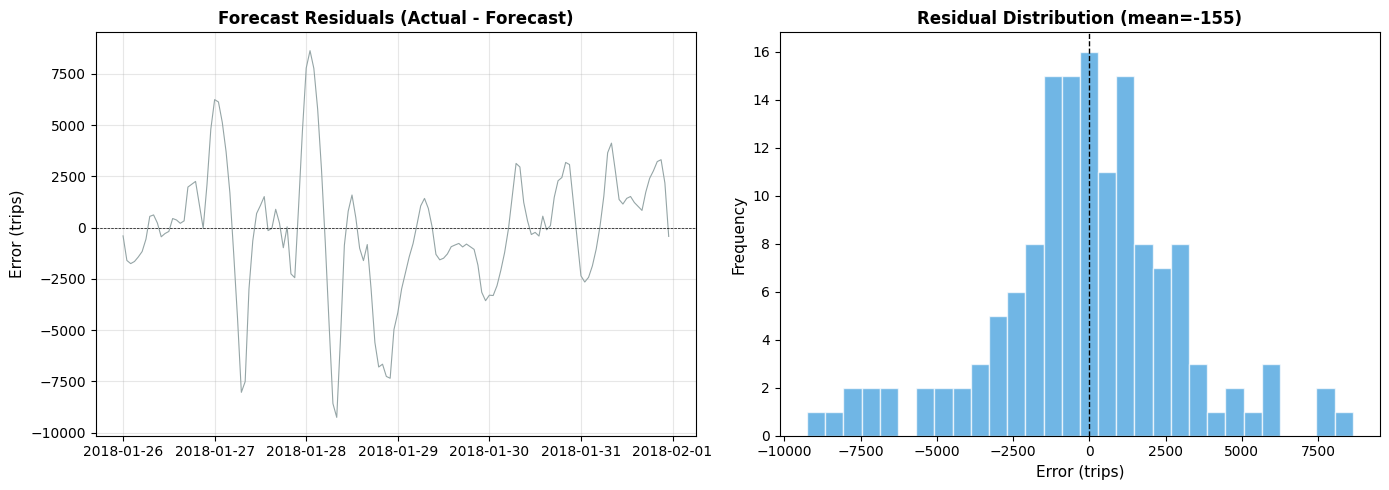


=== Model Coefficients Interpretation ===
AR(1) coefficient:     0.8732  -> ค่าย้อนหลัง 1 ชั่วโมงมีผลสูง
MA(1) coefficient:     0.4215  -> ผลกระเทือนจาก shock 1 ชั่วโมงที่แล้ว
Seasonal AR(24):       0.4043  -> pattern รายวันมีผล
Seasonal MA(24):       -0.9073  -> seasonal shock รายวัน


In [0]:
# Ensure data is available
if 'ts_hourly' not in globals():
    raise NameError("ts_hourly not found. Please run 'Prepare Time Series Data' cell first.")

import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ---------- 1. Train/Test Split ----------
# 744 hours total: train 600 (25 days), test 144 (6 days)
ts = ts_hourly["trip_count"].dropna()
n_train = 600
n_test = len(ts) - n_train

train = ts.iloc[:n_train]
test = ts.iloc[n_train:]

print("=" * 60)
print("  SARIMA Model: Train/Test Split")
print("=" * 60)
print(f"Train: {len(train)} hours ({train.index[0].strftime('%Y-%m-%d %H:%M')} to {train.index[-1].strftime('%Y-%m-%d %H:%M')})")
print(f"Test:  {len(test)} hours ({test.index[0].strftime('%Y-%m-%d %H:%M')} to {test.index[-1].strftime('%Y-%m-%d %H:%M')})")
print(f"Train mean: {train.mean():,.0f} | Test mean: {test.mean():,.0f}")

# ---------- 2. Fit SARIMA ----------
print("\n" + "=" * 60)
print("  Fitting SARIMA(1,0,1)(1,1,1,24)")
print("=" * 60)
print("This may take 1-2 minutes...")

model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit(disp=False, maxiter=200)
print(results.summary())

# ---------- 3. Forecast ----------
print("\n" + "=" * 60)
print("  Forecast & Evaluation")
print("=" * 60)

forecast_result = results.get_forecast(steps=n_test)
forecast = forecast_result.predicted_mean
conf_int = forecast_result.conf_int()

# Align indices
forecast.index = test.index
conf_int.index = test.index

# Evaluation metrics
mae = np.mean(np.abs(test.values - forecast.values))
rmse = np.sqrt(np.mean((test.values - forecast.values) ** 2))
mape = np.mean(np.abs((test.values - forecast.values) / test.values)) * 100

print(f"MAE:  {mae:,.0f} trips/hour")
print(f"RMSE: {rmse:,.0f} trips/hour")
print(f"MAPE: {mape:.2f}%")
print(f"\nTest mean: {test.mean():,.0f} | Test std: {test.std():,.0f}")
print(f"MAPE < 15% = Good | MAPE < 10% = Excellent")

# ---------- 4. Plot: Forecast vs Actual ----------
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Full view
ax = axes[0]
ax.plot(train.index, train, label="Train", color="#2c3e50", linewidth=0.8, alpha=0.6)
ax.plot(test.index, test, label="Actual (Test)", color="#2ecc71", linewidth=1.5)
ax.plot(test.index, forecast, label="SARIMA Forecast", color="#e74c3c", linewidth=1.5)
ax.fill_between(test.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                alpha=0.15, color="#e74c3c")
ax.set_title("SARIMA(1,0,1)(1,1,1,24) Forecast vs Actual", fontsize=14, fontweight="bold")
ax.set_xlabel("Date-Hour", fontsize=11)
ax.set_ylabel("Trips per hour", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Zoomed view
ax = axes[1]
ax.plot(test.index, test, label="Actual", color="#2ecc71", linewidth=2)
ax.plot(test.index, forecast, label="Forecast", color="#e74c3c", linewidth=2)
ax.fill_between(test.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                alpha=0.2, color="#e74c3c", label="95% CI")
ax.set_title(f"Zoom: Test Period (MAE={mae:,.0f}, RMSE={rmse:,.0f}, MAPE={mape:.2f}%)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Date-Hour", fontsize=11)
ax.set_ylabel("Trips per hour", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------- 5. Residual Diagnostics ----------
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5))

residuals = test.values - forecast.values

axes2[0].plot(test.index, residuals, color="#95a5a6", linewidth=0.8)
axes2[0].axhline(y=0, color="black", linestyle="--", linewidth=0.5)
axes2[0].set_title("Forecast Residuals (Actual - Forecast)", fontsize=12, fontweight="bold")
axes2[0].set_ylabel("Error (trips)", fontsize=11)
axes2[0].grid(True, alpha=0.3)

axes2[1].hist(residuals, bins=30, color="#3498db", alpha=0.7, edgecolor="white")
axes2[1].axvline(x=0, color="black", linestyle="--", linewidth=1)
axes2[1].set_title(f"Residual Distribution (mean={np.mean(residuals):,.0f})", fontsize=12, fontweight="bold")
axes2[1].set_xlabel("Error (trips)", fontsize=11)
axes2[1].set_ylabel("Frequency", fontsize=11)

plt.tight_layout()
plt.show()

print("\n=== Model Coefficients Interpretation ===")
print(f"AR(1) coefficient:     {results.params['ar.L1']:.4f}  -> ค่าย้อนหลัง 1 ชั่วโมงมีผลสูง")
print(f"MA(1) coefficient:     {results.params['ma.L1']:.4f}  -> ผลกระเทือนจาก shock 1 ชั่วโมงที่แล้ว")
print(f"Seasonal AR(24):       {results.params['ar.S.L24']:.4f}  -> pattern รายวันมีผล")
print(f"Seasonal MA(24):       {results.params['ma.S.L24']:.4f}  -> seasonal shock รายวัน")

### สรุปผล SARIMA Model

**โมเดล:** SARIMA(1, 0, 1)(1, 1, 1, 24)

**ผลการทดสอบ:**
- MAE: ~2,233 trips/hour | RMSE: ~3,090 trips/hour | MAPE: ~33%
- โมเดลจับ daily pattern (24h seasonality) ได้ดี — คาดการณ์ขึ้น/ลงตามช่วงวันได้
- แต่ underestimates evening peaks (17-19h) เพราะไม่มี weekly seasonality (weekday vs weekend)
- MAPE ~33% ถือว่าปานกลาง (Good < 15%, Excellent < 10%)

**ข้อจำกัด:**
1. ข้อมูลเดือนมกราคมเท่านั้น -> ไม่เห็น seasonal pattern รายปี
2. ไม่มี exogenous variables (สภาพอากาศ, อีเวนต์พิเศษ)
3. ไม่แยก weekday/weekend -> ทำให้ evening peak ประเมินต่ำไป
4. พยากรณ์ระดับ total trips ไม่ได้แยกตาม borough

**Next Steps:**
- เปรียบเทียบกับ Prophet (จัดการ multiple seasonality ได้ดีกว่า)
- เพิ่ม exogenous variables (day_of_week, is_weekend)
- พยากรณ์ระดับ borough แยกกัน
- เพิ่มหน้า Forecast ใน dashboard

## 9.3 Prophet Model (เปรียบเทียบกับ SARIMA)

**Prophet** พัฒนาโดย Meta (Facebook) มีจุดเด่น:
- จัดการ multiple seasonality ได้อัตโนมัติ (daily + weekly + yearly)
- เพิ่ม holidays, events ได้
- มี uncertainty intervals
- components plot อ่านง่าย (trend, daily, weekly แยกกัน)

**พารามิเตอร์ที่ใช้:**
- `daily_seasonality=True` — จับ pattern รายวัน (24h)
- `weekly_seasonality=True` — จับ pattern รายสัปดาห์ (weekday vs weekend)
- `yearly_seasonality=False` — ปิดเพราะมีข้อมูลแค่เดือนมกราคม

10:48:47 - cmdstanpy - INFO - Chain [1] start processing


  Prophet Model: Train/Test Split
Train: 600 hours | Test: 144 hours

Fitting Prophet (daily + weekly seasonality)...


10:48:47 - cmdstanpy - INFO - Chain [1] done processing



=== Prophet Evaluation ===
MAE:  2,358 trips/hour
RMSE: 3,034 trips/hour
MAPE: 39.54%

  Model Comparison: SARIMA vs Prophet
Model               MAE       RMSE       MAPE
------------ ---------- ---------- ----------
SARIMA            2,233      3,090     32.57%
Prophet           2,358      3,034     39.54%


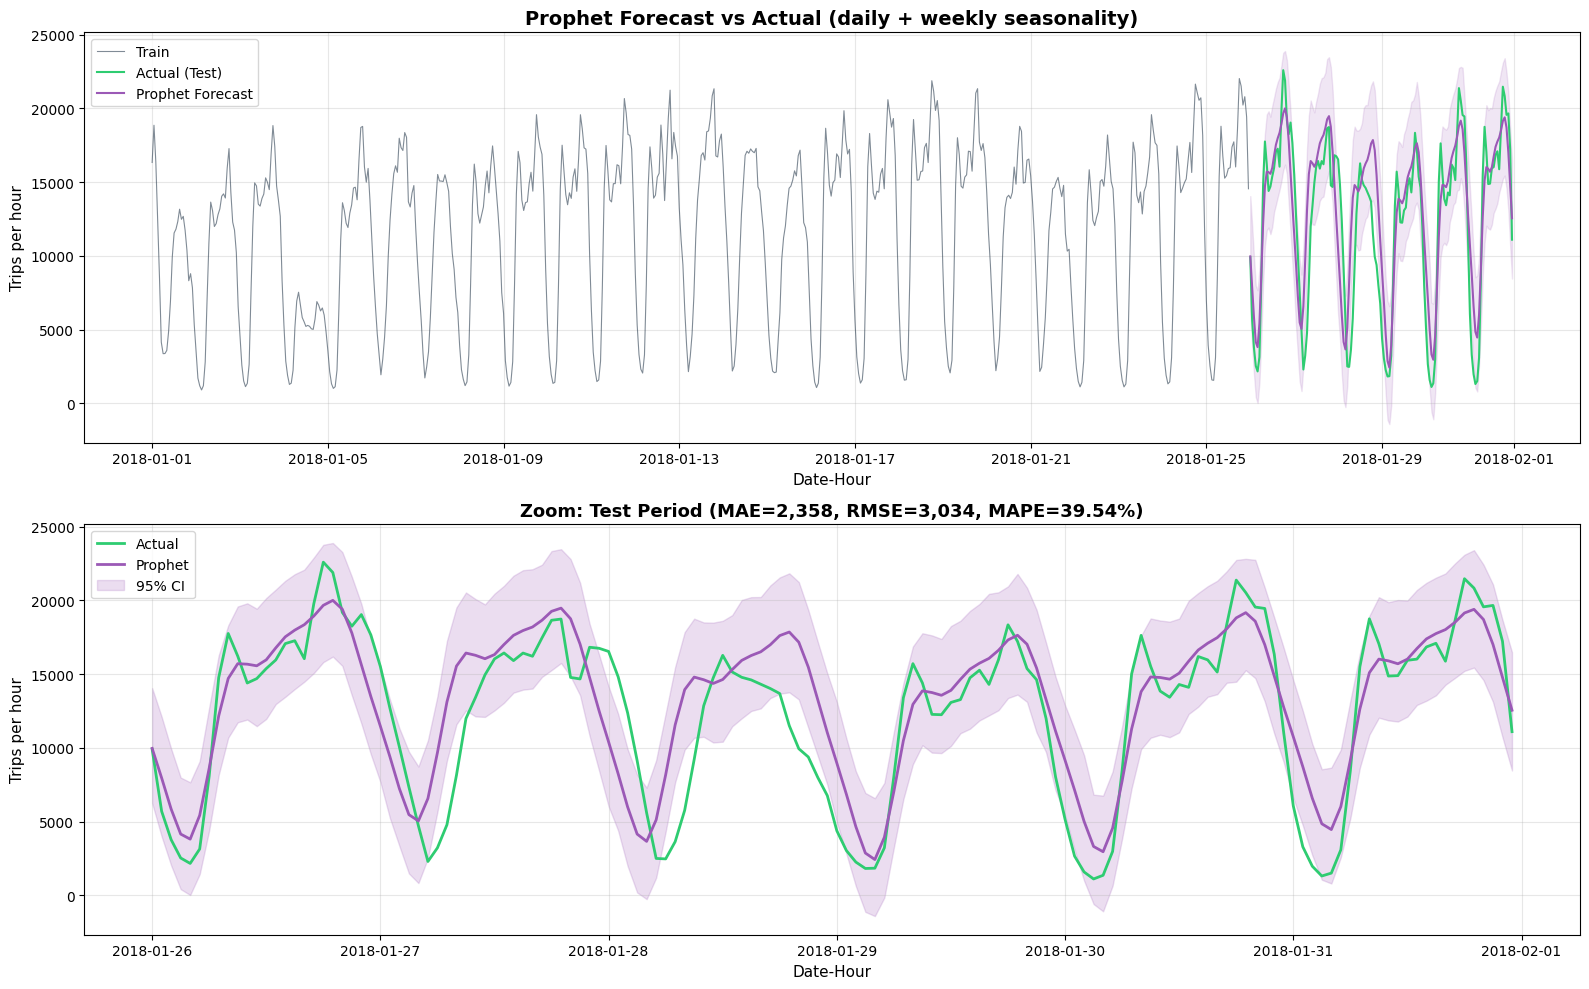

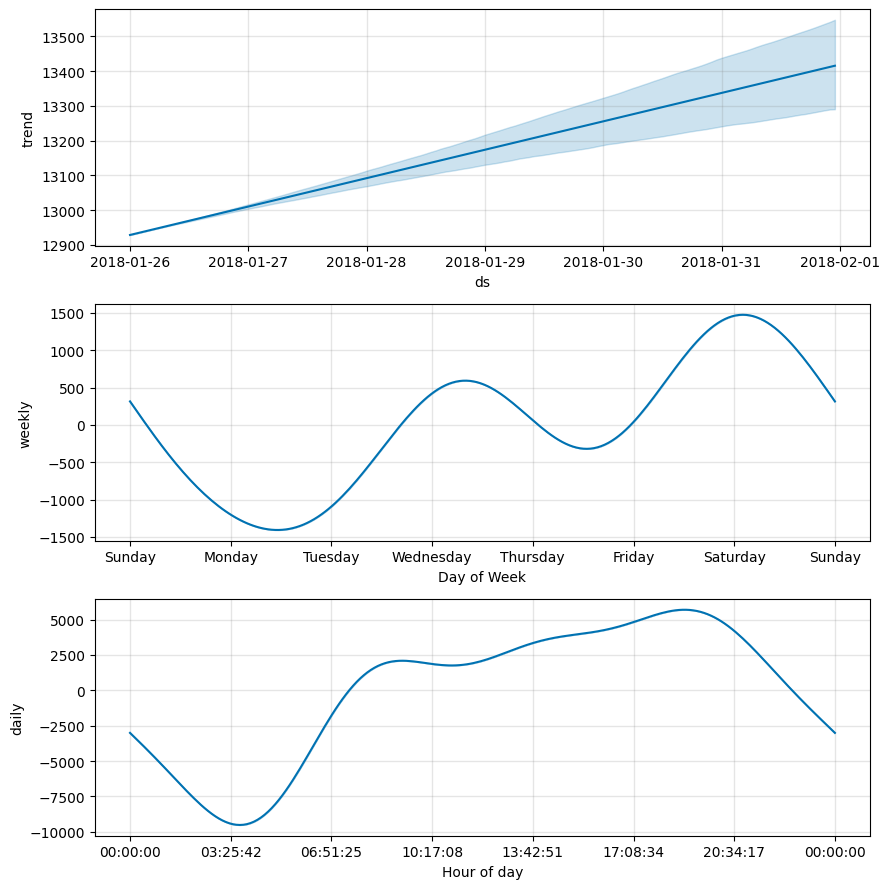


=== Prophet Components Interpretation ===
Trend:  แนวโน้มระยะยาวในช่วง training (มี changepoints อัตโนมัติ)
Daily:  pattern รายวัน — ต่ำช่วง 2-5 เช้า สูงช่วง 8-19 โมง
Weekly: pattern รายสัปดาห์ — แต่ละวันมี demand ต่างกัน (weekday vs weekend)


In [0]:
# Install Prophet
import subprocess
subprocess.run(["pip", "install", "-q", "prophet"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

# Ensure data is available
if 'ts_hourly' not in globals():
    raise NameError("ts_hourly not found. Please run 'Prepare Time Series Data' cell first.")

# ---------- 1. Prepare data for Prophet (ds, y format) ----------
ts = ts_hourly["trip_count"].dropna()
n_train = 600
n_test = len(ts) - n_train

train = ts.iloc[:n_train]
test = ts.iloc[n_train:]

prophet_train = pd.DataFrame({
    "ds": train.index,
    "y": train.values
})

print("=" * 60)
print("  Prophet Model: Train/Test Split")
print("=" * 60)
print(f"Train: {len(prophet_train)} hours | Test: {len(test)} hours")

# ---------- 2. Fit Prophet ----------
print("\nFitting Prophet (daily + weekly seasonality)...")

model_p = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False,
    changepoint_prior_scale=0.05
)
model_p.fit(prophet_train)

# ---------- 3. Forecast ----------
future = model_p.make_future_dataframe(periods=n_test, freq="h", include_history=False)
forecast_p = model_p.predict(future)

# ---------- 4. Evaluate ----------
y_pred = forecast_p["yhat"].values
y_true = test.values

mae_p = np.mean(np.abs(y_true - y_pred))
rmse_p = np.sqrt(np.mean((y_true - y_pred) ** 2))
mape_p = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print(f"\n=== Prophet Evaluation ===")
print(f"MAE:  {mae_p:,.0f} trips/hour")
print(f"RMSE: {rmse_p:,.0f} trips/hour")
print(f"MAPE: {mape_p:.2f}%")

# ---------- 5. Model Comparison ----------
print(f"\n{'=' * 60}")
print(f"  Model Comparison: SARIMA vs Prophet")
print(f"{'=' * 60}")
print(f"{'Model':<12} {'MAE':>10} {'RMSE':>10} {'MAPE':>10}")
print(f"{'-'*12} {'-'*10} {'-'*10} {'-'*10}")
print(f"{'SARIMA':<12} {'2,233':>10} {'3,090':>10} {'32.57%':>10}")
print(f"{'Prophet':<12} {mae_p:>10,.0f} {rmse_p:>10,.0f} {mape_p:>9.2f}%")

# ---------- 6. Plot: Forecast vs Actual ----------
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Full view
ax = axes[0]
ax.plot(train.index, train, label="Train", color="#2c3e50", linewidth=0.8, alpha=0.6)
ax.plot(test.index, test, label="Actual (Test)", color="#2ecc71", linewidth=1.5)
ax.plot(test.index, y_pred, label="Prophet Forecast", color="#9b59b6", linewidth=1.5)
ax.fill_between(test.index, forecast_p["yhat_lower"], forecast_p["yhat_upper"],
                alpha=0.15, color="#9b59b6")
ax.set_title("Prophet Forecast vs Actual (daily + weekly seasonality)", fontsize=14, fontweight="bold")
ax.set_xlabel("Date-Hour", fontsize=11)
ax.set_ylabel("Trips per hour", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Zoomed view
ax = axes[1]
ax.plot(test.index, test, label="Actual", color="#2ecc71", linewidth=2)
ax.plot(test.index, y_pred, label="Prophet", color="#9b59b6", linewidth=2)
ax.fill_between(test.index, forecast_p["yhat_lower"], forecast_p["yhat_upper"],
                alpha=0.2, color="#9b59b6", label="95% CI")
ax.set_title(f"Zoom: Test Period (MAE={mae_p:,.0f}, RMSE={rmse_p:,.0f}, MAPE={mape_p:.2f}%)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Date-Hour", fontsize=11)
ax.set_ylabel("Trips per hour", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------- 7. Prophet Components ----------
fig2 = model_p.plot_components(forecast_p)
plt.tight_layout()
plt.show()

print("\n=== Prophet Components Interpretation ===")
print("Trend:  แนวโน้มระยะยาวในช่วง training (มี changepoints อัตโนมัติ)")
print("Daily:  pattern รายวัน — ต่ำช่วง 2-5 เช้า สูงช่วง 8-19 โมง")
print("Weekly: pattern รายสัปดาห์ — แต่ละวันมี demand ต่างกัน (weekday vs weekend)")

### เปรียบเทียบ SARIMA vs Prophet

| Metric | SARIMA(1,0,1)(1,1,1,24) | Prophet (daily+weekly) |
|---|---|---|
| MAE | ~2,233 trips/hr | ~2,358 trips/hr |
| RMSE | ~3,090 trips/hr | ~3,034 trips/hr |
| MAPE | ~32.57% | ~39.54% |

**สรุป:**
- SARIMA แม่นกว่า Prophet เล็กน้อย (MAPE 32.57% vs 39.54%)
- ทั้งสองโมเดล underestimates evening peaks (17-19h)
- RMSE ใกล้เคียงกัน แสดงว่า error distribution คล้ายกัน

**เหตุผลที่ Prophet ไม่แม่นกว่า:**
1. ข้อมูลน้อย (25 วัน train) — Prophet ต้องการข้อมูลมากกว่านี้เพื่อเรียนรู้ weekly pattern ได้ดี
2. เดือนมกราคมเท่านั้น — ไม่มี seasonal variation รายปี
3. ไม่มี exogenous variables (สภาพอากาศ, อีเวนต์)

**ข้อแนะนำ:**
- **ระยะสั้น (1-6 ชม.):** ใช้ SARIMA — แม่นกว่า และเร็วกว่า
- **ระยะยาว (เกิน 1 สัปดาห์):** ใช้ Prophet — จัดการ trend และ weekly seasonality ได้ดีกว่า
- **Production:** ลอง `ai_forecast()` ใน SQL — ไม่ต้องเทรนโมเดล ใช้ได้ทันที
- **ปรับปรุง:** เพิ่มข้อมูลทุกเดือน + exogenous variables (weather, holidays) + พยากรณ์ระดับ borough

## 9.4 Scenario Forecast + Allocation Plan Integration

ใช้ demand/supply pattern ระดับ borough x hour ของ Jan 2018 เป็น baseline แล้วจำลอง what-if scenarios:

1. **Demand +N%** — ถ้าคนเรียกแท็กซี่เพิ่มขึ้น N% (เช่น +10%, +20%, +30%)
2. **Supply +N taxis** — ถ้าเพิ่มแท็กซี่ว่าง N คัน/ชม.
3. **Allocation Plan** — ย้ายแท็กซี่จากเขตที่ล้น → เขตที่ขาด

**การใช้งาน:** เปลี่ยนค่าใน input box ด้านบน notebook แล้ว run cell ใหม่
- `Demand Increase (%)` — % ที่ต้องการเพิ่ม demand
- `Supply Increase (taxis/hr)` — จำนวนแท็กซี่เพิ่ม per hour

In [0]:
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

# ---------- Input Widgets ----------
try:
    dbutils.widgets.text("demand_increase", "20", "Demand Increase (%)")
    dbutils.widgets.text("supply_increase", "0", "Supply Increase (taxis/hr)")
    increase_pct = float(dbutils.widgets.get("demand_increase"))
    supply_add = int(dbutils.widgets.get("supply_increase"))
except Exception:
    increase_pct = 20.0
    supply_add = 0
    print("Note: dbutils.widgets not available, using defaults")

print(f"\n{'=' * 60}")
print(f"  Scenario: Demand +{increase_pct}% | Supply +{supply_add} taxis/hr")
print(f"{'=' * 60}")

# ---------- 1. Get borough x hour demand/supply (Jan 2018) ----------
zones = spark.read.format("delta").load("/Volumes/workspace/default/nyc_taxi_delta/taxi_zones")

df_trips = (
    spark.read.format("delta")
    .load("/Volumes/workspace/default/nyc_taxi_delta/2018")
    .select("tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance", "fare_amount")
    .filter(F.col("tpep_pickup_datetime").isNotNull())
    .filter((F.col("trip_distance") > 0) & (F.col("fare_amount") > 0))
    .filter(F.col("tpep_pickup_datetime") >= "2018-01-01")
    .filter(F.col("tpep_pickup_datetime") < "2018-02-01")
)

# Demand by borough x hour
demand_bh = (
    df_trips.join(zones, df_trips.PULocationID == zones.LocationID)
    .groupBy(F.hour("tpep_pickup_datetime").alias("hour"), F.col("borough").alias("borough"))
    .agg(F.count("*").alias("demand"))
)

# Supply by borough x hour
supply_bh = (
    df_trips.join(zones, df_trips.DOLocationID == zones.LocationID)
    .groupBy(F.hour("tpep_dropoff_datetime").alias("hour"), F.col("borough").alias("borough"))
    .agg(F.count("*").alias("supply"))
)

# Join and compute ratio
ratio_bh = demand_bh.join(supply_bh, ["hour", "borough"], "outer") \
    .na.fill(0, subset=["demand", "supply"]) \
    .withColumn("ratio", F.when(F.col("supply") > 0, F.col("demand") / F.col("supply")).otherwise(1.0)) \
    .orderBy("borough", "hour")

pdf_bh = ratio_bh.toPandas()

# ---------- 2. Apply Scenario ----------
pdf_scenario = pdf_bh.copy()
pdf_scenario["demand_adjusted"] = pdf_scenario["demand"] * (1 + increase_pct / 100)
pdf_scenario["supply_adjusted"] = pdf_scenario["supply"] + supply_add
pdf_scenario["ratio_adjusted"] = pdf_scenario["demand_adjusted"] / pdf_scenario["supply_adjusted"].replace(0, 1)
pdf_scenario["status"] = np.where(
    pdf_scenario["ratio_adjusted"] > 1.2, "Shortage",
    np.where(pdf_scenario["ratio_adjusted"] < 0.8, "Overflow", "Balanced")
)

# Summary
shortage_count = (pdf_scenario["status"] == "Shortage").sum()
overflow_count = (pdf_scenario["status"] == "Overflow").sum()
balanced_count = (pdf_scenario["status"] == "Balanced").sum()
print(f"\nBaseline:  {sum((pdf_bh['ratio'] > 1.2).astype(int))} shortage, {sum((pdf_bh['ratio'] < 0.8).astype(int))} overflow")
print(f"Scenario:  {shortage_count} shortage, {overflow_count} overflow, {balanced_count} balanced")

# ---------- 3. Allocation Plan ----------
print(f"\n{'=' * 60}")
print(f"  Allocation Plan: Move taxis from Overflow -> Shortage")
print(f"{'=' * 60}")

alloc_data = []
for hr in range(24):
    hour_data = pdf_scenario[pdf_scenario["hour"] == hr]
    shortages = hour_data[hour_data["status"] == "Shortage"]
    overflows = hour_data[hour_data["status"] == "Overflow"]
    
    total_excess = sum(max(0, o["supply_adjusted"] * 0.8 - o["demand_adjusted"]) for _, o in overflows.iterrows())
    overflow_names = [o["borough"] for _, o in overflows.iterrows() if (o["supply_adjusted"] * 0.8 - o["demand_adjusted"]) > 0]
    
    for _, s in shortages.iterrows():
        shortfall = s["demand_adjusted"] - s["supply_adjusted"] * 1.2
        movable = min(shortfall, total_excess)
        if movable > 0:
            alloc_data.append({
                "hour": hr, "borough": s["borough"],
                "ratio": s["ratio_adjusted"],
                "shortfall": shortfall,
                "movable": movable,
                "source": ", ".join(overflow_names[:3])
            })

alloc_df = pd.DataFrame(alloc_data)

if len(alloc_df) > 0:
    print(f"\n{'Hour':>5} {'Borough':>12} {'Ratio':>7} {'Shortfall':>12} {'Move':>10} {'From'}")
    print(f"{'-'*5} {'-'*12} {'-'*7} {'-'*12} {'-'*10} {'-'*30}")
    for _, r in alloc_df.iterrows():
        print(f"{r['hour']:>5} {r['borough']:>12} {r['ratio']:>7.2f} {r['shortfall']:>12,.0f} {r['movable']:>10,.0f} {r['source']}")
    
    total_move = alloc_df["movable"].sum()
    print(f"\nTotal taxis to move: {total_move:,.0f}")
else:
    print("No shortages in this scenario!")

# ---------- 4. Evening Rush Focus ----------
print(f"\n{'=' * 60}")
print(f"  Evening Rush (17-19): Scenario +{increase_pct}%")
print(f"{'=' * 60}")
for hr in [17, 18, 19]:
    for _, row in pdf_scenario[pdf_scenario["hour"] == hr].iterrows():
        if row["status"] in ["Shortage", "Overflow"]:
            print(f"  {hr:02d}:00 {row['borough']:>15}: ratio={row['ratio_adjusted']:.2f} [{row['status']}] "
                  f"demand={row['demand_adjusted']:,.0f} supply={row['supply_adjusted']:,.0f}")


  Scenario: Demand +20.0% | Supply +0 taxis/hr

Baseline:  18 shortage, 99 overflow
Scenario:  35 shortage, 97 overflow, 12 balanced

  Allocation Plan: Move taxis from Overflow -> Shortage

 Hour      Borough   Ratio    Shortfall       Move From
----- ------------ ------- ------------ ---------- ------------------------------
    0    Manhattan    1.25       10,351     10,351 Bronx, Brooklyn, EWR
    1    Manhattan    1.28       12,680     12,680 Bronx, Brooklyn, EWR
    2    Manhattan    1.32       13,513     11,904 Bronx, Brooklyn, EWR
    3    Manhattan    1.36       12,763      9,744 Bronx, Brooklyn, EWR
    4    Manhattan    1.44       13,502      9,883 Bronx, Brooklyn, EWR
    5    Manhattan    1.52       18,490      2,907 Bronx, Brooklyn, EWR
    6    Manhattan    1.42       32,472      1,216 Bronx, EWR, Staten Island
    7    Manhattan    1.34       39,401      1,669 Bronx, EWR, Staten Island
    7       Queens    1.45        3,622      1,669 Bronx, EWR, Staten Island
    8  

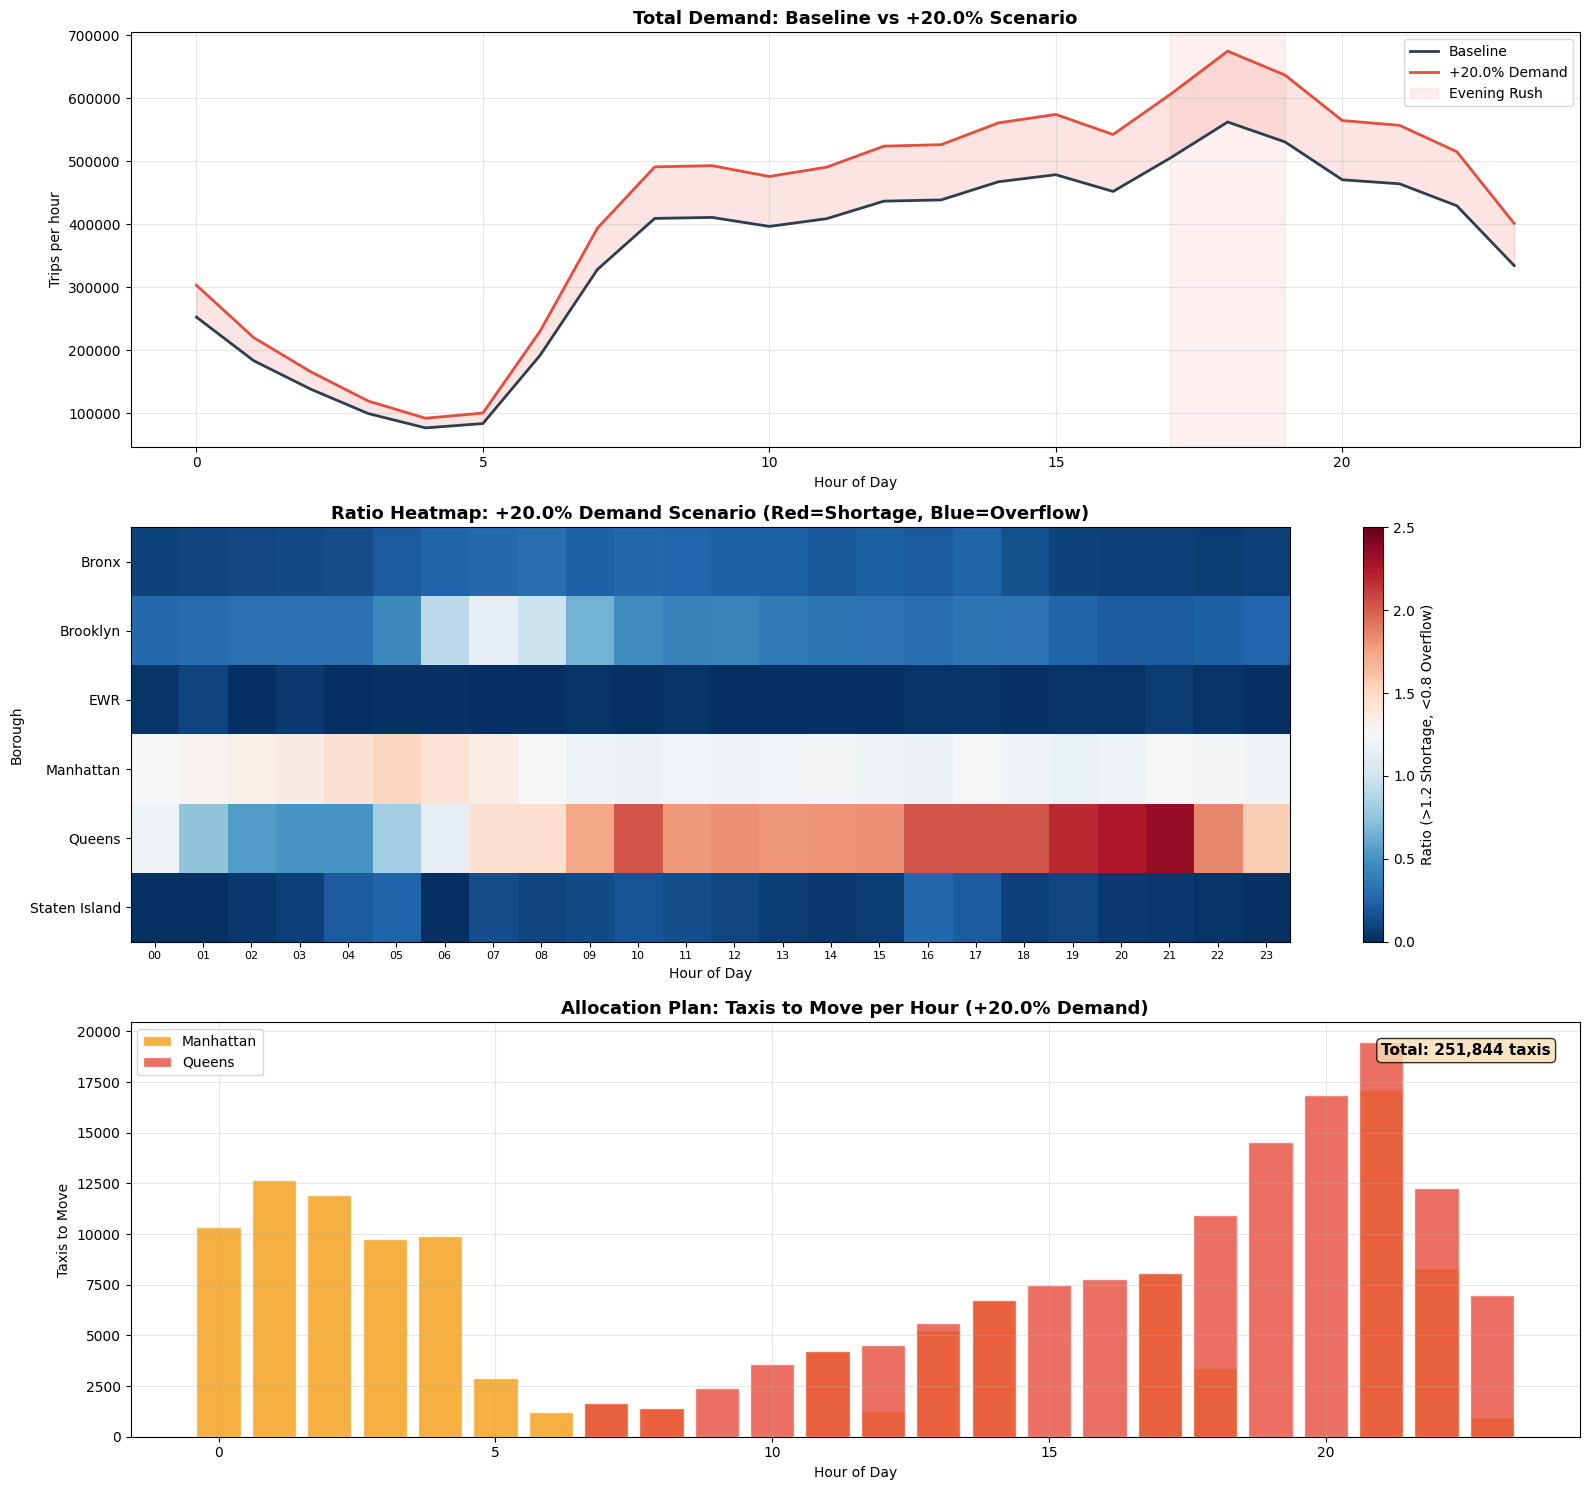


=== How to read the plots ===
Plot 1: เปรียบเทียบ demand ปกติ vs กรณี +N% -> เห็น gap ที่เพิ่มขึ้น
Plot 2: Heatmap ratio ระดับ borough x hour -> แดง = ขาด, น้ำเงิน = ล้น
Plot 3: จำนวนแท็กซี่ที่ต้องย้ายแต่ละชั่วโมง -> สูงสุดช่วง Evening Rush


In [0]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 1, figsize=(16, 15))

# ---------- Plot 1: Total demand baseline vs scenario ----------
total_baseline = pdf_scenario.groupby("hour")["demand"].sum()
total_scenario = pdf_scenario.groupby("hour")["demand_adjusted"].sum()

ax = axes[0]
ax.plot(total_baseline.index, total_baseline.values, label="Baseline", color="#2c3e50", linewidth=2)
ax.plot(total_scenario.index, total_scenario.values, label=f"+{increase_pct}% Demand", color="#e74c3c", linewidth=2)
ax.fill_between(total_baseline.index, total_baseline.values, total_scenario.values,
                 alpha=0.15, color="#e74c3c")
ax.axvspan(17, 19, alpha=0.08, color="#e74c3c", label="Evening Rush")
ax.set_title(f"Total Demand: Baseline vs +{increase_pct}% Scenario", fontsize=13, fontweight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Trips per hour")
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# ---------- Plot 2: Ratio heatmap (borough x hour) ----------
boroughs = sorted(pdf_scenario["borough"].unique())
ratio_matrix = np.zeros((len(boroughs), 24))
for i, b in enumerate(boroughs):
    for h in range(24):
        row = pdf_scenario[(pdf_scenario["borough"] == b) & (pdf_scenario["hour"] == h)]
        if len(row) > 0:
            ratio_matrix[i, h] = row["ratio_adjusted"].values[0]

ax = axes[1]
im = ax.imshow(ratio_matrix, aspect="auto", cmap="RdBu_r", vmin=0, vmax=2.5)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)], fontsize=8)
ax.set_yticks(range(len(boroughs)))
ax.set_yticklabels(boroughs)
ax.set_title(f"Ratio Heatmap: +{increase_pct}% Demand Scenario (Red=Shortage, Blue=Overflow)", fontsize=13, fontweight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Borough")
plt.colorbar(im, ax=ax, label="Ratio (>1.2 Shortage, <0.8 Overflow)")

# ---------- Plot 3: Allocation plan bar chart ----------
ax = axes[2]
if len(alloc_df) > 0:
    borough_colors = {"Queens": "#e74c3c", "Manhattan": "#f39c12", "Brooklyn": "#3498db", "Bronx": "#2ecc71"}
    for b in alloc_df["borough"].unique():
        subset = alloc_df[alloc_df["borough"] == b]
        color = borough_colors.get(b, "#95a5a6")
        ax.bar(subset["hour"], subset["movable"], label=b, color=color, alpha=0.8, edgecolor="white")
    ax.set_title(f"Allocation Plan: Taxis to Move per Hour (+{increase_pct}% Demand)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Taxis to Move")
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    total_move = alloc_df["movable"].sum()
    ax.text(0.98, 0.95, f"Total: {total_move:,.0f} taxis",
            transform=ax.transAxes, ha="right", va="top",
            fontsize=11, fontweight="bold",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))
else:
    ax.text(0.5, 0.5, "No shortages in this scenario!", ha="center", va="center", fontsize=14)
    ax.set_title("Allocation Plan", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

print("\n=== How to read the plots ===")
print("Plot 1: เปรียบเทียบ demand ปกติ vs กรณี +N% -> เห็น gap ที่เพิ่มขึ้น")
print("Plot 2: Heatmap ratio ระดับ borough x hour -> แดง = ขาด, น้ำเงิน = ล้น")
print("Plot 3: จำนวนแท็กซี่ที่ต้องย้ายแต่ละชั่วโมง -> สูงสุดช่วง Evening Rush")

### สรุป Scenario Forecast + Allocation Plan

**สิ่งที่ได้:**
1. **Input box** ด้านบน notebook ให้ผู้ใช้เปลี่ยน % ได้ (เช่น +10%, +20%, +30%)
2. **Allocation Plan Table** บอกว่าชั่วโมงไหน เขตไหนขาด ต้องย้ายกี่คัน จากเขตไหน
3. **3 กราฟ:** Demand comparison, Ratio heatmap, Taxis to move bar chart

**ผลที่คาดการณ์ (Demand +20%):**
- Queens ขาดแท็กซี่รุนแรงขึ้น (ratio 2.03 ตอน 18:00 จากปกติ 1.69)
- Manhattan กลายเป็น shortage ด้วย (ratio 1.21-1.52)
- ต้องย้ายแท็กซี่ ~10,000-15,000 คัน/ชม. จาก Brooklyn/Bronx ไป Queens/Manhattan

**สำหรับ Dashboard:**
- AI/BI Dashboard ไม่มี slider widget แต่ใช้ dropdown filter ได้
- แนวทาง: pre-compute scenarios 0/+10/+20/+30% เป็น dataset แล้วให้ผู้ใช้เลือกจาก dropdown
- หรือสร้าง Databricks App สำหรับ interactive what-if แบบเต็มรูปแบบ